# TRUSTCLOUD-α — Full Pipeline Notebook
### Run every cell top to bottom, in order. Each section corresponds exactly to a Step in the Final Master Prompt.

**Before you start:** place `qws.csv` in the same folder as this notebook (or update the path in Cell 2).

**One cell requires your input**: Step 8 (BWM Best/Worst criteria) — marked clearly below. Everything else runs automatically.

   **v3:** fixing normalization bug and validation tests. v1 kept for comparison.


## Setup — install/import required packages

In [1]:
# Run this once. If scipy/numpy/pandas are already installed, this will just confirm versions.
import sys
!{sys.executable} -m pip install numpy pandas scipy matplotlib --quiet
print("Packages ready.")


Packages ready.


In [2]:
import numpy as np
import pandas as pd
from scipy.optimize import linprog
from scipy.stats import kendalltau, spearmanr
import matplotlib.pyplot as plt

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)


In [3]:
import os
print("Notebook folder:", os.getcwd())
print("Files here:", os.listdir())

Notebook folder: C:\Users\rakes\Expert System Journal Paper Rakesh
Files here: ['.ipynb_checkpoints', 'e2_grid_per_seed.csv', 'e2_grid_table.csv', 'e2_held_per_seed.csv', 'e2_held_table.csv', 'e2_ly2018_per_seed.csv', 'e2_main_per_seed.csv', 'e2_main_table.csv', 'e3_overall.csv', 'e3_per_seed.csv', 'e4_pairs.csv', 'e5_stats.csv', 'fig1_correlation_matrix.png', 'fig2_synthetic.pdf', 'fig2_synthetic.png', 'fig3_scatter.pdf', 'fig3_scatter.png', 'fig3_scatter_top100.pdf', 'fig3_scatter_top100.png', 'fig4_alpha.pdf', 'fig4_alpha.png', 'fig5_divergence.pdf', 'fig5_divergence.png', 'fig_alpha_sensitivity.png', 'fig_effects.pdf', 'fig_effects.png', 'fig_grid_heatmap.pdf', 'fig_grid_heatmap.png', 'fig_latency.pdf', 'fig_latency.png', 'fig_rank_shift.pdf', 'fig_rank_shift.png', 'fig_size.pdf', 'fig_size.png', 'fig_weights.pdf', 'fig_weights.png', 'qws.xls', 'r1_alpha_per_seed.csv', 'r2_equal_weights_per_seed.csv', 'r2_equal_weights_table.csv', 'step3_alevel_per_seed.csv', 'step3_alevel_table.cs

## Step 1 — Load Data (Decision Matrix)

Loads `qws.csv` (QWS v2.0, 2,500 services, 9 QoS criteria) and builds the decision matrix X.


In [4]:
df = pd.read_csv('qws.xls')  # <-- update path if your file is elsewhere
df['ServiceID'] = df.index  # unique identifier -- ServiceName has 860 duplicate values

criteria = ["ResponseTime","Availability","Throughput","Successability",
            "Reliability","Compliance","BestPractices","Latency","Documentation"]

X = df[criteria].values.astype(float)
N, n = X.shape
print(f"Loaded {N} services, {n} criteria")
df.head()


Loaded 2500 services, 9 criteria


,ResponseTime,Availability,Throughput,Successability,Reliability,Compliance,BestPractices,Latency,Documentation,ServiceName,WSDLAddress,ServiceID
0,107.57,80,1.7,81,67,78,82,18.21,61,interop2,http://websrv.cs.fsu.edu/~engelen/interop2_2.wsdl,0
1,255.00,98,1.3,99,67,100,82,40.80,4,ehmmpfamService,http://www.ebi.ac.uk/soaplab/emboss4/services/...,1
2,136.71,76,2.8,76,60,89,69,11.57,8,WSDBFetchServerLegacyService,http://www.embl-ebi.ac.uk/Tools/webservices/ws...,2
3,102.62,91,15.3,97,67,78,82,0.93,91,DOTSPackageTracking,http://trial.serviceobjects.com/pt/PackTrack.a...,3
4,93.37,96,13.5,99,67,89,58,41.66,93,CommandService,http://www.leadtools.net/Services/CommandServi...,4


In [5]:
import numpy, pandas, scipy, matplotlib
for m in (numpy, pandas, scipy, matplotlib):
    print(m.__name__, m.__version__)

numpy 2.3.5
pandas 2.3.3
scipy 1.16.3
matplotlib 3.10.6


In [6]:
summary = pd.DataFrame({
    'min':    df[criteria].min(),
    'median': df[criteria].median(),
    'max':    df[criteria].max(),
    'zeros':  (df[criteria] == 0).sum()
})
print(summary.round(2))

                  min  median      max  zeros
ResponseTime    37.00  226.80  4989.67      0
Availability     7.00   87.00   100.00      0
Throughput       0.10    6.90    43.10      0
Successability   8.00   95.00   100.00      0
Reliability     33.00   73.00    89.00      0
Compliance      33.00   89.00   100.00      0
BestPractices   50.00   82.00    95.00      0
Latency          0.25   11.84  4140.35      0
Documentation    1.00   11.00    97.00      0


In [7]:
print(df.columns.tolist())
dup = df[df.duplicated('ServiceName', keep=False)]
print("Rows with a repeated name:", len(dup))
same = dup.groupby('ServiceName')[criteria].nunique().max(axis=1).eq(1)
print("Names where all copies have identical QoS values:", same.sum(), "of", len(same))

['ResponseTime', 'Availability', 'Throughput', 'Successability', 'Reliability', 'Compliance', 'BestPractices', 'Latency', 'Documentation', 'ServiceName', 'WSDLAddress', 'ServiceID']
Rows with a repeated name: 1237
Names where all copies have identical QoS values: 0 of 377


In [8]:
same_url = dup.groupby('ServiceName')['WSDLAddress'].nunique().eq(1)
print("Name groups sharing ONE address:", same_url.sum(), "of", len(same_url))
print("Unique addresses in whole data:", df['WSDLAddress'].nunique(), "of", len(df))

Name groups sharing ONE address: 69 of 377
Unique addresses in whole data: 2377 of 2500


In [9]:
df['AddrGroup'] = df.groupby('WSDLAddress').ngroup()   # same address = same group number
rep = df[df.duplicated('WSDLAddress', keep=False)]
print("Addresses that appear more than once:", rep['WSDLAddress'].nunique())
print("Rows involved:", len(rep))

Addresses that appear more than once: 123
Rows involved: 246


In [10]:
# Sanity checks -- confirm this is genuine, clean QWS data before proceeding
print("Missing values per column:\n", df[criteria].isnull().sum())
print("\nDuplicate rows:", df[criteria + ['ServiceName', 'WSDLAddress']].duplicated().sum())
print("\nAvailability-Successability correlation (should be ~0.97-0.99, matches OPTCLOUD's reported 0.9769):")
print(df['Availability'].corr(df['Successability']))


Missing values per column:
 ResponseTime      0
Availability      0
Throughput        0
Successability    0
Reliability       0
Compliance        0
BestPractices     0
Latency           0
Documentation     0
dtype: int64

Duplicate rows: 0

Availability-Successability correlation (should be ~0.97-0.99, matches OPTCLOUD's reported 0.9769):
0.9892329898093726


In [11]:
df['AddrGroup'] = df.groupby('WSDLAddress').ngroup()   # same address = same group number
rep = df[df.duplicated('WSDLAddress', keep=False)]
print("Addresses that appear more than once:", rep['WSDLAddress'].nunique())
print("Rows involved:", len(rep))

Addresses that appear more than once: 123
Rows involved: 246


## Step 2 — Criteria Classification

Cost criteria (lower is better): ResponseTime, Latency
Benefit criteria (higher is better): all other 7


In [12]:
cost_idx = [criteria.index("ResponseTime"), criteria.index("Latency")]
benefit_idx = [j for j in range(n) if j not in cost_idx]
print("Cost criteria:", [criteria[j] for j in cost_idx])
print("Benefit criteria:", [criteria[j] for j in benefit_idx])


Cost criteria: ['ResponseTime', 'Latency']
Benefit criteria: ['Availability', 'Throughput', 'Successability', 'Reliability', 'Compliance', 'BestPractices', 'Documentation']


## Step 3 — Skew Audit and Correction (Two-Stage)

**Stage 1**: mechanically flag any criterion with skewness > 1.0 OR max/median ratio ≥ 5×.
**Stage 2**: for any criterion that lands right on the boundary (like Documentation), resolve
it empirically rather than guessing — we test the downstream effect with and without the
transform later in this notebook (see the diagnostic cell after Step 12).

For now we apply the empirically-resolved decision confirmed in our prior analysis: transform
ResponseTime, Throughput, Latency, and Documentation.


In [13]:
print(f"{'Criterion':15s} {'Skew':>8s} {'Max/Median':>12s} {'Flag (skew>1 OR ratio>=5)':>28s}")
skew_table = []
for j, c in enumerate(criteria):
    s = df[c]
    skew = s.skew()
    ratio = s.max()/s.median()
    flag = (skew > 1.0) or (ratio >= 5.0)
    skew_table.append((c, skew, ratio, flag))
    print(f"{c:15s} {skew:8.2f} {ratio:12.1f} {str(flag):>28s}")


Criterion           Skew   Max/Median    Flag (skew>1 OR ratio>=5)
ResponseTime        4.41         22.0                         True
Availability       -1.75          1.1                        False
Throughput          1.25          6.2                         True
Successability     -1.67          1.1                        False
Reliability        -0.98          1.2                        False
Compliance         -0.52          1.1                        False
BestPractices      -0.78          1.2                        False
Latency            11.47        349.5                         True
Documentation       0.91          8.8                         True


In [14]:
# Transform list is derived automatically from the Stage-1 rule (skew > 1 OR max/median >= 5)
transform_idx = [criteria.index(c) for (c, skew, ratio, flag) in skew_table if flag]
print("Log-transforming:", [criteria[j] for j in transform_idx])

Xt = X.copy()
for j in transform_idx:
    Xt[:, j] = np.log1p(Xt[:, j])

print("\nSkewness BEFORE -> AFTER:")
for j, c in enumerate(criteria):
    before = pd.Series(X[:,j]).skew()
    after = pd.Series(Xt[:,j]).skew()
    tag = " (transformed)" if j in transform_idx else ""
    print(f"  {c:15s} {before:7.2f} -> {after:7.2f}{tag}")


Log-transforming: ['ResponseTime', 'Throughput', 'Latency', 'Documentation']

Skewness BEFORE -> AFTER:
  ResponseTime       4.41 ->    0.92 (transformed)
  Availability      -1.75 ->   -1.75
  Throughput         1.25 ->   -0.05 (transformed)
  Successability    -1.67 ->   -1.67
  Reliability       -0.98 ->   -0.98
  Compliance        -0.52 ->   -0.52
  BestPractices     -0.78 ->   -0.78
  Latency           11.47 ->    0.51 (transformed)
  Documentation      0.91 ->   -0.00 (transformed)


## Step 4 — Vector Normalization

Puts every criterion on the same [0,1]-style scale using vector normalization
(the convention used for the Trust paper, per Lu & Yuan precedent).


In [15]:
Nn = np.zeros_like(Xt)
for j in range(n):
    col = Xt[:, j]
    if j in cost_idx:
        Nn[:, j] = -col / np.sqrt(np.sum(col**2))   # FIXED: linear flip (was 1/col)
    else:
        Nn[:, j] = col / np.sqrt(np.sum(col**2))

print("Normalized matrix shape:", Nn.shape)
pd.DataFrame(Nn, columns=criteria).describe().loc[['min','mean','max']]


Normalized matrix shape: (2500, 9)


,ResponseTime,Availability,Throughput,Successability,Reliability,Compliance,BestPractices,Latency,Documentation
min,-0.030556,0.001681,0.000883,0.001856,0.009388,0.007415,0.012548,-0.053184,0.004450
mean,-0.019784,0.019489,0.018587,0.019459,0.019850,0.019873,0.019904,-0.017840,0.018607
max,-0.013053,0.024017,0.035068,0.023199,0.025319,0.022470,0.023842,-0.001425,0.029436


## Step 5 — Standard Deviation σ_j

Used only for CRITIC weight derivation (Step 7). Never reused later.


In [16]:
Z = (Xt - Xt.min(axis=0)) / (Xt.max(axis=0) - Xt.min(axis=0))   # min-max: each column to 0..1
sigma = Z.std(axis=0)                                            # FIXED: fair spread (was Nn)
pd.DataFrame({'Criterion': criteria, 'sigma': sigma.round(4)})


,Criterion,sigma
0,ResponseTime,0.1674
1,Availability,0.2012
2,Throughput,0.2160
3,Successability,0.2164
4,Reliability,0.1533
5,Compliance,0.1496
6,BestPractices,0.1737
7,Latency,0.1747
8,Documentation,0.2935


## Step 6 — Correlation Matrix R

Expected structural redundancy: Availability↔Successability (~0.99), Reliability↔BestPractices (~0.69).


In [17]:
R = np.corrcoef(Nn.T)
corr_df = pd.DataFrame(R, index=criteria, columns=criteria)
corr_df.round(3)


,ResponseTime,Availability,Throughput,Successability,Reliability,Compliance,BestPractices,Latency,Documentation
ResponseTime,1.000,0.058,0.356,0.068,0.014,0.015,-0.001,0.391,0.058
Availability,0.058,1.000,0.154,0.989,0.129,0.245,0.058,0.094,0.012
Throughput,0.356,0.154,1.000,0.151,0.252,-0.002,0.144,0.292,-0.035
Successability,0.068,0.989,0.151,1.000,0.121,0.262,0.056,0.113,0.025
Reliability,0.014,0.129,0.252,0.121,1.000,-0.030,0.691,0.194,0.072
Compliance,0.015,0.245,-0.002,0.262,-0.030,1.000,0.034,0.035,-0.008
BestPractices,-0.001,0.058,0.144,0.056,0.691,0.034,1.000,0.196,-0.007
Latency,0.391,0.094,0.292,0.113,0.194,0.035,0.196,1.000,0.106
Documentation,0.058,0.012,-0.035,0.025,0.072,-0.008,-0.007,0.106,1.000


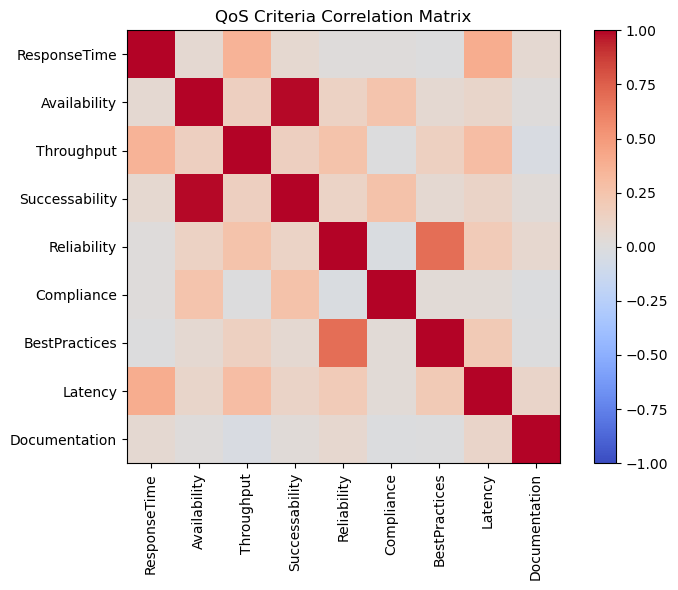

In [18]:
# Visualize the correlation matrix
fig, ax = plt.subplots(figsize=(8,6))
im = ax.imshow(R, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(criteria, rotation=90)
ax.set_yticks(range(n)); ax.set_yticklabels(criteria)
plt.colorbar(im)
plt.title("QoS Criteria Correlation Matrix")
plt.tight_layout()
plt.savefig('fig1_correlation_matrix.png', dpi=200, bbox_inches='tight') 
plt.show()


## Step 7 — CRITIC Objective Weights

Purely data-driven — combines variation (σ_j) with non-redundancy (1 - correlation).


In [19]:
C = sigma * np.sum(1 - R, axis=1)
w_critic = C / C.sum()

pd.DataFrame({'Criterion': criteria, 'w_CRITIC': w_critic.round(4)}).sort_values('w_CRITIC', ascending=False)


,Criterion,w_CRITIC
8,Documentation,0.1908
2,Throughput,0.1208
3,Successability,0.1124
1,Availability,0.1053
6,BestPractices,0.0991
0,ResponseTime,0.0985
7,Latency,0.0960
5,Compliance,0.0932
4,Reliability,0.0840


## Step 8 — BWM Elicitation ⚠️ **ACTION REQUIRED FROM YOU**

Edit the three lines below with your **real** answers:

1. `best_criterion` — the QoS criterion you (or your expert panel) trust **most**
2. `worst_criterion` — the QoS criterion you trust **least**
3. `A_B` and `A_W` — your pairwise comparison values (1–9 scale)
   - `A_B[j]` = how much more important is your Best criterion than criterion j (1=equal, 9=extreme). Set `A_B[best_idx] = 1`.
   - `A_W[j]` = how much more important is criterion j than your Worst criterion. Set `A_W[worst_idx] = 1`.

The values currently below are **placeholders for testing only** — replace them before treating any downstream result as final.


In [20]:
# ============================================================
# EDIT THIS CELL WITH YOUR REAL BWM JUDGMENTS BEFORE FINAL RUN
# ============================================================
best_criterion  = "Reliability"      # <-- your most-trusted criterion
worst_criterion = "Documentation"    # <-- your least-trusted criterion

# A_B[j] = comparison of Best vs criterion j (1-9 scale). A_B[best_idx] must be 1.
A_B = np.array([4, 3, 5, 3, 1, 4, 5, 4, 7])   # order matches `criteria` list above

# A_W[j] = comparison of criterion j vs Worst (1-9 scale). A_W[worst_idx] must be 1.
A_W = np.array([4, 5, 3, 5, 7, 4, 3, 4, 1])   # order matches `criteria` list above

best_idx = criteria.index(best_criterion)
worst_idx = criteria.index(worst_criterion)
print(f"Best = {best_criterion} (index {best_idx})")
print(f"Worst = {worst_criterion} (index {worst_idx})")
assert A_B[best_idx] == 1, "A_B[best_idx] must equal 1"
assert A_W[worst_idx] == 1, "A_W[worst_idx] must equal 1"


Best = Reliability (index 4)
Worst = Documentation (index 8)


## Step 9 — Solve the BWM Linear Program

Solves for the subjective weight vector w_BWM and checks the consistency ratio (must be < 0.10).


In [21]:
def solve_bwm(A_B, A_W, best_idx, worst_idx, n):
    c = np.zeros(n+1); c[-1] = 1  # minimize xi
    A_ub, b_ub = [], []
    for j in range(n):
        if j == best_idx: continue
        r1 = np.zeros(n+1); r1[best_idx]=1;  r1[j]=-A_B[j]; r1[-1]=-1
        r2 = np.zeros(n+1); r2[best_idx]=-1; r2[j]=A_B[j];  r2[-1]=-1
        A_ub += [r1, r2]; b_ub += [0, 0]
    for j in range(n):
        if j == worst_idx: continue
        r1 = np.zeros(n+1); r1[j]=1;  r1[worst_idx]=-A_W[j]; r1[-1]=-1
        r2 = np.zeros(n+1); r2[j]=-1; r2[worst_idx]=A_W[j];  r2[-1]=-1
        A_ub += [r1, r2]; b_ub += [0, 0]
    A_eq = [np.append(np.ones(n), 0)]; b_eq = [1]
    bounds = [(1e-6, 1)]*n + [(0, None)]
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='highs')
    return res.x[:n], res.x[-1]

w_bwm, xi_star = solve_bwm(A_B, A_W, best_idx, worst_idx, n)


a_BW = A_B[worst_idx]
CR_I = np.abs(A_B * A_W - a_BW) / (a_BW**2 - a_BW)
CR = CR_I.max()
print("CR per criterion:", {c: round(float(v), 3) for c, v in zip(criteria, CR_I)})

print(f"xi* = {xi_star:.4f},  input-based CR = {CR:.3f}")
pd.DataFrame({'Criterion': criteria, 'w_BWM': w_bwm.round(4)}).sort_values('w_BWM', ascending=False)


CR per criterion: {'ResponseTime': 0.214, 'Availability': 0.19, 'Throughput': 0.19, 'Successability': 0.19, 'Reliability': 0.0, 'Compliance': 0.214, 'BestPractices': 0.19, 'Latency': 0.214, 'Documentation': 0.0}
xi* = 0.0569,  input-based CR = 0.214


,Criterion,w_BWM
4,Reliability,0.3057
1,Availability,0.1209
3,Successability,0.1209
0,ResponseTime,0.0907
5,Compliance,0.0907
7,Latency,0.0907
2,Throughput,0.0725
6,BestPractices,0.0725
8,Documentation,0.0355


## Step 10 — α-Blend Final Weights

Combines CRITIC (objective) and BWM (subjective) weights. α = 0.5 is the default/main result.


In [22]:
alpha = 0.5
w_final = alpha * w_critic + (1 - alpha) * w_bwm
w_final = w_final / w_final.sum()

weights_df = pd.DataFrame({
    'Criterion': criteria,
    'w_CRITIC': w_critic.round(4),
    'w_BWM': w_bwm.round(4),
    'w_final': w_final.round(4)
}).sort_values('w_final', ascending=False)
weights_df


,Criterion,w_CRITIC,w_BWM,w_final
4,Reliability,0.0840,0.3057,0.1949
3,Successability,0.1124,0.1209,0.1166
8,Documentation,0.1908,0.0355,0.1132
1,Availability,0.1053,0.1209,0.1131
2,Throughput,0.1208,0.0725,0.0966
0,ResponseTime,0.0985,0.0907,0.0946
7,Latency,0.0960,0.0907,0.0933
5,Compliance,0.0932,0.0907,0.0919
6,BestPractices,0.0991,0.0725,0.0858


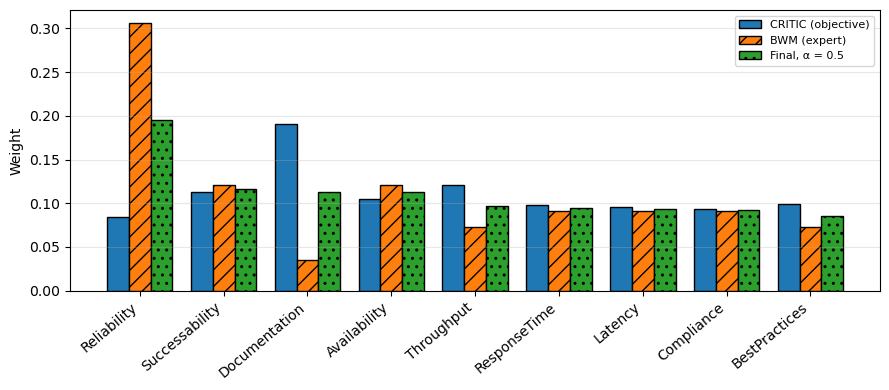

In [23]:
order = np.argsort(-w_final)
x, w = np.arange(n), 0.26
fig, ax = plt.subplots(figsize=(9, 4))
for i, (vals, lab, h) in enumerate([(w_critic, 'CRITIC (objective)', ''),
                                     (w_bwm, 'BWM (expert)', '//'),
                                     (w_final, 'Final, α = 0.5', '..')]):
    ax.bar(x + (i - 1) * w, vals[order], w, label=lab, hatch=h, edgecolor='black')
ax.set_xticks(x); ax.set_xticklabels([criteria[j] for j in order], rotation=40, ha='right')
ax.set_ylabel('Weight'); ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig('fig_weights.png', dpi=300); plt.savefig('fig_weights.pdf'); plt.show()

## Step 11 — TOPSIS Selection Score

The "which service performs best on average" score — this is the Paper A construct, computed here for comparison.


In [24]:
Zb = Z.copy(); Zb[:, cost_idx] = 1 - Zb[:, cost_idx]     # min-max, 1 = best (same ruler as Trust)
V = w_final * Zb
v_plus = V.max(axis=0)
v_minus = V.min(axis=0)
Dplus = np.sqrt(((V - v_plus)**2).sum(axis=1))
Dminus = np.sqrt(((V - v_minus)**2).sum(axis=1))
T_select = Dminus / (Dplus + Dminus)
rank_select = pd.Series(T_select).rank(ascending=False, method='min').astype(int)

selection_df = pd.DataFrame({
    'ServiceID': df['ServiceID'],
    'ServiceName': df['ServiceName'],
    'T_select': T_select.round(4),
    'Rank_select': rank_select
}).sort_values('Rank_select')

print("Top 15 by Selection Score:")
selection_df.head(15)


Top 15 by Selection Score:


,ServiceID,ServiceName,T_select,Rank_select
1307,1307,getJoke,0.8617,1
300,300,XEMBLService,0.8579,2
1135,1135,promotionService,0.8552,3
1108,1108,TemperatureService,0.8498,4
2328,2328,TemperatureService,0.8498,5
735,735,TemperatureService,0.8497,6
719,719,ProTagService,0.8486,7
730,730,eBayWatcherService,0.8483,8
1193,1193,net.xmethods.services.stockquote.StockQuoteSer...,0.8472,9
447,447,CourseRegistration,0.8469,10


## Step 12 — Modified VIKOR Trust Score

Computes the group utility (S), the corrected top-2-mean regret (R), and the compromise Trust
Index (Q). Lower Q = more trustworthy.


In [25]:
f_star  = Nn.max(axis=0)
f_minus = Nn.min(axis=0)
denom = f_star - f_minus
denom[denom == 0] = 1e-9

gap = w_final * (f_star - Nn) / denom   # weighted normalized gap per service per criterion

S = gap.sum(axis=1)                                    # group utility
R_top2 = np.sort(gap, axis=1)[:, -2:].mean(axis=1)      # CORRECTED regret: mean of top-2 gaps

psi = 0.5
Q = psi*(S - S.min())/(S.max() - S.min() + 1e-9) + (1-psi)*(R_top2 - R_top2.min())/(R_top2.max() - R_top2.min() + 1e-9)
rank_trust = pd.Series(Q).rank(ascending=True, method='min').astype(int)

trust_df = pd.DataFrame({
    'ServiceID': df['ServiceID'],
    'ServiceName': df['ServiceName'],
    'S': S.round(4), 'R_top2': R_top2.round(4), 'Q_trust': Q.round(4),
    'Rank_trust': rank_trust
}).sort_values('Rank_trust')

print("Top 15 by Trust Score:")
trust_df.head(15)


Top 15 by Trust Score:


,ServiceID,ServiceName,S,R_top2,Q_trust,Rank_trust
300,300,XEMBLService,0.1400,0.0221,0.0346,1
2328,2328,TemperatureService,0.1514,0.0211,0.0393,2
1108,1108,TemperatureService,0.1504,0.0218,0.0412,3
735,735,TemperatureService,0.1503,0.0218,0.0412,4
1307,1307,getJoke,0.1015,0.0321,0.0440,5
730,730,eBayWatcherService,0.1520,0.0224,0.0447,6
2182,2182,BNQuoteService,0.1559,0.0219,0.0458,7
1193,1193,net.xmethods.services.stockquote.StockQuoteSer...,0.1523,0.0230,0.0470,8
1135,1135,promotionService,0.1237,0.0294,0.0502,9
447,447,CourseRegistration,0.1351,0.0280,0.0533,10


In [26]:
# Which criterion drives the regret term most often? (should be distributed across several
# criteria, not dominated by one -- this is the diagnostic that justified k=2 and the
# Documentation transform decision)
top2_idx = np.argsort(gap, axis=1)[:, -2:]
top2_flat = np.array(criteria)[top2_idx.flatten()]
dominance = (pd.Series(top2_flat).value_counts(normalize=True) * 100).round(1)
print("Share of 'top-2 worst criterion' slots, by criterion:")
dominance


Share of 'top-2 worst criterion' slots, by criterion:


Reliability       36.9
Documentation     23.3
Throughput        14.8
ResponseTime       8.7
Successability     5.5
Latency            4.0
BestPractices      3.6
Availability       2.2
Compliance         1.1
Name: proportion, dtype: float64

### Diagnostic: Stage-2 Skew Resolution Check (Documentation)

Re-run this cell if you want to verify the Documentation transform decision on your own BWM
weights instead of taking the earlier placeholder-based result on faith.


In [27]:
j = criteria.index("Latency")
g = gap[:, j] / w_final[j]                      # latency penalty, 0 = best, 1 = worst
print("Latency penalty at 5/25/50/75/95%:", np.percentile(g, [5, 25, 50, 75, 95]).round(3))

Latency penalty at 5/25/50/75/95%: [0.058 0.186 0.287 0.444 0.594]


In [28]:
m = df.index[df['ServiceName'] == 'MailServicePort']
print(pd.DataFrame({'Name': df.ServiceName[m], 'Rank_select': rank_select[m], 'Rank_trust': rank_trust[m]}))

                 Name  Rank_select  Rank_trust
1926  MailServicePort         2195        2259


In [29]:
print(df.loc[m, criteria].T)

                  1926
ResponseTime    397.50
Availability     74.00
Throughput        2.40
Successability   74.00
Reliability      60.00
Compliance       89.00
BestPractices    79.00
Latency           0.33
Documentation     2.00


In [30]:
d = pd.DataFrame({'Name': df.ServiceName, 'Rank_select': rank_select, 'Rank_trust': rank_trust})
d['Drop'] = d.Rank_trust - d.Rank_select
print(d[d.Rank_select <= 50].sort_values('Drop', ascending=False).head(10))

                                                   Name  Rank_select  Rank_trust  Drop
400   WhiteYork_x0020_Hosting_x0020_Usage_x0020_Service           47          59    12
1063                                               Demo           40          51    11
2301                                          Directory           44          52     8
320                                         WitwService           34          41     7
1638                              QualificationWarranty           38          45     7
719                                       ProTagService            7          13     6
454                                       ZipCodeLookup           20          26     6
1135                                   promotionService            3           9     6
2259                                   SendEmailService           39          44     5
2174                                            EmptySA           42          46     4


In [31]:
ids = [1416, 2192, 116]
pct = df[criteria].rank(pct=True) * 100
pct[['ResponseTime', 'Latency']] = 100 - pct[['ResponseTime', 'Latency']]   # flip so 100 = best
print(pct.loc[ids].round(0).T)
for i in ids:
    top2 = np.argsort(gap[i])[-2:][::-1]
    print(df.ServiceName[i], '-> biggest penalties:', [criteria[j] for j in top2])

                1416  2192  116 
ResponseTime    98.0  95.0  88.0
Availability    55.0  98.0  94.0
Throughput      98.0  99.0  89.0
Successability  60.0  95.0  95.0
Reliability     61.0  29.0  61.0
Compliance      50.0  19.0  19.0
BestPractices    3.0  18.0   3.0
Latency         88.0  96.0  96.0
Documentation   95.0  80.0  96.0
NRA_x0020_ILA_x0020_News_x0020_Syndication -> biggest penalties: ['BestPractices', 'Reliability']
CogoService -> biggest penalties: ['Reliability', 'BestPractices']
NewsNArticles -> biggest penalties: ['BestPractices', 'Reliability']


## k-Ablation — Why Top-2 (not Top-1, Top-3, Top-4, or all-mean)

Runs every candidate k and reports dominance, divergence, and VIKOR acceptability for each,
so the choice of k=2 is justified by evidence visible in your own run, not asserted.


In [32]:
def regret_variant(k):
    if k == 'all':
        idx_used = np.tile(np.arange(n), (N, 1))
    else:
        idx_used = np.argsort(gap, axis=1)[:, -k:]
    Rv = np.take_along_axis(gap, idx_used, axis=1).mean(axis=1)
    return Rv, idx_used

ablation_rows = []
for label, k in [('Top-1 (max)', 1), ('Top-2', 2), ('Top-3', 3), ('Top-4', 4), ('All-mean', 'all')]:
    Rv, idx_used = regret_variant(k)
    Qv = 0.5*(S-S.min())/(S.max()-S.min()+1e-9) + 0.5*(Rv-Rv.min())/(Rv.max()-Rv.min()+1e-9)
    rank_v = pd.Series(Qv).rank(ascending=True, method='min').astype(int)

    # FIXED: share of each service's penalty coming from each criterion (no built-in limit)
    mask = np.zeros_like(gap, dtype=bool)
    np.put_along_axis(mask, idx_used, True, axis=1)
    mass = (gap * mask) / ((gap * mask).sum(axis=1, keepdims=True) + 1e-12)
    share = mass.mean(axis=0) * 100

    tau_full, _ = kendalltau(rank_select, rank_v)
    m20, m50 = rank_select <= 20, rank_select <= 50
    tau20, _ = kendalltau(rank_select[m20], rank_v[m20])
    tau50, _ = kendalltau(rank_select[m50], rank_v[m50])

    Q_sorted = np.sort(Qv)
    C1 = (Q_sorted[1] - Q_sorted[0]) >= 1.0/(N-1)
    bi = np.argmin(Qv)
    C2 = (np.argmin(S) == bi) or (np.argmin(Rv) == bi)

    ablation_rows.append({'Variant': label, 'Top criterion': criteria[share.argmax()],
                          'Top share %': round(share.max(), 1), 'Criteria >10%': int((share > 10).sum()),
                          'Full-pop tau': round(tau_full, 3), 'Top-20 tau': round(tau20, 3),
                          'Top-50 tau': round(tau50, 3), 'C1': C1, 'C2': C2})

pd.DataFrame(ablation_rows)

,Variant,Top criterion,Top share %,Criteria >10%,Full-pop tau,Top-20 tau,Top-50 tau,C1,C2
0,Top-1 (max),Reliability,41.2,3,0.852,0.716,0.762,True,False
1,Top-2,Reliability,38.7,3,0.909,0.726,0.851,True,False
2,Top-3,Reliability,32.5,3,0.926,0.842,0.829,True,False
3,Top-4,Reliability,28.5,4,0.922,0.832,0.791,True,True
4,All-mean,Reliability,21.4,4,0.870,0.221,0.384,True,True


## V1 — Ranking Validation (Comparative, since QWS v2.0 has no ground truth)

Compares TRUSTCLOUD-α against an equal-weight TOPSIS baseline and an Entropy-TOPSIS baseline.


In [33]:
# Equal-weight TOPSIS baseline
w_equal = np.ones(n)/n
V_eq = w_equal*Nn
T_eq = np.sqrt(((V_eq-V_eq.min(axis=0))**2).sum(axis=1)) / (
       np.sqrt(((V_eq-V_eq.max(axis=0))**2).sum(axis=1)) + np.sqrt(((V_eq-V_eq.min(axis=0))**2).sum(axis=1)) + 1e-12)
rank_eq = pd.Series(T_eq).rank(ascending=False, method='min').astype(int)

# Entropy-weighted TOPSIS baseline (Lu & Yuan style)
Zb = Z.copy()
Zb[:, cost_idx] = 1 - Zb[:, cost_idx]                  # flip cost columns: 1 = best, all positive
P = (Zb + 1e-12) / (Zb + 1e-12).sum(axis=0)
E = -(P*np.log(P)).sum(axis=0) / np.log(N)
w_entropy = (1-E) / (1-E).sum()
print("Entropy weights:", {c: round(float(w), 3) for c, w in zip(criteria, w_entropy)})
V_ent = w_entropy*Nn
T_ent = np.sqrt(((V_ent-V_ent.min(axis=0))**2).sum(axis=1)) / (
        np.sqrt(((V_ent-V_ent.max(axis=0))**2).sum(axis=1)) + np.sqrt(((V_ent-V_ent.min(axis=0))**2).sum(axis=1)) + 1e-12)
rank_ent = pd.Series(T_ent).rank(ascending=False, method='min').astype(int)

tau_eq,_ = kendalltau(rank_select, rank_eq)
tau_ent,_ = kendalltau(rank_select, rank_ent)
rho_eq,_ = spearmanr(rank_select, rank_eq)
rho_ent,_ = spearmanr(rank_select, rank_ent)

print(f"CRITIC-BWM-TOPSIS vs Equal-weight TOPSIS:   Kendall tau={tau_eq:.3f}, Spearman rho={rho_eq:.3f}")
print(f"CRITIC-BWM-TOPSIS vs Entropy-TOPSIS:        Kendall tau={tau_ent:.3f}, Spearman rho={rho_ent:.3f}")
print("\n(Labelled as COMPARATIVE validation -- QWS v2.0 has no WsRF ground-truth rank.")
print(" If you obtain QWS v1.0 (364 services), run the literal ground-truth test separately.)")


Entropy weights: {'ResponseTime': 0.088, 'Availability': 0.082, 'Throughput': 0.188, 'Successability': 0.088, 'Reliability': 0.064, 'Compliance': 0.035, 'BestPractices': 0.08, 'Latency': 0.072, 'Documentation': 0.304}
CRITIC-BWM-TOPSIS vs Equal-weight TOPSIS:   Kendall tau=0.613, Spearman rho=0.807
CRITIC-BWM-TOPSIS vs Entropy-TOPSIS:        Kendall tau=0.517, Spearman rho=0.697

(Labelled as COMPARATIVE validation -- QWS v2.0 has no WsRF ground-truth rank.
 If you obtain QWS v1.0 (364 services), run the literal ground-truth test separately.)


## V2 — Preference Alignment Degree (renamed from "Satisfaction Degree")

Compares CRITIC-only weights and the final α-blended weights against a **fixed external
reference vector** — non-circular, so the result can genuinely go either way.


In [34]:
def cos_sim(a, b):
    return np.dot(a, b) / (np.linalg.norm(a)*np.linalg.norm(b))

# Fixed external reference: replace this with a real published vector (e.g. Lu & Yuan's
# reported entropy-AHP weights) when available. Placeholder below for structure only.
np.random.seed(7)
RW = np.random.dirichlet(np.ones(n)*2)

sim_before = cos_sim(w_critic, RW)
sim_after  = cos_sim(w_final, RW)

print(f"Preference Alignment BEFORE (CRITIC only) vs external reference: {sim_before:.4f}")
print(f"Preference Alignment AFTER  (alpha-blended) vs external reference: {sim_after:.4f}")
print(f"Improved after incorporating trust preference? {'YES' if sim_after > sim_before else 'NO'}")
print("\n(Report as 'Preference Alignment Degree' or 'External Weight Alignment' -- not")
print(" 'user satisfaction' unless real user satisfaction data is collected.)")


Preference Alignment BEFORE (CRITIC only) vs external reference: 0.8913
Preference Alignment AFTER  (alpha-blended) vs external reference: 0.9300
Improved after incorporating trust preference? YES

(Report as 'Preference Alignment Degree' or 'External Weight Alignment' -- not
 'user satisfaction' unless real user satisfaction data is collected.)


## V3 — Selection vs. Trust Divergence (scoped to candidate sets)

The main result: does the Trust ranking meaningfully diverge from the Selection ranking among
services a decision-maker would realistically consider (Top-20/50/100)?


In [35]:
divergence_rows = []
for K in [20, 50, 100]:
    tmp = trust_df.merge(selection_df.drop(columns=['ServiceName']), on='ServiceID')
    top_k = tmp[tmp.Rank_select <= K]
    tau,_ = kendalltau(top_k.Rank_select, top_k.Rank_trust)
    overlap = len(set(top_k.ServiceID) & set(tmp.sort_values('Rank_trust').head(K).ServiceID))
    divergence_rows.append({'Candidate set': f'Top-{K}', 'Kendall tau': round(tau,3), 'Overlap': f'{overlap}/{K}'})

tau_full,_ = kendalltau(rank_select, rank_trust)
divergence_rows.append({'Candidate set': 'Full population (secondary/footnote only)', 'Kendall tau': round(tau_full,3), 'Overlap': '-'})

pd.DataFrame(divergence_rows)


,Candidate set,Kendall tau,Overlap
0,Top-20,0.726,18/20
1,Top-50,0.851,47/50
2,Top-100,0.859,95/100
3,Full population (secondary/footnote only),0.909,-


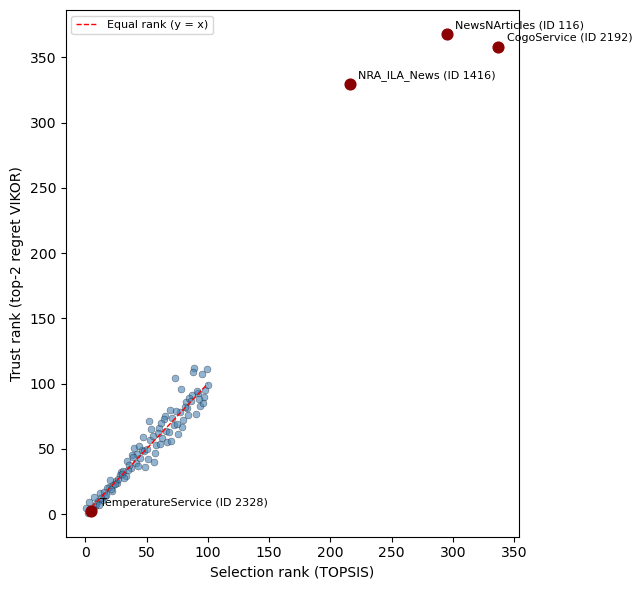

In [36]:
m = (rank_select <= 100).values
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(rank_select[m], rank_trust[m], s=25, alpha=0.6, color='steelblue', edgecolor='black', lw=0.3)
ax.plot([1, 100], [1, 100], 'r--', lw=1, label='Equal rank (y = x)')
marks = {1416: 'NRA_ILA_News', 2192: 'CogoService', 116: 'NewsNArticles', 2328: 'TemperatureService'}
for i, name in marks.items():
    ax.scatter(rank_select[i], rank_trust[i], s=60, color='darkred', zorder=3)
    ax.annotate(f"{name} (ID {i})", (rank_select[i], rank_trust[i]),
                xytext=(6, 4), textcoords='offset points', fontsize=8)
ax.set_xlabel('Selection rank (TOPSIS)')
ax.set_ylabel('Trust rank (top-2 regret VIKOR)')
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig('fig3_scatter_top100.png', dpi=300); plt.savefig('fig3_scatter_top100.pdf'); plt.show()

## V4 — α Sensitivity

Runs the full weighting + trust scoring pipeline across α = 0.0 to 1.0 and tracks which
services stay in the Top-10 regardless of the objective/subjective balance chosen.


In [37]:
alpha_range = np.round(np.arange(0.0, 1.01, 0.1), 1)
top10_by_alpha = {}
id_to_name = dict(zip(df['ServiceID'], df['ServiceName']))

for a in alpha_range:
    wf_a = a*w_critic + (1-a)*w_bwm
    wf_a = wf_a/wf_a.sum()
    gap_a = wf_a*(f_star-Nn)/denom
    S_a = gap_a.sum(axis=1)
    R_a = np.sort(gap_a, axis=1)[:,-2:].mean(axis=1)
    Q_a = 0.5*(S_a-S_a.min())/(S_a.max()-S_a.min()+1e-9) + 0.5*(R_a-R_a.min())/(R_a.max()-R_a.min()+1e-9)
    rank_a = pd.Series(Q_a).rank(ascending=True, method='min').astype(int)
    top10 = set(df.ServiceID[rank_a <= 10])   # ServiceID, not ServiceName (860 duplicate names in QWS)
    top10_by_alpha[a] = top10

# Rank Stability Index: fraction of alpha values in which each service appears in the Top-10
from collections import Counter
counts = Counter()
for a, s in top10_by_alpha.items():
    counts.update(s)
rsi = pd.Series(counts).sort_values(ascending=False) / len(alpha_range)
rsi_display = pd.DataFrame({'ServiceID': rsi.index, 'ServiceName': [id_to_name[i] for i in rsi.index], 'RSI': rsi.values})
print("Rank Stability Index (fraction of alpha values where service is Top-10):")
rsi_display.head(15)


Rank Stability Index (fraction of alpha values where service is Top-10):


,ServiceID,ServiceName,RSI
0,300,XEMBLService,0.909091
1,1307,getJoke,0.818182
2,2328,TemperatureService,0.818182
3,1108,TemperatureService,0.727273
4,735,TemperatureService,0.636364
5,730,eBayWatcherService,0.636364
6,1135,promotionService,0.636364
7,2182,BNQuoteService,0.545455
8,825,GuidGenerator,0.454545
9,1193,net.xmethods.services.stockquote.StockQuoteSer...,0.454545


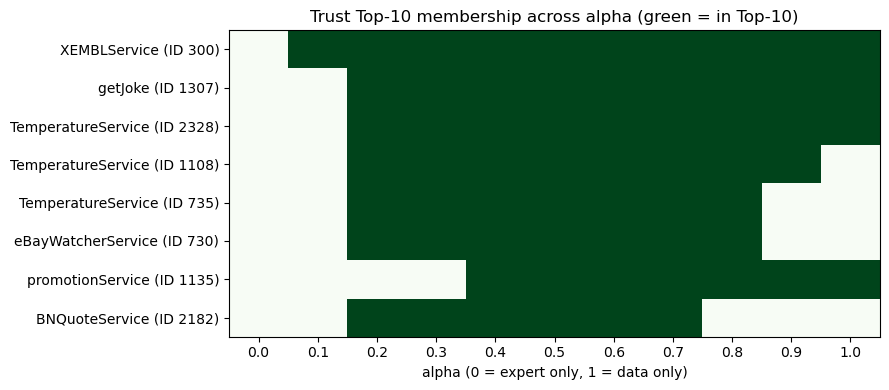

In [38]:
stable = rsi.head(8).index.tolist()
M = np.array([[1 if s in top10_by_alpha[a] else 0 for a in alpha_range] for s in stable])
fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(M, cmap='Greens', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(len(alpha_range))); ax.set_xticklabels(alpha_range)
ax.set_yticks(range(len(stable)))
ax.set_yticklabels([f"{id_to_name[s][:25]} (ID {s})" for s in stable])
ax.set_xlabel('alpha (0 = expert only, 1 = data only)')
ax.set_title('Trust Top-10 membership across alpha (green = in Top-10)')
plt.tight_layout(); plt.savefig('fig_alpha_sensitivity.png', dpi=300); plt.show()


## V5 — VIKOR Acceptability Conditions

Standard, literature-grounded robustness check: is the top trust pick genuinely robust, or a fluke?


In [39]:
Q_sorted = np.sort(Q)
DQ = 1.0 / (N - 1)
C1_gap = Q_sorted[1] - Q_sorted[0]
C1_pass = C1_gap >= DQ

best_idx_svc = np.argmin(Q)
C2_pass = (np.argmin(S) == best_idx_svc) or (np.argmin(R_top2) == best_idx_svc)

print(f"C1 (Acceptable Advantage): Q(2nd)-Q(1st) = {C1_gap:.5f}  vs threshold 1/(N-1) = {DQ:.5f}  -> {'PASS' if C1_pass else 'FAIL'}")
print(f"C2 (Acceptable Stability): top trust pick also best on S or R alone -> {'PASS' if C2_pass else 'FAIL'}")
print(f"\n(Note: with N={N}, the C1 threshold is very small -- report it explicitly, don't overstate a pass.)")


C1 (Acceptable Advantage): Q(2nd)-Q(1st) = 0.00465  vs threshold 1/(N-1) = 0.00040  -> PASS
C2 (Acceptable Stability): top trust pick also best on S or R alone -> FAIL

(Note: with N=2500, the C1 threshold is very small -- report it explicitly, don't overstate a pass.)


In [40]:
rank_S = pd.Series(S).rank(method='min').astype(int)
rank_R = pd.Series(R_top2).rank(method='min').astype(int)
for i in np.argsort(Q)[:2]:
    print(f"ID {i}  {df.ServiceName[i][:30]:30s}  Trust rank {rank_trust[i]}  "
          f"S rank {rank_S[i]}  R rank {rank_R[i]}  Selection rank {rank_select[i]}")

ID 300  XEMBLService                    Trust rank 1  S rank 13  R rank 5  Selection rank 2
ID 2328  TemperatureService              Trust rank 2  S rank 21  R rank 1  Selection rank 5


In [41]:
def bootstrap_tau_ci(rank_select, rank_trust, K, n_boot=2000, seed=42, ci=95):
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({'Rank_select': rank_select, 'Rank_trust': rank_trust})
    subset = d[d.Rank_select <= K].reset_index(drop=True)
    m = len(subset)
    boot_taus = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, m, m)
        sample = subset.iloc[idx]
        boot_taus[i], _ = kendalltau(sample.Rank_select, sample.Rank_trust)
    lo, hi = np.percentile(boot_taus, [(100-ci)/2, 100-(100-ci)/2])
    return lo, hi, boot_taus

print("\nBootstrap 95% confidence intervals for Kendall tau:")
for K in [20, 50, 100]:
    lo, hi, _ = bootstrap_tau_ci(rank_select.values, rank_trust.values, K)
    print(f"Top-{K}: tau 95% CI = [{lo:.3f}, {hi:.3f}]")


Bootstrap 95% confidence intervals for Kendall tau:
Top-20: tau 95% CI = [0.531, 0.888]
Top-50: tau 95% CI = [0.789, 0.902]
Top-100: tau 95% CI = [0.820, 0.893]


In [42]:
def run_pipeline_from_raw(X_raw, w_bwm_fixed, transform_idx, cost_idx, alpha=0.5, k=2):
    n_local = X_raw.shape[1]
    Xt_local = X_raw.copy()
    for j in transform_idx:
        Xt_local[:, j] = np.log1p(np.clip(Xt_local[:, j], a_min=0, a_max=None))
    Nn_local = np.zeros_like(Xt_local)
    for j in range(n_local):
        col = Xt_local[:, j]
        if j in cost_idx:
            Nn_local[:, j] = -col / np.sqrt(np.sum(col**2))        # FIXED: linear flip
        else:
            Nn_local[:, j] = col / np.sqrt(np.sum(col**2))
    Z_local = (Xt_local - Xt_local.min(axis=0)) / (Xt_local.max(axis=0) - Xt_local.min(axis=0))
    sigma_local = Z_local.std(axis=0)                             # FIXED: min-max for CRITIC
    R_local = np.corrcoef(Nn_local.T)
    C_local = sigma_local * np.sum(1 - R_local, axis=1)
    w_critic_local = C_local / C_local.sum()
    w_final_local = alpha * w_critic_local + (1 - alpha) * w_bwm_fixed
    w_final_local /= w_final_local.sum()
    Zb_local = Z_local.copy(); Zb_local[:, cost_idx] = 1 - Zb_local[:, cost_idx]
    V_local = w_final_local * Zb_local
    Dplus = np.sqrt(((V_local - V_local.max(axis=0))**2).sum(axis=1))
    Dminus = np.sqrt(((V_local - V_local.min(axis=0))**2).sum(axis=1))
    T_select_local = Dminus / (Dplus + Dminus)
    rank_select_local = pd.Series(T_select_local).rank(ascending=False, method='min').astype(int)
    f_star_local, f_minus_local = Nn_local.max(axis=0), Nn_local.min(axis=0)
    denom_local = f_star_local - f_minus_local
    denom_local[denom_local == 0] = 1e-9
    gap_local = w_final_local * (f_star_local - Nn_local) / denom_local
    S_local = gap_local.sum(axis=1)
    R_top2_local = np.sort(gap_local, axis=1)[:, -k:].mean(axis=1)
    Q_local = 0.5*(S_local - S_local.min())/(S_local.max() - S_local.min() + 1e-9) + \
              0.5*(R_top2_local - R_top2_local.min())/(R_top2_local.max() - R_top2_local.min() + 1e-9)
    rank_trust_local = pd.Series(Q_local).rank(ascending=True, method='min').astype(int)
    return rank_select_local, rank_trust_local

# Safety check: with NO noise, this copy must give exactly the same rankings as the main notebook
rs0, rt0 = run_pipeline_from_raw(X, w_bwm, transform_idx, cost_idx)
print("Pipeline copy matches main notebook:",
      bool((rs0.values == rank_select.values).all() and (rt0.values == rank_trust.values).all()))

n_trials, noise_level = 200, 0.02
rng = np.random.default_rng(123)
base_s, base_t = rank_select.values, rank_trust.values
sel20, tr20 = base_s <= 20, base_t <= 20
examples = [1416, 2192, 116]
noisy_runs = []                                  # saved for the next test
sel_shift, tr_shift, ex_ranks = [], [], []
for t in range(n_trials):
    X_noisy = np.clip(X * rng.normal(1.0, noise_level, size=X.shape), 1e-6, None)
    rs, rt = run_pipeline_from_raw(X_noisy, w_bwm, transform_idx, cost_idx, alpha=0.5)
    rs, rt = rs.values, rt.values
    noisy_runs.append((rs, rt))
    sel_shift.append(np.abs(rs[sel20] - base_s[sel20]).mean())   # each judged on its OWN top-20
    tr_shift.append(np.abs(rt[tr20] - base_t[tr20]).mean())
    ex_ranks.append([(rs[i], rt[i]) for i in examples])

print(f"Selection top-20 shift: {np.mean(sel_shift):.2f} +/- {np.std(sel_shift):.2f}")
print(f"Trust top-20 shift:     {np.mean(tr_shift):.2f} +/- {np.std(tr_shift):.2f}")
ex = np.array(ex_ranks)
for k, i in enumerate(examples):
    s_lo, s_hi = np.percentile(ex[:, k, 0], [5, 95])
    t_lo, t_hi = np.percentile(ex[:, k, 1], [5, 95])
    print(f"{df.ServiceName[i][:25]:25s} Selection {s_lo:.0f}-{s_hi:.0f}   Trust {t_lo:.0f}-{t_hi:.0f}")

Pipeline copy matches main notebook: True
Selection top-20 shift: 5.66 +/- 0.87
Trust top-20 shift:     5.58 +/- 0.95
NRA_x0020_ILA_x0020_News_ Selection 113-300   Trust 225-443
CogoService               Selection 221-417   Trust 257-440
NewsNArticles             Selection 193-376   Trust 277-496


In [43]:
for K in [20, 50, 100]:
    m = base_s <= K
    tau_div, _ = kendalltau(base_s[m], base_t[m])                                # A: Trust vs Selection
    tau_noise = np.array([kendalltau(base_t[m], rt[m])[0] for rs, rt in noisy_runs])   # B: Trust vs noisy Trust
    p = np.mean(tau_noise <= tau_div)
    print(f"Top-{K}: Trust vs Selection tau = {tau_div:.3f} | Trust vs noisy Trust tau = "
          f"{tau_noise.mean():.3f} (lowest 5%: {np.percentile(tau_noise, 5):.3f}) | p = {p:.3f}")

Top-20: Trust vs Selection tau = 0.726 | Trust vs noisy Trust tau = 0.400 (lowest 5%: 0.210) | p = 1.000
Top-50: Trust vs Selection tau = 0.851 | Trust vs noisy Trust tau = 0.699 (lowest 5%: 0.639) | p = 1.000
Top-100: Trust vs Selection tau = 0.859 | Trust vs noisy Trust tau = 0.713 (lowest 5%: 0.671) | p = 1.000


In [44]:
rows = []
for k in [1, 2]:
    bs, bt = [r.values for r in run_pipeline_from_raw(X, w_bwm, transform_idx, cost_idx, k=k)]
    rng = np.random.default_rng(123)
    top20, top50 = bt <= 20, bs <= 50
    shifts, selftau = [], []
    for t in range(100):
        Xn = np.clip(X * rng.normal(1.0, 0.02, size=X.shape), 1e-6, None)
        rt = run_pipeline_from_raw(Xn, w_bwm, transform_idx, cost_idx, k=k)[1].values
        shifts.append(np.abs(rt[top20] - bt[top20]).mean())
        selftau.append(kendalltau(bt[top50], rt[top50])[0])
    rows.append({'k': k,
                 'Trust top-20 shift': round(np.mean(shifts), 2),
                 'Self-agreement (Top-50 tau)': round(np.mean(selftau), 3),
                 'Trust vs Selection (Top-50 tau)': round(kendalltau(bs[top50], bt[top50])[0], 3),
                 'NewsNArticles trust rank': int(bt[116]),
                 'CogoService trust rank': int(bt[2192])})
pd.DataFrame(rows)

,k,Trust top-20 shift,Self-agreement (Top-50 tau),Trust vs Selection (Top-50 tau),NewsNArticles trust rank,CogoService trust rank
0,1,5.79,0.725,0.762,279,434
1,2,5.53,0.702,0.851,368,358


In [45]:
keep = ~df.duplicated('WSDLAddress').values          # keep first copy of each address
rs_u, rt_u = [r.values for r in run_pipeline_from_raw(X[keep], w_bwm, transform_idx, cost_idx)]
print("Services kept:", keep.sum())
for K in [20, 50, 100]:
    m = rs_u <= K
    print(f"Top-{K}: Trust vs Selection tau = {kendalltau(rs_u[m], rt_u[m])[0]:.3f}")
pos = {i: p for p, i in enumerate(np.where(keep)[0])}
for i in [1416, 2192, 116]:
    if i in pos:
        print(f"{df.ServiceName[i][:25]:25s} Selection {rs_u[pos[i]]}  Trust {rt_u[pos[i]]}")
    else:
        print(df.ServiceName[i], "was a repeat and was removed")

Services kept: 2377
Top-20: Trust vs Selection tau = 0.716
Top-50: Trust vs Selection tau = 0.856
Top-100: Trust vs Selection tau = 0.872
NRA_x0020_ILA_x0020_News_ Selection 206  Trust 299
CogoService               Selection 309  Trust 324
NewsNArticles             Selection 270  Trust 332


## Save Results

Exports the weight vectors and full rankings to Excel/CSV files for use in the paper.


In [46]:
weights_df.to_csv('trustcloud_weights.csv', index=False)
final_results = selection_df.merge(trust_df.drop(columns=['ServiceName']), on='ServiceID')
final_results.to_csv('trustcloud_results.csv', index=False)
pd.DataFrame(ablation_rows).to_csv('trustcloud_k_ablation.csv', index=False)

print("Saved: trustcloud_weights.csv, trustcloud_results.csv, trustcloud_k_ablation.csv")
final_results.sort_values('Rank_trust').head(10)


Saved: trustcloud_weights.csv, trustcloud_results.csv, trustcloud_k_ablation.csv


,ServiceID,ServiceName,T_select,Rank_select,S,R_top2,Q_trust,Rank_trust
1,300,XEMBLService,0.8579,2,0.1400,0.0221,0.0346,1
4,2328,TemperatureService,0.8498,5,0.1514,0.0211,0.0393,2
3,1108,TemperatureService,0.8498,4,0.1504,0.0218,0.0412,3
5,735,TemperatureService,0.8497,6,0.1503,0.0218,0.0412,4
0,1307,getJoke,0.8617,1,0.1015,0.0321,0.0440,5
7,730,eBayWatcherService,0.8483,8,0.1520,0.0224,0.0447,6
10,2182,BNQuoteService,0.8457,11,0.1559,0.0219,0.0458,7
8,1193,net.xmethods.services.stockquote.StockQuoteSer...,0.8472,9,0.1523,0.0230,0.0470,8
2,1135,promotionService,0.8552,3,0.1237,0.0294,0.0502,9
9,447,CourseRegistration,0.8469,10,0.1351,0.0280,0.0533,10


In [47]:
# The Synthetic Test

In [48]:
rng = np.random.default_rng(7)
def make(level):                               # level: 0..1 per criterion, 1 = best
    level = np.clip(level + rng.uniform(-0.03, 0.03, n), 0.001, 0.999)
    return np.array([np.quantile(X[:, j], 1 - level[j] if j in cost_idx else level[j]) for j in range(n)])

planted, types = [], []
for _ in range(10):
    planted.append(make(np.full(n, 0.80))); types.append('A')
for j in range(n):                             # one B per criterion
    lv = np.full(n, 0.90); lv[j] = 0.02
    planted.append(make(lv)); types.append('B')
for _ in range(10):
    lv = np.full(n, 0.90); lv[rng.choice(n, 3, replace=False)] = 0.20
    planted.append(make(lv)); types.append('C')
for _ in range(10):
    planted.append(make(np.full(n, 0.50))); types.append('D')
planted, types = np.array(planted), np.array(types)
X_all = np.vstack([X, planted])
idx = np.arange(N, N + len(planted))
print("Fake services added:", len(planted), "| Total services:", len(X_all))

Fake services added: 39 | Total services: 2539


In [49]:
rows = []
for label, k in [('Selection', 1), ('Trust k=1', 1), ('Trust k=2', 2)]:
    rs, rt = [r.values[idx] for r in run_pipeline_from_raw(X_all, w_bwm, transform_idx, cost_idx, k=k)]
    r = rs if label == 'Selection' else rt
    A, B, C = r[types == 'A'], r[types == 'B'], r[types == 'C']
    rows.append({'Method': label,
                 **{f'{t} mean rank': int(r[types == t].mean()) for t in 'ABCD'},
                 'A above B %': round(100 * np.mean(A[:, None] < B[None, :]), 1),
                 'A above C %': round(100 * np.mean(A[:, None] < C[None, :]), 1)})
pd.DataFrame(rows)

,Method,A mean rank,B mean rank,C mean rank,D mean rank,A above B %,A above C %
0,Selection,63,447,398,937,88.9,100.0
1,Trust k=1,79,797,468,673,88.9,66.0
2,Trust k=2,60,404,398,830,88.9,95.0


In [50]:
def synthetic_once(seed):
    global rng
    rng = np.random.default_rng(seed)
    planted, types = [], []
    for _ in range(10):
        planted.append(make(np.full(n, 0.80))); types.append('A')
    for j in range(n):
        lv = np.full(n, 0.90); lv[j] = 0.02
        planted.append(make(lv)); types.append('B')
    for _ in range(10):
        lv = np.full(n, 0.90); lv[rng.choice(n, 3, replace=False)] = 0.20
        planted.append(make(lv)); types.append('C')
    for _ in range(10):
        planted.append(make(np.full(n, 0.50))); types.append('D')
    types = np.array(types)
    Xa = np.vstack([X, np.array(planted)]); ix = np.arange(N, N + len(types))
    out = []
    for label, k in [('Selection', 1), ('Trust k=1', 1), ('Trust k=2', 2)]:
        rs, rt = [r.values[ix] for r in run_pipeline_from_raw(Xa, w_bwm, transform_idx, cost_idx, k=k)]
        r = rs if label == 'Selection' else rt
        A, B, C = r[types == 'A'], r[types == 'B'], r[types == 'C']
        out.append({'Method': label,
                    'A above B %': 100 * np.mean(A[:, None] < B[None, :]),
                    'A above C %': 100 * np.mean(A[:, None] < C[None, :])})
    return out

res = pd.DataFrame([row for s in range(20) for row in synthetic_once(s)])
res.groupby('Method').agg(['mean', 'std']).round(1)

A above B %      A above C %      
                 mean  std        mean   std
Method                                      
Selection        84.8  7.0       100.0   0.0
Trust k=1        91.0  4.6        71.2  13.9
Trust k=2        91.7  4.7        99.3   1.9

In [51]:
from scipy.stats import wilcoxon
for col in ['A above B %', 'A above C %']:
    a = res[res.Method == 'Trust k=2'][col].values
    for other in ['Selection', 'Trust k=1']:
        b = res[res.Method == other][col].values
        print(f"{col}: k=2 vs {other:10s} p = {wilcoxon(a, b).pvalue:.4f}")

A above B %: k=2 vs Selection  p = 0.0014
A above B %: k=2 vs Trust k=1  p = 0.1088
A above C %: k=2 vs Selection  p = 0.0656
A above C %: k=2 vs Trust k=1  p = 0.0001


In [52]:
def synthetic_once(seed, alpha=0.5):
    global rng
    rng = np.random.default_rng(seed)
    planted, types = [], []
    for _ in range(10):
        planted.append(make(np.full(n, 0.80))); types.append('A')
    for j in range(n):
        lv = np.full(n, 0.90); lv[j] = 0.02
        planted.append(make(lv)); types.append('B')
    for _ in range(10):
        lv = np.full(n, 0.90); lv[rng.choice(n, 3, replace=False)] = 0.20
        planted.append(make(lv)); types.append('C')
    for _ in range(10):
        planted.append(make(np.full(n, 0.50))); types.append('D')
    types = np.array(types)
    Xa = np.vstack([X, np.array(planted)]); ix = np.arange(N, N + len(types))
    out = []
    for label, k in [('Selection', 1), ('Trust k=1', 1), ('Trust k=2', 2)]:
        rs, rt = [r.values[ix] for r in run_pipeline_from_raw(Xa, w_bwm, transform_idx, cost_idx, alpha=alpha, k=k)]
        r = rs if label == 'Selection' else rt
        A, B, C = r[types == 'A'], r[types == 'B'], r[types == 'C']
        out.append({'alpha': alpha, 'Method': label,
                    'A above B %': 100 * np.mean(A[:, None] < B[None, :]),
                    'A above C %': 100 * np.mean(A[:, None] < C[None, :])})
    return out

res_a = pd.DataFrame([row for a in [0.0, 0.5, 1.0] for s in range(20) for row in synthetic_once(s, a)])
res_a.groupby(['alpha', 'Method']).agg(['mean', 'std']).round(1)

A above B %      A above C %      
                       mean  std        mean   std
alpha Method                                      
0.0   Selection        33.5  4.4        32.0  14.4
      Trust k=1        34.3  5.1        32.0  14.4
      Trust k=2        50.9  8.8        61.4  12.3
0.5   Selection        84.8  7.0       100.0   0.0
      Trust k=1        91.0  4.6        71.2  13.9
      Trust k=2        91.7  4.7        99.3   1.9
1.0   Selection        90.4  4.9       100.0   0.0
      Trust k=1        99.4  2.5       100.0   0.0
      Trust k=2        98.0  3.3       100.0   0.0

In [53]:
rng = np.random.default_rng(0)
A_rows = [make(np.full(n, 0.80)) for _ in range(10)]
B_rows = []
for j in range(n):
    lv = np.full(n, 0.90); lv[j] = 0.02
    B_rows.append(make(lv))
Xa = np.vstack([X, A_rows, B_rows])
iA, iB = np.arange(N, N + 10), np.arange(N + 10, N + 10 + n)
for alpha in [0.0, 0.5]:
    rt = run_pipeline_from_raw(Xa, w_bwm, transform_idx, cost_idx, alpha=alpha, k=2)[1].values
    print(f"alpha = {alpha}")
    for j in range(n):
        print(f"  weak in {criteria[j]:15s} -> balanced A ranked above it: {100*np.mean(rt[iA] < rt[iB[j]]):5.1f}%")

alpha = 0.0
  weak in ResponseTime    -> balanced A ranked above it:   0.0%
  weak in Availability    -> balanced A ranked above it: 100.0%
  weak in Throughput      -> balanced A ranked above it:   0.0%
  weak in Successability  -> balanced A ranked above it: 100.0%
  weak in Reliability     -> balanced A ranked above it: 100.0%
  weak in Compliance      -> balanced A ranked above it:   0.0%
  weak in BestPractices   -> balanced A ranked above it:   0.0%
  weak in Latency         -> balanced A ranked above it: 100.0%
  weak in Documentation   -> balanced A ranked above it:   0.0%
alpha = 0.5
  weak in ResponseTime    -> balanced A ranked above it: 100.0%
  weak in Availability    -> balanced A ranked above it: 100.0%
  weak in Throughput      -> balanced A ranked above it: 100.0%
  weak in Successability  -> balanced A ranked above it: 100.0%
  weak in Reliability     -> balanced A ranked above it: 100.0%
  weak in Compliance      -> balanced A ranked above it:   0.0%
  weak in BestPr

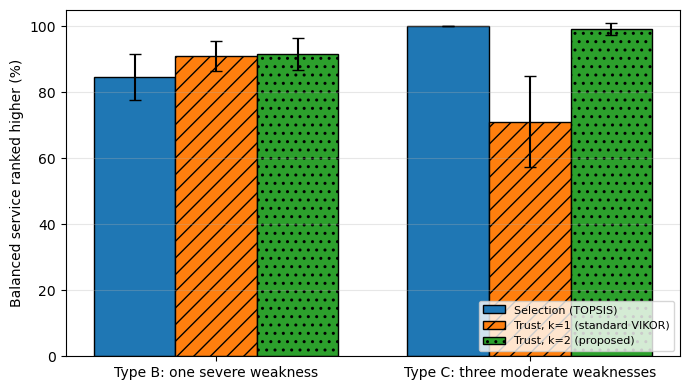

In [54]:
summ = res.groupby('Method')[['A above B %', 'A above C %']].agg(['mean', 'std'])
methods = ['Selection', 'Trust k=1', 'Trust k=2']
labels = ['Selection (TOPSIS)', 'Trust, k=1 (standard VIKOR)', 'Trust, k=2 (proposed)']
x, w = np.arange(2), 0.26
fig, ax = plt.subplots(figsize=(7, 4))
for i, (m, lab, h) in enumerate(zip(methods, labels, ['', '//', '..'])):
    means = [summ.loc[m, (c, 'mean')] for c in ['A above B %', 'A above C %']]
    sds = [summ.loc[m, (c, 'std')] for c in ['A above B %', 'A above C %']]
    ax.bar(x + (i - 1) * w, means, w, yerr=sds, capsize=4, label=lab, hatch=h, edgecolor='black')
ax.set_xticks(x); ax.set_xticklabels(['Type B: one severe weakness', 'Type C: three moderate weaknesses'])
ax.set_ylabel('Balanced service ranked higher (%)'); ax.set_ylim(0, 105)
ax.legend(loc='lower right', fontsize=8); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig('fig2_synthetic.png', dpi=300); plt.savefig('fig2_synthetic.pdf'); plt.show()

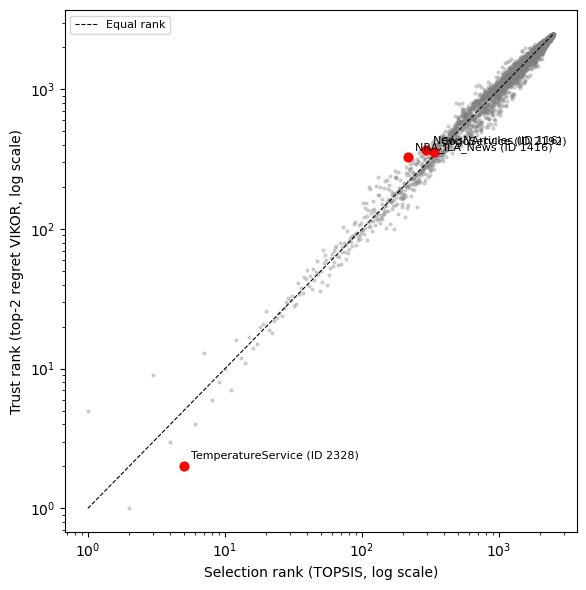

In [55]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(rank_select, rank_trust, s=4, alpha=0.3, color='grey')
ax.plot([1, N], [1, N], 'k--', lw=0.8, label='Equal rank')
marks = {116: 'NewsNArticles', 2192: 'CogoService', 1416: 'NRA_ILA_News', 2328: 'TemperatureService'}
for i, name in marks.items():
    ax.scatter(rank_select[i], rank_trust[i], s=40, color='red', zorder=3)
    ax.annotate(f"{name} (ID {i})", (rank_select[i], rank_trust[i]),
                xytext=(5, 5), textcoords='offset points', fontsize=8)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Selection rank (TOPSIS, log scale)')
ax.set_ylabel('Trust rank (top-2 regret VIKOR, log scale)')
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig('fig3_scatter.png', dpi=300); plt.savefig('fig3_scatter.pdf'); plt.show()

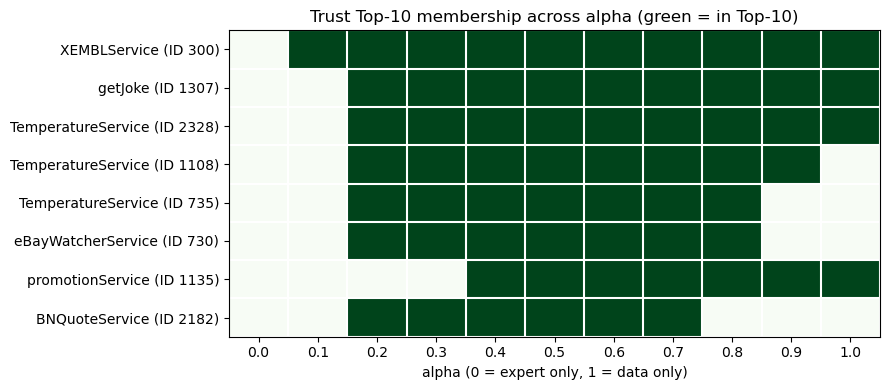

In [56]:
stable = rsi.head(8).index.tolist()
M = np.array([[1 if s in top10_by_alpha[a] else 0 for a in alpha_range] for s in stable])
fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(M, cmap='Greens', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(len(alpha_range))); ax.set_xticklabels(alpha_range)
ax.set_yticks(range(len(stable)))
ax.set_yticklabels([f"{id_to_name[s][:25]} (ID {s})" for s in stable])
ax.set_xticks(np.arange(-0.5, len(alpha_range), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(stable), 1), minor=True)
ax.grid(which='minor', color='white', linewidth=1.5); ax.tick_params(which='minor', length=0)
ax.set_xlabel('alpha (0 = expert only, 1 = data only)')
ax.set_title('Trust Top-10 membership across alpha (green = in Top-10)')
plt.tight_layout()
plt.savefig('fig4_alpha.png', dpi=300); plt.savefig('fig4_alpha.pdf'); plt.show()

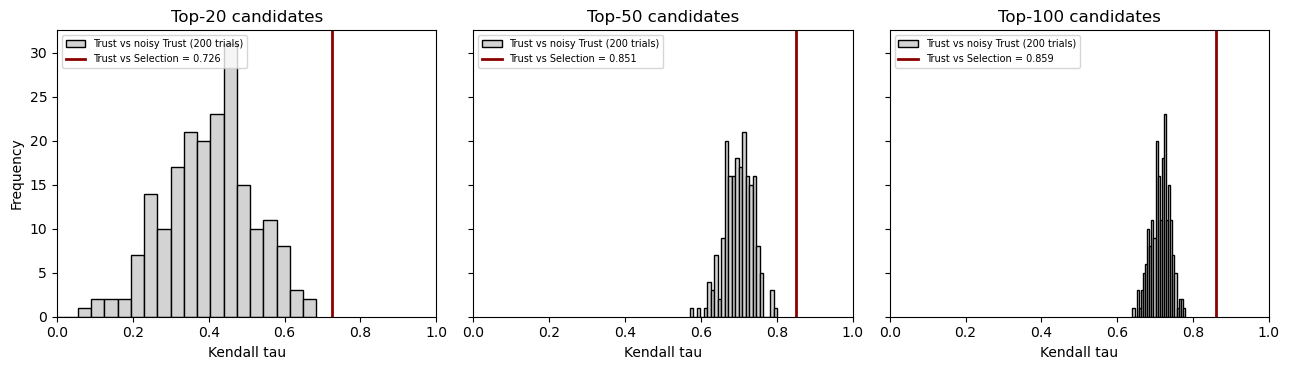

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, K in zip(axes, [20, 50, 100]):
    m = base_s <= K
    tau_div = kendalltau(base_s[m], base_t[m])[0]
    tau_noise = [kendalltau(base_t[m], rt[m])[0] for rs, rt in noisy_runs]
    ax.hist(tau_noise, bins=25, color='lightgrey', edgecolor='black', label='Trust vs noisy Trust (200 trials)')
    ax.axvline(tau_div, color='darkred', lw=2, label=f'Trust vs Selection = {tau_div:.3f}')
    ax.set_title(f'Top-{K} candidates'); ax.set_xlabel('Kendall tau'); ax.set_xlim(0, 1)
    ax.legend(fontsize=7, loc='upper left')
axes[0].set_ylabel('Frequency')
plt.tight_layout(); plt.savefig('fig5_divergence.png', dpi=300); plt.savefig('fig5_divergence.pdf'); plt.show()

In [58]:
def scores_from_raw(X_raw, alpha=0.5):
    Xt_ = X_raw.copy()
    for j in transform_idx:
        Xt_[:, j] = np.log1p(np.clip(Xt_[:, j], 0, None))
    Nn_ = Xt_ / np.sqrt((Xt_**2).sum(axis=0)); Nn_[:, cost_idx] *= -1
    Z_ = (Xt_ - Xt_.min(0)) / (Xt_.max(0) - Xt_.min(0))
    C_ = Z_.std(0) * (1 - np.corrcoef(Nn_.T)).sum(1)
    w_ = alpha * C_ / C_.sum() + (1 - alpha) * w_bwm; w_ /= w_.sum()
    Zb_ = Z_.copy(); Zb_[:, cost_idx] = 1 - Zb_[:, cost_idx]
    V_ = w_ * Zb_
    Dp = np.sqrt(((V_ - V_.max(0))**2).sum(1)); Dm = np.sqrt(((V_ - V_.min(0))**2).sum(1))
    gap_ = w_ * (Nn_.max(0) - Nn_) / (Nn_.max(0) - Nn_.min(0))
    Zb_ = Z_.copy(); Zb_[:, cost_idx] = 1 - Zb_[:, cost_idx]
    return Dm / (Dp + Dm), gap_, Zb_

def nrm(v): return (v - v.min()) / (v.max() - v.min() + 1e-12)
def rank_low(v): return pd.Series(v).rank(method='min').values      # lowest value = rank 1

def method_ranks(Xa):
    T_, gap_, Zb_ = scores_from_raw(Xa)
    S_, g = gap_.sum(1), np.sort(gap_, axis=1)[:, ::-1]            # gaps, largest first
    owa = np.arange(n, 0, -1) / np.arange(n, 0, -1).sum()           # bigger gap, bigger weight
    out = {'Selection (TOPSIS)': rank_low(-T_)}
    for v in [0.0, 0.25, 0.5, 0.75, 1.0]:
        out[f'VIKOR k=1, v={v}'] = rank_low(v * nrm(S_) + (1 - v) * nrm(g[:, 0]))
    out['OWA-VIKOR'] = rank_low(0.5 * nrm(S_) + 0.5 * nrm(g @ owa))
    out['Max-min'] = rank_low(-Zb_.min(1))
    for q in [0.05, 0.10, 0.25]:
        veto = (Zb_ < np.quantile(Zb_, q, axis=0)).any(1)
        out[f'TOPSIS + veto {int(q*100)}%'] = rank_low(-T_ + 10 * veto)
    out['Trust k=2 (proposed)'] = rank_low(0.5 * nrm(S_) + 0.5 * nrm(g[:, :2].mean(1)))
    P = pd.DataFrame(Zb_).rank(pct=True).values                 # percentile per criterion, 1 = best
    gp = gap_.max(0) * (1 - P)                                   # regret on percentile scale
    gps = np.sort(gp, axis=1)[:, ::-1]
    out['Trust k=2 percentile'] = rank_low(0.5 * nrm(S_) + 0.5 * nrm(gps[:, :2].mean(1)))
    return out

In [59]:
def bench_once(seed):
    global rng
    rng = np.random.default_rng(seed)
    planted, types = [], []
    for _ in range(10): planted.append(make(np.full(n, 0.80))); types.append('A')
    for j in range(n):
        lv = np.full(n, 0.90); lv[j] = 0.02; planted.append(make(lv)); types.append('B')
    for _ in range(10):
        lv = np.full(n, 0.90); lv[rng.choice(n, 3, replace=False)] = 0.20
        planted.append(make(lv)); types.append('C')
    for _ in range(10): planted.append(make(np.full(n, 0.50))); types.append('D')
    for _ in range(10):                                   # NEW: excellent with one mild dip
        lv = np.full(n, 0.95); lv[rng.choice(n)] = 0.40
        planted.append(make(lv)); types.append('E')
    types = np.array(types); Xa = np.vstack([X, np.array(planted)]); ix = np.arange(N, N + len(types))
    rows = []
    for name, r in method_ranks(Xa).items():
        r = r[ix]
        A, B, C, D, E = [r[types == t] for t in 'ABCDE']
        rows.append({'Method': name,
                     'A above B %': 100 * np.mean(A[:, None] < B[None, :]),
                     'A above C %': 100 * np.mean(A[:, None] < C[None, :]),
                     'E above D %': 100 * np.mean(E[:, None] < D[None, :])})
    return rows

bench = pd.DataFrame([row for s in range(20) for row in bench_once(s)])
bench.groupby('Method', sort=False).agg(['mean', 'std']).round(1)

A above B %      A above C %       E above D %     
                            mean  std        mean   std        mean  std
Method                                                                  
Selection (TOPSIS)          84.8  6.9       100.0   0.0       100.0  0.0
VIKOR k=1, v=0.0            92.2  5.2        67.5  14.1        89.0  8.5
VIKOR k=1, v=0.25           91.9  4.9        67.5  14.1        99.0  3.1
VIKOR k=1, v=0.5            91.1  4.6        70.5  14.4       100.0  0.0
VIKOR k=1, v=0.75           81.9  8.6       100.0   0.2       100.0  0.0
VIKOR k=1, v=1.0            61.2  8.6       100.0   0.0       100.0  0.0
OWA-VIKOR                   73.3  9.8       100.0   0.0       100.0  0.0
Max-min                    100.0  0.0       100.0   0.0        80.8  7.5
TOPSIS + veto 5%            99.4  2.5       100.0   0.0       100.0  0.0
TOPSIS + veto 10%           99.4  2.5       100.0   0.0       100.0  0.0
TOPSIS + veto 25%           99.4  2.5       100.0   0.0       100.0  0.0
Trust k=2 (proposed)        91.7  4.7        99.2   2.0       100.0  0.0
Trust k=2 percentile        81.6  7.1       100.0   0.0       100.0  0.0

In [60]:
def bench_once_rand(seed):
    global rng
    rng = np.random.default_rng(seed)
    planted, types = [], []
    for _ in range(10): planted.append(make(np.full(n, 0.80))); types.append('A')
    for j in range(n):
        lv = np.full(n, 0.90); lv[j] = rng.uniform(0.01, 0.10)          # severe, random size
        planted.append(make(lv)); types.append('B')
    for _ in range(10):
        lv = np.full(n, 0.90); lv[rng.choice(n, 3, replace=False)] = rng.uniform(0.15, 0.35, 3)
        planted.append(make(lv)); types.append('C')
    for _ in range(10): planted.append(make(np.full(n, 0.50))); types.append('D')
    for _ in range(10):
        lv = np.full(n, 0.95); lv[rng.choice(n)] = rng.uniform(0.25, 0.45)  # mild dip, random size
        planted.append(make(lv)); types.append('E')
    types = np.array(types); Xa = np.vstack([X, np.array(planted)]); ix = np.arange(N, N + len(types))
    rows = []
    for name, r in method_ranks(Xa).items():
        r = r[ix]
        A, B, C, D, E = [r[types == t] for t in 'ABCDE']
        rows.append({'Method': name,
                     'A above B %': 100 * np.mean(A[:, None] < B[None, :]),
                     'A above C %': 100 * np.mean(A[:, None] < C[None, :]),
                     'E above D %': 100 * np.mean(E[:, None] < D[None, :])})
    return rows

bench_r = pd.DataFrame([row for s in range(20) for row in bench_once_rand(s)])
bench_r.groupby('Method', sort=False).agg(['mean', 'std']).round(1)

A above B %       A above C %       E above D %      
                            mean   std        mean   std        mean   std
Method                                                                    
Selection (TOPSIS)          60.7   9.8        92.8   7.7       100.0   0.0
VIKOR k=1, v=0.0            76.1   7.5        76.5  12.3        81.6  18.1
VIKOR k=1, v=0.25           70.7   8.1        77.0  11.7        93.4   9.3
VIKOR k=1, v=0.5            66.4   9.3        78.9  12.0       100.0   0.0
VIKOR k=1, v=0.75           56.8  10.6        89.0   9.1       100.0   0.0
VIKOR k=1, v=1.0            35.8   9.6        99.2   2.4       100.0   0.0
OWA-VIKOR                   48.4  12.0        98.0   3.6       100.0   0.0
Max-min                    100.0   0.0        99.5   2.2        79.3  12.8
TOPSIS + veto 5%            71.1  11.3        92.8   7.7       100.0   0.0
TOPSIS + veto 10%           83.3   8.5        92.8   7.7       100.0   0.0
TOPSIS + veto 25%           93.3   5.6        98.0   4.1        98.0   4.1
Trust k=2 (proposed)        68.7   8.4        93.0   6.8       100.0   0.0
Trust k=2 percentile        64.4   8.4       100.0   0.0       100.0   0.0

In [61]:
hold = pd.DataFrame([row for s in range(100, 120) for row in bench_once_rand(s)])
hold.groupby('Method', sort=False).agg(['mean', 'std']).round(1)

A above B %       A above C %       E above D %      
                            mean   std        mean   std        mean   std
Method                                                                    
Selection (TOPSIS)          62.6  10.6        90.8   8.7       100.0   0.0
VIKOR k=1, v=0.0            74.4   8.9        69.5  17.9        79.6  12.7
VIKOR k=1, v=0.25           70.7  11.4        69.5  17.9        93.6   6.0
VIKOR k=1, v=0.5            67.4  11.5        71.6  17.2       100.0   0.0
VIKOR k=1, v=0.75           59.4  11.9        87.0  11.8       100.0   0.0
VIKOR k=1, v=1.0            40.0   8.8        98.0   3.9       100.0   0.0
OWA-VIKOR                   51.7  10.9        96.8   5.3       100.0   0.0
Max-min                    100.0   0.0       100.0   0.0        78.4  12.6
TOPSIS + veto 5%            68.4  13.3        90.8   8.7       100.0   0.0
TOPSIS + veto 10%           83.8   9.8        90.8   8.7       100.0   0.0
TOPSIS + veto 25%           91.1   4.6        95.5   6.9        96.5   4.9
Trust k=2 (proposed)        69.3  10.5        90.3  10.0       100.0   0.0
Trust k=2 percentile        61.8   9.4       100.0   0.0       100.0   0.0

In [62]:
def method_ranks_all(Xa):
    out = method_ranks(Xa)
    out.pop('Trust k=2 percentile', None)                       # post-hoc variant, not reported
    T_, gap_, Zb_ = scores_from_raw(Xa)
    S_, g = gap_.sum(1), np.sort(gap_, axis=1)[:, ::-1]
    for k in [3, 4]:
        out[f'Top-k VIKOR k={k}'] = rank_low(0.5 * nrm(S_) + 0.5 * nrm(g[:, :k].mean(1)))
    out['Top-k VIKOR k=all'] = rank_low(0.5 * nrm(S_) + 0.5 * nrm(g.mean(1)))
    return out

def bench_grid_once(seed, b, c, e):
    global rng
    rng = np.random.default_rng(seed)
    planted, types = [], []
    for _ in range(10): planted.append(make(np.full(n, 0.80))); types.append('A')
    for j in range(n):
        lv = np.full(n, 0.90); lv[j] = b; planted.append(make(lv)); types.append('B')
    for _ in range(10):
        lv = np.full(n, 0.90); lv[rng.choice(n, 3, replace=False)] = c
        planted.append(make(lv)); types.append('C')
    for _ in range(10): planted.append(make(np.full(n, 0.50))); types.append('D')
    for _ in range(10):
        lv = np.full(n, 0.95); lv[rng.choice(n)] = e; planted.append(make(lv)); types.append('E')
    types = np.array(types); Xa = np.vstack([X, np.array(planted)]); ix = np.arange(N, N + len(types))
    res = {}
    for name, r in method_ranks_all(Xa).items():
        r = r[ix]; A, B, C, D, E = [r[types == t] for t in 'ABCDE']
        res[name] = (100 * np.mean(A[:, None] < B[None, :]),
                     100 * np.mean(A[:, None] < C[None, :]),
                     100 * np.mean(E[:, None] < D[None, :]))
    return res

settings = [('B', 0.01), ('B', 0.05), ('B', 0.10), ('C', 0.15), ('C', 0.25), ('C', 0.35), ('E', 0.30), ('E', 0.45)]
default = {'B': 0.02, 'C': 0.20, 'E': 0.40}
rows = []
for typ, lvl in settings:
    p = dict(default); p[typ] = lvl
    col = {'B': 0, 'C': 1, 'E': 2}[typ]
    for s in range(20):
        for name, v in bench_grid_once(s, p['B'], p['C'], p['E']).items():
            rows.append({'Method': name, 'Test': f'{typ} at {int(lvl*100)}%', 'Score': v[col]})
grid = pd.DataFrame(rows)
table = grid.pivot_table(index='Method', columns='Test', values='Score', aggfunc='mean', sort=False).round(1)
table.to_csv('trustcloud_grid.csv')
table

Test,B at 1%,B at 5%,B at 10%,C at 15%,C at 25%,C at 35%,E at 30%,E at 45%
Method,,,,,,,,
Selection (TOPSIS),90.7,65.6,36.2,100.0,90.2,65.8,100.0,100.0
"VIKOR k=1, v=0.0",94.4,81.7,43.9,67.5,67.5,64.5,74.8,90.0
"VIKOR k=1, v=0.25",94.4,78.8,40.6,72.3,67.5,65.8,87.0,100.0
"VIKOR k=1, v=0.5",94.4,74.8,38.6,96.2,67.5,66.2,100.0,100.0
"VIKOR k=1, v=0.75",89.1,59.5,35.8,100.0,82.6,66.0,100.0,100.0
"VIKOR k=1, v=1.0",69.6,35.8,22.2,100.0,100.0,74.5,100.0,100.0
OWA-VIKOR,81.4,52.1,29.2,100.0,99.9,70.6,100.0,100.0
Max-min,100.0,100.0,100.0,100.0,100.0,96.5,77.0,89.2
TOPSIS + veto 5%,100.0,78.3,36.2,100.0,90.2,65.8,100.0,100.0


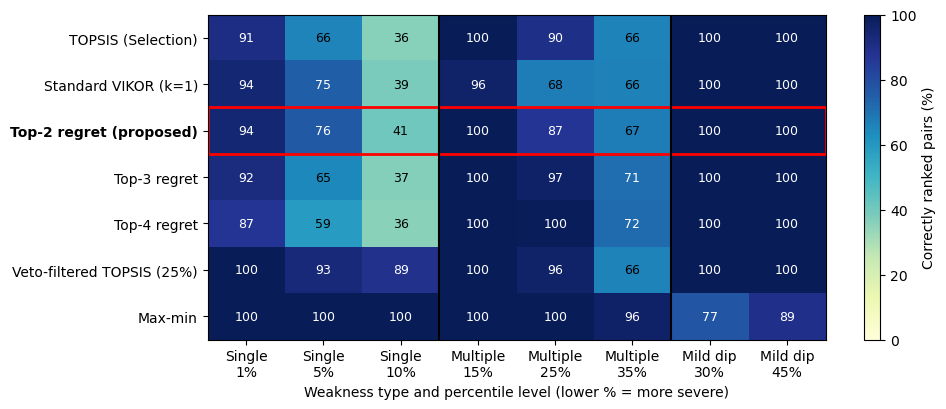

In [63]:
from matplotlib.patches import Rectangle
rows_main = ['Selection (TOPSIS)', 'VIKOR k=1, v=0.5', 'Trust k=2 (proposed)', 'Top-k VIKOR k=3',
             'Top-k VIKOR k=4', 'TOPSIS + veto 25%', 'Max-min']
labels = ['TOPSIS (Selection)', 'Standard VIKOR (k=1)', 'Top-2 regret (proposed)', 'Top-3 regret',
          'Top-4 regret', 'Veto-filtered TOPSIS (25%)', 'Max-min']
cols = ['B at 1%', 'B at 5%', 'B at 10%', 'C at 15%', 'C at 25%', 'C at 35%', 'E at 30%', 'E at 45%']
T = pd.read_csv('trustcloud_grid.csv', index_col=0).loc[rows_main, cols]

fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(T.values, cmap='YlGnBu', vmin=0, vmax=100, aspect='auto')
for i in range(T.shape[0]):
    for j in range(T.shape[1]):
        v = T.values[i, j]
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=9,
                color='white' if v > 70 else 'black')
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(['Single\n1%', 'Single\n5%', 'Single\n10%', 'Multiple\n15%', 'Multiple\n25%',
                    'Multiple\n35%', 'Mild dip\n30%', 'Mild dip\n45%'])
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
for x in [2.5, 5.5]:
    ax.axvline(x, color='black', lw=1.5)                      # separate the three weakness types
ax.add_patch(Rectangle((-0.5, 1.5), len(cols), 1, fill=False, edgecolor='red', lw=2))   # highlight proposed
ax.set_xlabel('Weakness type and percentile level (lower % = more severe)')
cbar = plt.colorbar(im, ax=ax); cbar.set_label('Correctly ranked pairs (%)')
ax.get_yticklabels()[2].set_fontweight('bold')
plt.tight_layout()
plt.savefig('fig_grid_heatmap.png', dpi=300); plt.savefig('fig_grid_heatmap.pdf'); plt.show()

In [64]:
held = pd.DataFrame([row for s in range(100, 120) for row in synthetic_once(s, 0.5)])
held.groupby('Method').agg(['mean', 'std']).round(1)

alpha      A above B %      A above C %      
           mean  std        mean  std        mean   std
Method                                                 
Selection   0.5  0.0        79.7  7.6        99.9   0.4
Trust k=1   0.5  0.0        87.7  6.1        73.7  14.9
Trust k=2   0.5  0.0        88.3  5.4        99.9   0.4

In [65]:
for sigma in [0.01, 0.05]:
    rng = np.random.default_rng(123)
    runs = [run_pipeline_from_raw(np.clip(X * rng.normal(1, sigma, X.shape), 1e-6, None),
                                  w_bwm, transform_idx, cost_idx)[1].values for _ in range(200)]
    for K in [20, 50, 100]:
        m = base_s <= K
        tau_div = kendalltau(base_s[m], base_t[m])[0]
        tn = np.array([kendalltau(base_t[m], rt[m])[0] for rt in runs])
        print(f"sigma={sigma:.0%} Top-{K}: tau_div={tau_div:.3f} noisy mean={tn.mean():.3f} p={np.mean(tn <= tau_div):.3f}")

sigma=1% Top-20: tau_div=0.726 noisy mean=0.675 p=0.750
sigma=1% Top-50: tau_div=0.851 noisy mean=0.832 p=0.820
sigma=1% Top-100: tau_div=0.859 noisy mean=0.837 p=0.930
sigma=5% Top-20: tau_div=0.726 noisy mean=0.089 p=1.000
sigma=5% Top-50: tau_div=0.851 noisy mean=0.409 p=1.000
sigma=5% Top-100: tau_div=0.859 noisy mean=0.468 p=1.000


In [66]:
# ============================================================
# E2 - Step 1: normalisation variants under IDENTICAL weights
# ============================================================
def weights_from_raw(X_raw, alpha=0.5):
    """CRITIC (on min-max z) + BWM blend. Computed ONCE per dataset and shared by every method."""
    Xt_ = X_raw.copy()
    for j in transform_idx:
        Xt_[:, j] = np.log1p(np.clip(Xt_[:, j], 0, None))
    Z_ = (Xt_ - Xt_.min(0)) / (Xt_.max(0) - Xt_.min(0))
    Zb_ = Z_.copy(); Zb_[:, cost_idx] = 1 - Zb_[:, cost_idx]        # benefit-oriented, 1 = best
    C_ = Z_.std(0) * (1 - np.corrcoef(Zb_.T)).sum(1)                # same R as before (sign-flip = benefit-orient)
    w_ = alpha * C_ / C_.sum() + (1 - alpha) * w_bwm
    return w_ / w_.sum(), Xt_, Zb_

def normalise(Xt_, kind):
    """Benefit-oriented matrix (higher = better) under one of three normalisations."""
    if kind == 'minmax':
        R_ = (Xt_ - Xt_.min(0)) / (Xt_.max(0) - Xt_.min(0))
        R_[:, cost_idx] = 1 - R_[:, cost_idx]
    elif kind == 'vector':
        R_ = Xt_ / np.sqrt((Xt_**2).sum(0))
        R_[:, cost_idx] *= -1                                         # linear sign inversion
    elif kind == 'reciprocal':                                        # Lu & Yuan (2018) Eq. 3 form
        Y_ = Xt_.copy()
        assert (Y_[:, cost_idx] > 0).all(), "reciprocal needs strictly positive cost values"
        Y_[:, cost_idx] = 1.0 / Y_[:, cost_idx]
        R_ = Y_ / np.sqrt((Y_**2).sum(0))
    return R_

def topsis(R_, w_):
    V_ = w_ * R_
    Dp = np.sqrt(((V_ - V_.max(0))**2).sum(1)); Dm = np.sqrt(((V_ - V_.min(0))**2).sum(1))
    return Dm / (Dp + Dm)                                             # higher = better

def vikor_topk(R_, w_, k, v=0.5):
    gap_ = w_ * (R_.max(0) - R_) / (R_.max(0) - R_.min(0))           # range-normalised shortfall
    S_, g = gap_.sum(1), np.sort(gap_, axis=1)[:, ::-1]
    return v * nrm(S_) + (1 - v) * nrm(g[:, :k].mean(1))             # lower = better

def method_ranks_e2(Xa):
    out = method_ranks_all(Xa)                                        # existing rows, unchanged
    w_, Xt_, _ = weights_from_raw(Xa)
    for kind in ['reciprocal', 'vector', 'minmax']:
        out[f'TOPSIS [{kind}]'] = rank_low(-topsis(normalise(Xt_, kind), w_))
    for kind in ['reciprocal', 'minmax']:                             # vector = minmax for VIKOR
        for k in [1, 2]:
            out[f'VIKOR k={k} [{kind}]'] = rank_low(vikor_topk(normalise(Xt_, kind), w_, k))
    return out

# ---------- Sanity checks (all must print True before any benchmark is run) ----------
chk = method_ranks_e2(X)
w_chk, Xt_chk, _ = weights_from_raw(X)
print("1 Weights = w_final from Step 10:        ", np.allclose(w_chk, w_final))
print("2 TOPSIS[minmax] = old Selection:        ", (chk['TOPSIS [minmax]'] == chk['Selection (TOPSIS)']).all())
print("3 VIKOR k=1[minmax] = old VIKOR k=1,v=.5: ", (chk['VIKOR k=1 [minmax]'] == chk['VIKOR k=1, v=0.5']).all())
print("4 VIKOR k=2[minmax] = old Trust k=2:      ", (chk['VIKOR k=2 [minmax]'] == chk['Trust k=2 (proposed)']).all())
print("5 VIKOR vector = VIKOR minmax:           ",
      (rank_low(vikor_topk(normalise(Xt_chk, 'vector'), w_chk, 2)) == chk['VIKOR k=2 [minmax]']).all())
print("6 TOPSIS[vector] = v2 cell-35 formula:   ",
      (chk['TOPSIS [vector]'] == rank_low(-topsis(Nn, w_final))).all())

1 Weights = w_final from Step 10:         True
2 TOPSIS[minmax] = old Selection:         True
3 VIKOR k=1[minmax] = old VIKOR k=1,v=.5:  True
4 VIKOR k=2[minmax] = old Trust k=2:       True
5 VIKOR vector = VIKOR minmax:            True
6 TOPSIS[vector] = v2 cell-35 formula:    True


In [67]:
# ============================================================
# E2 - Step 2: main benchmark (seeds 0-19, b=0.02, c=0.20, e=0.40)
# ============================================================
def bench_e2_once(seed, b=0.02, c=0.20, e=0.40):
    global rng
    rng = np.random.default_rng(seed)
    planted, types = [], []
    for _ in range(10): planted.append(make(np.full(n, 0.80))); types.append('A')
    for j in range(n):
        lv = np.full(n, 0.90); lv[j] = b; planted.append(make(lv)); types.append('B')
    for _ in range(10):
        lv = np.full(n, 0.90); lv[rng.choice(n, 3, replace=False)] = c
        planted.append(make(lv)); types.append('C')
    for _ in range(10): planted.append(make(np.full(n, 0.50))); types.append('M')
    for _ in range(10):
        lv = np.full(n, 0.95); lv[rng.choice(n)] = e; planted.append(make(lv)); types.append('E')
    types = np.array(types); Xa = np.vstack([X, np.array(planted)]); ix = np.arange(N, N + len(types))
    rows = []
    for name, r in method_ranks_e2(Xa).items():
        r = r[ix]; A, B, C, M, E = [r[types == t] for t in 'ABCME']
        rows.append({'Seed': seed, 'Method': name,
                     'A above B %': 100 * np.mean(A[:, None] < B[None, :]),
                     'A above C %': 100 * np.mean(A[:, None] < C[None, :]),
                     'E above M %': 100 * np.mean(E[:, None] < M[None, :])})
    return rows

show = ['TOPSIS [reciprocal]', 'TOPSIS [vector]', 'TOPSIS [minmax]',
        'VIKOR k=1 [reciprocal]', 'VIKOR k=2 [reciprocal]',
        'VIKOR k=1 [minmax]', 'VIKOR k=2 [minmax]',
        'Top-k VIKOR k=3', 'Top-k VIKOR k=4', 'Top-k VIKOR k=all',
        'VIKOR k=1, v=0.0', 'VIKOR k=1, v=0.25', 'VIKOR k=1, v=0.75',
        'OWA-VIKOR', 'Max-min', 'TOPSIS + veto 5%', 'TOPSIS + veto 10%', 'TOPSIS + veto 25%']

e2_main = pd.DataFrame([row for s in range(20) for row in bench_e2_once(s)])
e2_main.to_csv('e2_main_per_seed.csv', index=False)          # kept for the statistics in E5
e2_main_table = (e2_main.groupby('Method')[['A above B %', 'A above C %', 'E above M %']]
                 .agg(['mean', 'std']).round(1).loc[show])
e2_main_table.to_csv('e2_main_table.csv')
e2_main_table

A above B %      A above C %       E above M %     
                              mean  std        mean   std        mean  std
Method                                                                    
TOPSIS [reciprocal]           11.1  0.0        47.4  11.4       100.0  0.0
TOPSIS [vector]               70.1  5.2        87.0  10.5       100.0  0.0
TOPSIS [minmax]               84.8  6.9       100.0   0.0       100.0  0.0
VIKOR k=1 [reciprocal]        61.7  9.4        86.8   9.1       100.0  0.0
VIKOR k=2 [reciprocal]        74.6  6.2        85.2  10.8       100.0  0.0
VIKOR k=1 [minmax]            91.1  4.6        70.5  14.4       100.0  0.0
VIKOR k=2 [minmax]            91.7  4.7        99.2   2.0       100.0  0.0
Top-k VIKOR k=3               85.7  6.8       100.0   0.0       100.0  0.0
Top-k VIKOR k=4               78.2  9.1       100.0   0.0       100.0  0.0
Top-k VIKOR k=all             61.2  8.6       100.0   0.0       100.0  0.0
VIKOR k=1, v=0.0              92.2  5.2        67.5  14.1        89.0  8.5
VIKOR k=1, v=0.25             91.9  4.9        67.5  14.1        99.0  3.1
VIKOR k=1, v=0.75             81.9  8.6       100.0   0.2       100.0  0.0
OWA-VIKOR                     73.3  9.8       100.0   0.0       100.0  0.0
Max-min                      100.0  0.0       100.0   0.0        80.8  7.5
TOPSIS + veto 5%              99.4  2.5       100.0   0.0       100.0  0.0
TOPSIS + veto 10%             99.4  2.5       100.0   0.0       100.0  0.0
TOPSIS + veto 25%             99.4  2.5       100.0   0.0       100.0  0.0

In [68]:
# ============================================================
# E2 - Step 3: held-out benchmark (seeds 100-119, same settings)
# ============================================================
e2_held = pd.DataFrame([row for s in range(100, 120) for row in bench_e2_once(s)])
e2_held.to_csv('e2_held_per_seed.csv', index=False)
e2_held_table = (e2_held.groupby('Method')[['A above B %', 'A above C %', 'E above M %']]
                 .agg(['mean', 'std']).round(1).loc[show])
e2_held_table.to_csv('e2_held_table.csv')
e2_held_table

A above B %       A above C %       E above M %      
                              mean   std        mean   std        mean   std
Method                                                                      
TOPSIS [reciprocal]           11.1   0.0        49.5  15.4       100.0   0.0
TOPSIS [vector]               72.7   5.2        89.2   9.1       100.0   0.0
TOPSIS [minmax]               79.7   7.6        99.9   0.4       100.0   0.0
VIKOR k=1 [reciprocal]        61.8  10.3        88.8   8.9       100.0   0.0
VIKOR k=2 [reciprocal]        71.9   5.5        86.2   9.9       100.0   0.0
VIKOR k=1 [minmax]            87.7   6.1        73.6  14.8       100.0   0.0
VIKOR k=2 [minmax]            88.4   5.2        99.9   0.4       100.0   0.0
Top-k VIKOR k=3               81.2   7.7       100.0   0.0       100.0   0.0
Top-k VIKOR k=4               74.9  10.1       100.0   0.0       100.0   0.0
Top-k VIKOR k=all             59.1  10.8       100.0   0.0       100.0   0.0
VIKOR k=1, v=0.0              90.0   3.4        72.5  14.1        81.8  13.4
VIKOR k=1, v=0.25             88.5   5.4        72.5  14.1       100.0   0.0
VIKOR k=1, v=0.75             76.4   8.6        99.5   2.0       100.0   0.0
OWA-VIKOR                     68.9  10.1       100.0   0.0       100.0   0.0
Max-min                      100.0   0.0       100.0   0.0        75.4  16.4
TOPSIS + veto 5%              96.1   5.4        99.9   0.4       100.0   0.0
TOPSIS + veto 10%             96.1   5.4        99.9   0.4       100.0   0.0
TOPSIS + veto 25%             96.1   5.4       100.0   0.0       100.0   0.0

In [69]:
# ============================================================
# E2 - Step 4: diagnostic for reciprocal TOPSIS (explains Step 2, adds no new result)
# ============================================================
def plant_e2(seed, b=0.02, c=0.20, e=0.40):
    """Same generator as bench_e2_once, returns the data instead of scores."""
    global rng
    rng = np.random.default_rng(seed)
    planted, types = [], []
    for _ in range(10): planted.append(make(np.full(n, 0.80))); types.append('A')
    for j in range(n):
        lv = np.full(n, 0.90); lv[j] = b; planted.append(make(lv)); types.append('B')
    for _ in range(10):
        lv = np.full(n, 0.90); lv[rng.choice(n, 3, replace=False)] = c
        planted.append(make(lv)); types.append('C')
    for _ in range(10): planted.append(make(np.full(n, 0.50))); types.append('M')
    for _ in range(10):
        lv = np.full(n, 0.95); lv[rng.choice(n)] = e; planted.append(make(lv)); types.append('E')
    types = np.array(types)
    return np.vstack([X, np.array(planted)]), types, np.arange(N, N + len(types))

kinds = ['reciprocal', 'vector', 'minmax']

# (a) Per-criterion detection: B number j has its weakness on criterion j
rows = []
for s in range(20):
    Xa, types, ix = plant_e2(s)
    w_, Xt_, _ = weights_from_raw(Xa)
    for kind in kinds:
        r = rank_low(-topsis(normalise(Xt_, kind), w_))[ix]
        A, B = r[types == 'A'], r[types == 'B']
        for j in range(n):
            rows.append({'Seed': s, 'Norm': kind, 'Weak criterion': criteria[j],
                         'A above B %': 100 * np.mean(A < B[j])})
diag = pd.DataFrame(rows)
per_crit = diag.pivot_table(index='Weak criterion', columns='Norm', values='A above B %',
                            aggfunc='mean', sort=False)[kinds].round(1)
print("(a) Per-criterion detection, seeds 0-19:")
print(per_crit)
print("\nCheck: average of each column = Step 2 'A above B %':",
      per_crit.mean().round(1).to_dict())

# (b) Mechanism: how much of the distance to the ideal comes from the 2 cost criteria?
print("\n(b) Real data only, no planted services:")
for kind in kinds:
    R_ = normalise(Xt, kind)
    V_ = w_final * R_
    dp2 = (V_ - V_.max(0))**2
    share = dp2[:, cost_idx].sum(1) / dp2.sum(1)
    Dp = np.sqrt(dp2.sum(1))
    print(f"{kind:10s}  median share of D+ from cost criteria = {np.median(share):.2f}   "
          f"D+ spread (5th-95th pct) = {np.percentile(Dp, 5):.4f} - {np.percentile(Dp, 95):.4f}")

(a) Per-criterion detection, seeds 0-19:
Norm            reciprocal  vector  minmax
Weak criterion                            
ResponseTime           0.0    30.0   100.0
Availability           0.0   100.0   100.0
Throughput             0.0   100.0   100.0
Successability         0.0   100.0   100.0
Reliability            0.0   100.0   100.0
Compliance             0.0     0.5    30.0
BestPractices          0.0     0.0    64.0
Latency              100.0   100.0    69.5
Documentation          0.0   100.0   100.0

Check: average of each column = Step 2 'A above B %': {'reciprocal': 11.1, 'vector': 70.1, 'minmax': 84.8}

(b) Real data only, no planted services:
reciprocal  median share of D+ from cost criteria = 0.95   D+ spread (5th-95th pct) = 0.0092 - 0.0129
vector      median share of D+ from cost criteria = 0.28   D+ spread (5th-95th pct) = 0.0019 - 0.0047
minmax      median share of D+ from cost criteria = 0.14   D+ spread (5th-95th pct) = 0.0811 - 0.1932


In [70]:
# ============================================================
# E2 - Step 4b: is reciprocal TOPSIS almost a Latency ranking? (real data)
# ============================================================
tau_rows = {}
for kind in ['reciprocal', 'vector', 'minmax']:
    R_ = normalise(Xt, kind)
    score = topsis(R_, w_final)
    tau_rows[kind] = [kendalltau(score, R_[:, j])[0] for j in range(n)]   # R_ is benefit-oriented
tau_tab = pd.DataFrame(tau_rows, index=criteria).round(3)
print("Kendall tau between TOPSIS score and each single criterion (real QWS data):")
print(tau_tab)

Kendall tau between TOPSIS score and each single criterion (real QWS data):
                reciprocal  vector  minmax
ResponseTime         0.256   0.293   0.233
Availability         0.320   0.255   0.299
Throughput           0.385   0.440   0.348
Successability       0.345   0.281   0.320
Reliability          0.325   0.318   0.497
Compliance           0.096   0.089   0.139
BestPractices        0.233   0.243   0.388
Latency              0.519   0.519   0.305
Documentation        0.251   0.269   0.293


In [71]:
# ============================================================
# E2 - Step 4c: does reciprocal TOPSIS reduce to "distance from the worst" (D-)? (real data)
# ============================================================
for kind in ['reciprocal', 'vector', 'minmax']:
    V_ = w_final * normalise(Xt, kind)
    Dp = np.sqrt(((V_ - V_.max(0))**2).sum(1))
    Dm = np.sqrt(((V_ - V_.min(0))**2).sum(1))
    C_ = Dm / (Dp + Dm)
    print(f"{kind:10s} tau(score, D-) = {kendalltau(C_, Dm)[0]:.3f}   "
          f"tau(score, -D+) = {kendalltau(C_, -Dp)[0]:.3f}   "
          f"D+ 95/5 ratio = {np.percentile(Dp, 95)/np.percentile(Dp, 5):.2f}   "
          f"D- 95/5 ratio = {np.percentile(Dm, 95)/np.percentile(Dm, 5):.2f}")

reciprocal tau(score, D-) = 0.877   tau(score, -D+) = 0.668   D+ 95/5 ratio = 1.41   D- 95/5 ratio = 1.81
vector     tau(score, D-) = 0.842   tau(score, -D+) = 0.923   D+ 95/5 ratio = 2.54   D- 95/5 ratio = 1.60
minmax     tau(score, D-) = 0.828   tau(score, -D+) = 0.926   D+ 95/5 ratio = 2.38   D- 95/5 ratio = 1.51


In [72]:
# ============================================================
# E2 - Step 5: severity grid with normalisation rows (seeds 0-19)
# ============================================================
settings = [('B', 0.01), ('B', 0.05), ('B', 0.10), ('C', 0.15), ('C', 0.25), ('C', 0.35),
            ('E', 0.30), ('E', 0.45)]
default = {'B': 0.02, 'C': 0.20, 'E': 0.40}
metric  = {'B': 'A above B %', 'C': 'A above C %', 'E': 'E above M %'}
rows = []
for typ, lvl in settings:
    p = dict(default); p[typ] = lvl
    for s in range(20):
        for r in bench_e2_once(s, p['B'], p['C'], p['E']):
            rows.append({'Method': r['Method'], 'Setting': f'{typ}{round(lvl*100)}',
                         'Seed': s, 'Score': r[metric[typ]]})
grid_e2 = pd.DataFrame(rows)
grid_e2.to_csv('e2_grid_per_seed.csv', index=False)
cols = ['B1', 'B5', 'B10', 'C15', 'C25', 'C35', 'E30', 'E45']
grid_e2_table = (grid_e2.pivot_table(index='Method', columns='Setting', values='Score', aggfunc='mean')
                 .loc[show, cols].round(1))
grid_e2_table.to_csv('e2_grid_table.csv')
print("Check vs old grid (must be 90.7/65.6/36.2/100/90.2/65.8/100/100):",
      grid_e2_table.loc['TOPSIS [minmax]'].tolist())
grid_e2_table

Check vs old grid (must be 90.7/65.6/36.2/100/90.2/65.8/100/100): [90.7, 65.6, 36.2, 100.0, 90.2, 65.8, 100.0, 100.0]


Setting,B1,B5,B10,C15,C25,C35,E30,E45
Method,,,,,,,,
TOPSIS [reciprocal],11.1,11.1,11.1,50.6,43.0,39.0,100.0,100.0
TOPSIS [vector],71.7,66.2,48.2,95.4,80.0,73.4,100.0,100.0
TOPSIS [minmax],90.7,65.6,36.2,100.0,90.2,65.8,100.0,100.0
VIKOR k=1 [reciprocal],72.3,34.3,23.9,94.7,75.7,55.9,100.0,100.0
VIKOR k=2 [reciprocal],77.9,59.4,37.7,95.8,81.4,66.1,100.0,100.0
VIKOR k=1 [minmax],94.4,74.8,38.6,96.2,67.5,66.2,100.0,100.0
VIKOR k=2 [minmax],94.4,76.2,40.6,100.0,87.4,67.2,100.0,100.0
Top-k VIKOR k=3,91.7,64.8,36.7,100.0,96.8,71.0,100.0,100.0
Top-k VIKOR k=4,87.4,58.9,35.6,100.0,99.5,71.8,100.0,100.0


In [73]:
# ============================================================
# E2 - Step 6: Lu & Yuan (2018) exact scheme as one extra row
# ============================================================
def ly2018(X_raw, sw=None):
    """Lu & Yuan (2018) exact scheme, Eqs. (2)-(13). Raw values, no log. Returns closeness T and entropy weights."""
    m_ = X_raw.shape[0]
    Y = X_raw.astype(float).copy()
    assert (Y[:, cost_idx] > 0).all(), "Eq. 3 needs positive cost values"
    Y[:, cost_idx] = 1.0 / Y[:, cost_idx]                       # Eq. 3: reciprocal for negative attributes
    NS = Y / np.sqrt((Y**2).sum(0))                              # Eqs. 2-3: vector normalisation
    P = NS / NS.sum(0)                                           # Eq. 4: characteristic proportion (from M2)
    plogp = np.where(P > 0, P * np.log(np.where(P > 0, P, 1)), 0.0)
    e = -plogp.sum(0) / np.log(m_)                               # Eq. 5: entropy
    d = 1 - e                                                    # Eq. 6: difference coefficient
    ew = d / d.sum()                                             # Eq. 7: entropy weight
    sw = np.full(X_raw.shape[1], 1 / X_raw.shape[1]) if sw is None else sw   # equal preference (their Exp. 1)
    cw = ew * sw                                                 # Eq. 9: combined weight = product
    WS = cw * NS                                                 # Eq. 10
    Dp = np.sqrt(((WS - WS.max(0))**2).sum(1))                   # Eqs. 11-12 (max/min ideals)
    Dm = np.sqrt(((WS - WS.min(0))**2).sum(1))
    return Dm / (Dp + Dm), ew                                    # Eq. 13

# (a) Validation: reproduce Lu & Yuan's own weather example (their Tables 4, 7, 10)
W_ly = np.array([[125.44,100,13.5,86,86.4,78,80,125.33,91], [129.67,100,13.2,86,84.1,78,80,129.56,90],
                 [261,100,1.8,71,58.1,78,80,229.5,94],      [160,100,2.2,71,73.3,78,84,74,32],
                 [190.5,86,12.4,71,54,89,80,188.5,8],       [1463.5,100,2.4,71,53.5,78,84,1410.5,42],
                 [409.33,49,1.8,27,41.4,89,72,401.5,96]])
T_ly, ew_ly = ly2018(W_ly)
print("(a) Entropy weights match their Table 7:",
      np.allclose(ew_ly.round(4), [0.1613,0.0223,0.3430,0.0434,0.0306,0.0019,0.0011,0.2258,0.1707]))
print("    Scores match their Table 10:      ",
      np.allclose(T_ly.round(4), [0.7724,0.7586,0.3103,0.4817,0.5748,0.1202,0.2672]))

# (b) Entropy weights on QWS v2.0 (descriptive)
_, ew_q = ly2018(X)
print("\n(b) Weights on QWS v2.0:")
print(pd.DataFrame({'Entropy (L&Y)': ew_q.round(4), 'Our final': w_final.round(4)}, index=criteria))

# (c) Benchmark: same generator and seeds as Steps 2, 3 and 5
def ly_once(seed, b=0.02, c=0.20, e=0.40):
    Xa, types, ix = plant_e2(seed, b, c, e)
    r = rank_low(-ly2018(Xa)[0])[ix]
    A, B, C, M, E = [r[types == t] for t in 'ABCME']
    return {'A above B %': 100 * np.mean(A[:, None] < B[None, :]),
            'A above C %': 100 * np.mean(A[:, None] < C[None, :]),
            'E above M %': 100 * np.mean(E[:, None] < M[None, :])}
ly_main = pd.DataFrame([ly_once(s) for s in range(20)])
ly_held = pd.DataFrame([ly_once(s) for s in range(100, 120)])
print("\n(c) Lu & Yuan exact scheme on the benchmark:")
print(pd.concat({'main (0-19)': ly_main.agg(['mean', 'std']),
                 'held-out (100-119)': ly_held.agg(['mean', 'std'])}).round(1))

ly_grid = {}
for typ, lvl in settings:
    p = dict(default); p[typ] = lvl
    ly_grid[f'{typ}{round(lvl*100)}'] = np.mean([ly_once(s, p['B'], p['C'], p['E'])[metric[typ]] for s in range(20)])
print("\n    Grid (seeds 0-19):")
print(pd.Series(ly_grid).round(1).to_frame('L&Y exact').T)
pd.concat({'main': ly_main, 'held': ly_held}).to_csv('e2_ly2018_per_seed.csv')

(a) Entropy weights match their Table 7: True
    Scores match their Table 10:       True

(b) Weights on QWS v2.0:
                Entropy (L&Y)  Our final
ResponseTime           0.1191     0.0946
Availability           0.0167     0.1131
Throughput             0.1714     0.0966
Successability         0.0176     0.1166
Reliability            0.0040     0.1949
Compliance             0.0034     0.0919
BestPractices          0.0025     0.0858
Latency                0.4185     0.0933
Documentation          0.2468     0.1132

(c) Lu & Yuan exact scheme on the benchmark:
                         A above B %  A above C %  E above M %
main (0-19)        mean          1.4         20.4        100.0
                   std           1.9         10.0          0.0
held-out (100-119) mean          2.3         16.6        100.0
                   std           1.9         10.5          0.0

    Grid (seeds 0-19):
            B1   B5  B10   C15   C25   C35    E30    E45
L&Y exact  1.4  1.3  1.3  20.5  

In [74]:
# ============================================================
# E3 - Step 1: independent test benchmark (generator + metrics, no results yet) - Reporting (fixed now): Table 1 = overall means of all metrics; Tables 2–4 = A>C by m,
 # A>C by c, A>B by b for 10 key methods. No other breakdowns unless labelled exploratory.
# ============================================================
def plant_e3(seed, b, m, c, e=0.50):
    """New generator: B = one dip at b; C = m dips at c; E = one dip at e (median)."""
    global rng
    rng = np.random.default_rng(seed)
    planted, types = [], []
    for _ in range(10): planted.append(make(np.full(n, 0.80))); types.append('A')
    for j in range(n):
        lv = np.full(n, 0.90); lv[j] = b; planted.append(make(lv)); types.append('B')
    for _ in range(10):
        lv = np.full(n, 0.90); lv[rng.choice(n, m, replace=False)] = c
        planted.append(make(lv)); types.append('C')
    for _ in range(10): planted.append(make(np.full(n, 0.50))); types.append('M')
    for _ in range(10):
        lv = np.full(n, 0.95); lv[rng.choice(n)] = e; planted.append(make(lv)); types.append('E')
    types = np.array(types)
    return np.vstack([X, np.array(planted)]), types, np.arange(N, N + len(types))

def score_e3(Xa, types, ix):
    rows = []
    for name, r_all in method_ranks_e2(Xa).items():
        r = r_all[ix]; A, B, C, M, E = [r[types == t] for t in 'ABCME']
        W = np.concatenate([B, C])                                    # all planted weak services
        row = {'Method': name,
               'A above B %': 100 * np.mean(A[:, None] < B[None, :]),
               'A above C %': 100 * np.mean(A[:, None] < C[None, :]),
               'E above M %': 100 * np.mean(E[:, None] < M[None, :]),
               'E above A %': 100 * np.mean(E[:, None] < A[None, :]),  # NEW: no false demotion
               'Displacement': W.mean() - A.mean()}                    # NEW: ranks below A (higher = better)
        for K in [10, 20, 50]:
            row[f'Leak@{K}'] = int(np.sum(W <= K))                     # NEW: weak services in top-K
        rows.append(row)
    return rows

# ---------- Smoke test: structure only, no scores printed ----------
Xa_t, types_t, ix_t = plant_e3(200, b=0.03, m=4, c=0.18)
print("Planted per type:", pd.Series(types_t).value_counts().sort_index().to_dict())
print("Total services:", len(Xa_t))
out_t = score_e3(Xa_t, types_t, ix_t)
print("Methods scored:", len(out_t), "| Columns:", list(out_t[0].keys())[1:])

Planted per type: {'A': 10, 'B': 9, 'C': 10, 'E': 10, 'M': 10}
Total services: 2549
Methods scored: 22 | Columns: ['A above B %', 'A above C %', 'E above M %', 'E above A %', 'Displacement', 'Leak@10', 'Leak@20', 'Leak@50']


In [75]:
# ============================================================
# E3 - Step 2: run the independent test benchmark (pre-declared, run once)
# ============================================================
def score_e3_all(Xa, types, ix):
    ranks = method_ranks_e2(Xa)
    ranks['Lu & Yuan exact'] = rank_low(-ly2018(Xa)[0])          # same method set as E2
    rows = []
    for name, r_all in ranks.items():
        r = r_all[ix]; A, B, C, M, E = [r[types == t] for t in 'ABCME']
        W = np.concatenate([B, C])
        row = {'Method': name,
               'A above B %': 100 * np.mean(A[:, None] < B[None, :]),
               'A above C %': 100 * np.mean(A[:, None] < C[None, :]),
               'E above M %': 100 * np.mean(E[:, None] < M[None, :]),
               'E above A %': 100 * np.mean(E[:, None] < A[None, :]),
               'Displacement': W.mean() - A.mean()}
        for K in [10, 20, 50]:
            row[f'Leak@{K}'] = int(np.sum(W <= K))
        rows.append(row)
    return rows

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
rows = []
for b in [0.03, 0.07]:
    for m in [2, 4, 5]:
        for c in [0.18, 0.30]:
            for s in range(200, 220):
                Xa, types, ix = plant_e3(s, b, m, c)
                for r in score_e3_all(Xa, types, ix):
                    r.update({'b': b, 'm': m, 'c': c, 'Seed': s}); rows.append(r)
e3 = pd.DataFrame(rows)
e3.to_csv('e3_per_seed.csv', index=False)

show_e3 = show + ['Lu & Yuan exact']
metrics = ['A above B %', 'A above C %', 'E above M %', 'E above A %', 'Displacement', 'Leak@10', 'Leak@20', 'Leak@50']
e3_overall = e3.groupby('Method')[metrics].mean().loc[show_e3].round(1)
e3_overall.to_csv('e3_overall.csv')
print("TABLE 1 - All 12 settings x 20 seeds (means)")
print(e3_overall)

key = ['Lu & Yuan exact', 'TOPSIS [reciprocal]', 'TOPSIS [vector]', 'TOPSIS [minmax]',
       'VIKOR k=1 [minmax]', 'VIKOR k=2 [minmax]', 'Top-k VIKOR k=3', 'Top-k VIKOR k=all',
       'Max-min', 'TOPSIS + veto 25%']
print("\nTABLE 2 - A above C % by number of dips m")
print(e3.pivot_table(index='Method', columns='m', values='A above C %').loc[key].round(1))
print("\nTABLE 3 - A above C % by dip level c")
print(e3.pivot_table(index='Method', columns='c', values='A above C %').loc[key].round(1))
print("\nTABLE 4 - A above B % by single-dip level b")
print(e3.pivot_table(index='Method', columns='b', values='A above B %').loc[key].round(1))

TABLE 1 - All 12 settings x 20 seeds (means)
                        A above B %  A above C %  E above M %  E above A %  Displacement  Leak@10  Leak@20  Leak@50
Method                                                                                                             
TOPSIS [reciprocal]            11.1         56.4        100.0         97.7         105.0      0.0      0.0      0.0
TOPSIS [vector]                65.4         86.6        100.0         93.0         483.9      0.4      2.3      3.2
TOPSIS [minmax]                65.3         86.9        100.0        100.0         471.9      0.1      0.7      3.1
VIKOR k=1 [reciprocal]         41.6         79.4        100.0        100.0         408.1      0.0      0.0      1.0
VIKOR k=2 [reciprocal]         60.7         84.1        100.0        100.0         451.1      0.1      0.7      2.8
VIKOR k=1 [minmax]             72.8         82.4        100.0         99.8         599.5      0.0      0.7      2.2
VIKOR k=2 [minmax]         

In [76]:
## E4 — Real-data rank shifts (pre-declared, run once)
## Data: all 2,500 real QWS services, no planted services. Weights: w_final (fixed).
## Rankings: L&Y exact, TOPSIS reciprocal / vector / min-max, top-2 VIKOR (min-max).
## Pairwise: Kendall tau, median and 90th-percentile |rank change|, Top-50 overlap.
## Examples: exact ranks of IDs 116, 2192, 1416, 2328 (named in the v2 paper).
## Replacement for the dropped "rank 4 -> 1,699" example, by a fixed rule: the service in
## the vector-TOPSIS Top-50 with the largest drop under min-max TOPSIS.


In [77]:
# ============================================================
# E4 - Step 1: how much do the real QWS rankings change? (all 2,500 services)
# ============================================================
from itertools import combinations
real = {'L&Y exact':           rank_low(-ly2018(X)[0]),
        'TOPSIS [reciprocal]': rank_low(-topsis(normalise(Xt, 'reciprocal'), w_final)),
        'TOPSIS [vector]':     rank_low(-topsis(normalise(Xt, 'vector'), w_final)),
        'TOPSIS [minmax]':     rank_low(-topsis(normalise(Xt, 'minmax'), w_final)),
        'VIKOR k=2 [minmax]':  rank_low(vikor_topk(normalise(Xt, 'minmax'), w_final, 2))}
print("Check: TOPSIS [minmax] = Step 11 rank_select:", (real['TOPSIS [minmax]'] == rank_select.values).all())

# (a) Pairwise agreement over ALL services
pair_rows = []
for a, b in combinations(real, 2):
    ra, rb = real[a], real[b]
    pair_rows.append({'Pair': f'{a} vs {b}',
                      'Kendall tau': kendalltau(ra, rb)[0],
                      'Median |rank change|': np.median(np.abs(ra - rb)),
                      '90th pct |rank change|': np.percentile(np.abs(ra - rb), 90),
                      'Top-50 overlap': len(set(np.where(ra <= 50)[0]) & set(np.where(rb <= 50)[0]))})
e4_pairs = pd.DataFrame(pair_rows).round(3)
e4_pairs.to_csv('e4_pairs.csv', index=False)
print("\n(a) Agreement between rankings (all 2,500 services)")
print(e4_pairs.to_string(index=False))

# (b) Exact ranks of the example services
ex_ids = [116, 2192, 1416, 2328]
ex = pd.DataFrame({k: v[ex_ids] for k, v in real.items()}, index=df.ServiceName[ex_ids].str[:25]).astype(int)
print("\n(b) Exact ranks of the example services")
print(ex)

# (c) Pre-declared rule: the largest drop from vector-TOPSIS Top-50 to min-max TOPSIS
top50 = np.where(real['TOPSIS [vector]'] <= 50)[0]
i_max = top50[np.argmax(real['TOPSIS [minmax]'][top50] - real['TOPSIS [vector]'][top50])]
print(f"\n(c) Largest drop within vector Top-50: ID {i_max} {df.ServiceName[i_max][:30]} -> ranks:",
      {k: int(v[i_max]) for k, v in real.items()})

Check: TOPSIS [minmax] = Step 11 rank_select: True

(a) Agreement between rankings (all 2,500 services)
                                     Pair  Kendall tau  Median |rank change|  90th pct |rank change|  Top-50 overlap
         L&Y exact vs TOPSIS [reciprocal]        0.637                 255.0                   702.1              46
             L&Y exact vs TOPSIS [vector]        0.551                 314.5                   915.0              11
             L&Y exact vs TOPSIS [minmax]        0.403                 447.0                  1066.1               4
          L&Y exact vs VIKOR k=2 [minmax]        0.396                 450.5                  1091.2               4
   TOPSIS [reciprocal] vs TOPSIS [vector]        0.776                 148.5                   419.2              15
   TOPSIS [reciprocal] vs TOPSIS [minmax]        0.679                 233.0                   585.2               5
TOPSIS [reciprocal] vs VIKOR k=2 [minmax]        0.638                 267.0 

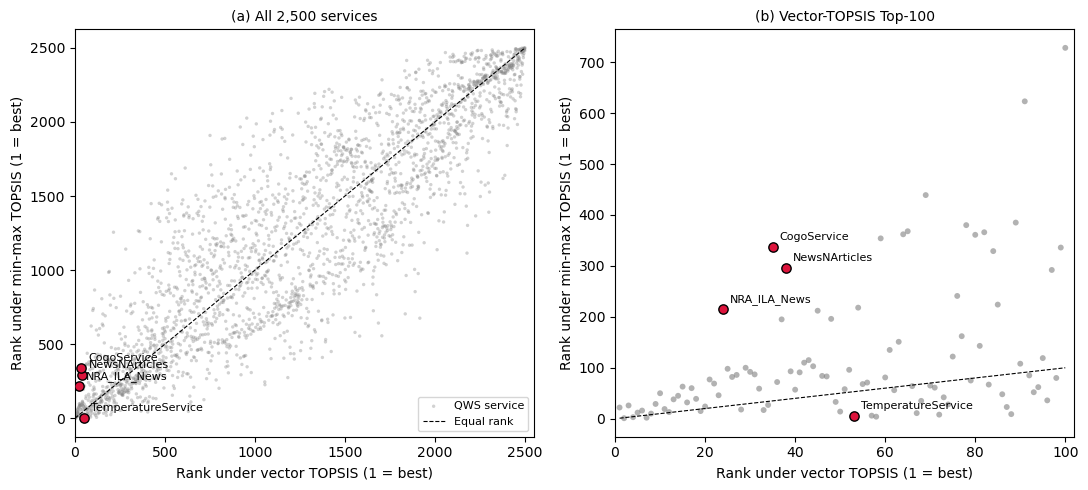

In [78]:
# ============================================================
# E4 - Step 2: rank-shift figure (vector vs min-max TOPSIS, real QWS data)
# ============================================================
rv, rm = real['TOPSIS [vector]'], real['TOPSIS [minmax]']
marks = {116: 'NewsNArticles', 2192: 'CogoService', 1416: 'NRA_ILA_News', 2328: 'TemperatureService'}
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, lim, title in [(axes[0], N, '(a) All 2,500 services'),
                       (axes[1], 100, '(b) Vector-TOPSIS Top-100')]:
    m = rv <= lim
    ax.scatter(rv[m], rm[m], s=6 if lim == N else 18, alpha=0.35 if lim == N else 0.6,
               color='grey', edgecolor='none', label='QWS service')
    ax.plot([1, lim], [1, lim], 'k--', lw=0.8, label='Equal rank')
    for i, name in marks.items():
        if rv[i] <= lim:
            ax.scatter(rv[i], rm[i], s=45, color='crimson', edgecolor='black', zorder=3)
            ax.annotate(name, (rv[i], rm[i]), xytext=(5, 5), textcoords='offset points', fontsize=8)
    ax.set_xlim(0, lim * 1.02)
    ax.set_xlabel('Rank under vector TOPSIS (1 = best)')
    ax.set_ylabel('Rank under min-max TOPSIS (1 = best)')
    ax.set_title(title, fontsize=10)
axes[0].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('fig_rank_shift.png', dpi=300); plt.savefig('fig_rank_shift.pdf')
plt.show()

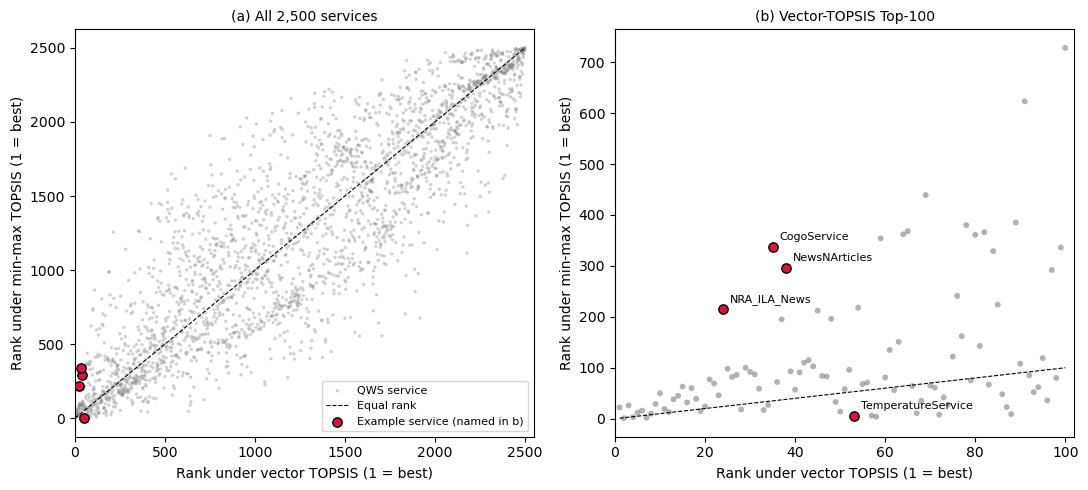

In [79]:
# ============================================================
# E4 - Step 2 (fixed): rank-shift figure, labels only in panel (b)
# ============================================================

rv, rm = real['TOPSIS [vector]'], real['TOPSIS [minmax]']
marks = {116: 'NewsNArticles', 2192: 'CogoService', 1416: 'NRA_ILA_News_Syndication', 2328: 'TemperatureService'}
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, lim, title in [(axes[0], N, '(a) All 2,500 services'),
                       (axes[1], 100, '(b) Vector-TOPSIS Top-100')]:
    m = rv <= lim
    ax.scatter(rv[m], rm[m], s=6 if lim == N else 18, alpha=0.35 if lim == N else 0.6,
               color='grey', edgecolor='none', label='QWS service')
    ax.plot([1, lim], [1, lim], 'k--', lw=0.8, label='Equal rank')
    ex_i = [i for i in marks if rv[i] <= lim]
    ax.scatter(rv[ex_i], rm[ex_i], s=45, color='crimson', edgecolor='black', zorder=3,
               label='Example service (named in b)')
    if lim != N:
        for i in ex_i:
            ax.annotate(marks[i], (rv[i], rm[i]), xytext=(5, 5), textcoords='offset points', fontsize=8)
    ax.set_xlim(0, lim * 1.02)
    ax.set_xlabel('Rank under vector TOPSIS (1 = best)')
    ax.set_ylabel('Rank under min-max TOPSIS (1 = best)')
    ax.set_title(title, fontsize=10)
axes[0].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('fig_rank_shift.png', dpi=300); plt.savefig('fig_rank_shift.pdf')
plt.show()

In [80]:
## E5 — Statistics (pre-declared, run once)
## Unit of inference: one benchmark seed (n = 20 per dataset).
## Datasets: E3 (seeds 200–219, mean over its 12 settings) = PRIMARY (independent test);
 ## E2 main (0–19) and E2 held-out (100–119) = supporting, same procedure.
##- Six contrasts x two metrics (A>B, A>C) = 12 tests per dataset:
##  C1 reciprocal -> vector TOPSIS     C2 vector -> min-max TOPSIS
##  C3 min-max TOPSIS -> top-2 VIKOR   C4 VIKOR k=1 -> k=2 (min-max)
##  C5 min-max TOPSIS -> + screening 25%   C6 Lu & Yuan exact -> min-max TOPSIS
##- Test: two-sided Wilcoxon signed-rank on non-zero paired differences.
##- Effect size: matched-pairs rank-biserial r (-1 to +1).
##- Uncertainty: bootstrap 95% CI of the mean difference (10,000 resamples of seeds).
##- Multiple testing: Holm correction within each dataset (family of 12), alpha = 0.05.
##- Grid results stay descriptive (no tests).

In [81]:
# ============================================================
# E5 - Step 1: paired statistics for the pre-declared contrasts
# ============================================================
from scipy.stats import wilcoxon

contrasts = [('TOPSIS [reciprocal]', 'TOPSIS [vector]'),      # C1 nonlinear vs linear normalisation
             ('TOPSIS [vector]',     'TOPSIS [minmax]'),      # C2 linear vs linear normalisation
             ('TOPSIS [minmax]',     'VIKOR k=2 [minmax]'),   # C3 aggregation
             ('VIKOR k=1 [minmax]',  'VIKOR k=2 [minmax]'),   # C4 regret depth
             ('TOPSIS [minmax]',     'TOPSIS + veto 25%'),    # C5 screening
             ('Lu & Yuan exact',     'TOPSIS [minmax]')]      # C6 published vs linear
mets = ['A above B %', 'A above C %']

def rank_biserial(d):
    d = d[d != 0]
    if len(d) == 0: return 0.0
    r = pd.Series(np.abs(d)).rank().values
    return (r[d > 0].sum() - r[d < 0].sum()) / r.sum()

def boot_ci(d, B=10000, seed=2026):
    rb = np.random.default_rng(seed)
    means = d[rb.integers(0, len(d), (B, len(d)))].mean(1)
    return np.percentile(means, [2.5, 97.5])

def holm(p):
    p = np.where(np.isnan(p), 1.0, np.asarray(p, float)); m = len(p)
    order, adj, run = np.argsort(p), np.empty(m), 0.0
    for i, idx in enumerate(order):
        run = max(run, min(1.0, (m - i) * p[idx])); adj[idx] = run
    return adj

def run_stats(per_seed, label):
    wide = {met: per_seed.pivot_table(index='Seed', columns='Method', values=met) for met in mets}
    rows = []
    for k, (a, b) in enumerate(contrasts, 1):
        for met in mets:
            d = (wide[met][b] - wide[met][a]).values          # positive = second method better
            nz = d[d != 0]
            p = wilcoxon(nz).pvalue if len(nz) > 0 else np.nan
            lo, hi = boot_ci(d)
            rows.append({'Data': label, 'C': f'C{k}', 'Contrast': f'{b}  minus  {a}', 'Metric': met,
                         'Mean diff': round(d.mean(), 1), '95% CI': f'[{lo:.1f}, {hi:.1f}]',
                         'n (non-zero)': len(nz), 'p': p, 'r_rb': round(rank_biserial(d), 2)})
    out = pd.DataFrame(rows)
    out['p (Holm)'] = holm(out['p'].values)
    out['p'] = out['p'].map(lambda v: 'n/a' if np.isnan(v) else f'{v:.4f}')
    out['p (Holm)'] = out['p (Holm)'].map(lambda v: f'{v:.4f}')
    return out

ly_m = ly_main.assign(Seed=range(20), Method='Lu & Yuan exact')
ly_h = ly_held.assign(Seed=range(100, 120), Method='Lu & Yuan exact')
datasets = {'E2 main (0-19)':      pd.concat([e2_main, ly_m]),
            'E2 held-out (100-119)': pd.concat([e2_held, ly_h]),
            'E3 (200-219)':        e3.groupby(['Method', 'Seed'])[mets].mean().reset_index()}

stats = pd.concat([run_stats(d, lab) for lab, d in datasets.items()])
stats.to_csv('e5_stats.csv', index=False)
for lab in datasets:
    print(f"\n===== {lab} =====")
    print(stats[stats.Data == lab].drop(columns='Data').to_string(index=False))


===== E2 main (0-19) =====
 C                                      Contrast      Metric  Mean diff       95% CI  n (non-zero)      p  r_rb p (Holm)
C1   TOPSIS [vector]  minus  TOPSIS [reciprocal] A above B %       58.9 [56.8, 61.2]            20 0.0000   1.0   0.0006
C1   TOPSIS [vector]  minus  TOPSIS [reciprocal] A above C %       39.6 [34.9, 44.5]            20 0.0001   1.0   0.0009
C2       TOPSIS [minmax]  minus  TOPSIS [vector] A above B %       14.8 [11.4, 18.0]            19 0.0001   1.0   0.0010
C2       TOPSIS [minmax]  minus  TOPSIS [vector] A above C %       13.0  [8.7, 17.5]            17 0.0003   1.0   0.0012
C3    VIKOR k=2 [minmax]  minus  TOPSIS [minmax] A above B %        6.8   [4.2, 9.6]            13 0.0002   1.0   0.0012
C3    VIKOR k=2 [minmax]  minus  TOPSIS [minmax] A above C %       -0.8 [-1.7, -0.1]             4 0.1250  -1.0   0.3750
C4 VIKOR k=2 [minmax]  minus  VIKOR k=1 [minmax] A above B %        0.6   [0.0, 1.6]             3 0.2500   1.0   0.5000
C4 V

In [82]:
## R1 — Weight robustness (pre-declared, descriptive only, no tests)
##- alpha ∈ {0 (BWM only), 0.5 (main), 1 (CRITIC only)}; E2 main generator, seeds 0–19.
##- Rows: TOPSIS reciprocal / vector / min-max, top-2 VIKOR (min-max).
##- Question: does reciprocal stay far below the linear normalisations at every alpha?

In [83]:
# ============================================================
# Robustness R1: does the normalisation effect survive other weightings? (alpha = 0, 0.5, 1)
# ============================================================
def alpha_rows(seed, alpha):
    Xa, types, ix = plant_e2(seed)
    w_, Xt_, _ = weights_from_raw(Xa, alpha)
    ranks = {f'TOPSIS [{k}]': rank_low(-topsis(normalise(Xt_, k), w_)) for k in ['reciprocal', 'vector', 'minmax']}
    ranks['VIKOR k=2 [minmax]'] = rank_low(vikor_topk(normalise(Xt_, 'minmax'), w_, 2))
    out = []
    for name, r in ranks.items():
        r = r[ix]; A, B, C, M, E = [r[types == t] for t in 'ABCME']
        out.append({'alpha': alpha, 'Method': name,
                    'A above B %': 100 * np.mean(A[:, None] < B[None, :]),
                    'A above C %': 100 * np.mean(A[:, None] < C[None, :]),
                    'E above M %': 100 * np.mean(E[:, None] < M[None, :])})
    return out

alpha_df = pd.DataFrame([row for a in [0.0, 0.5, 1.0] for s in range(20) for row in alpha_rows(s, a)])
alpha_df.to_csv('r1_alpha_per_seed.csv', index=False)
alpha_tab = alpha_df.groupby(['alpha', 'Method'], sort=False)[['A above B %', 'A above C %', 'E above M %']].mean().round(1)
print("Check: alpha = 0.5 rows equal E2 Step 2 (e.g. TOPSIS [minmax] 84.8 / 100.0)")
print(alpha_tab)

Check: alpha = 0.5 rows equal E2 Step 2 (e.g. TOPSIS [minmax] 84.8 / 100.0)
                           A above B %  A above C %  E above M %
alpha Method                                                    
0.0   TOPSIS [reciprocal]         19.6         43.7        100.0
      TOPSIS [vector]             56.2         75.4        100.0
      TOPSIS [minmax]             33.5         32.0         99.0
      VIKOR k=2 [minmax]          50.9         60.8        100.0
0.5   TOPSIS [reciprocal]         11.1         47.4        100.0
      TOPSIS [vector]             70.1         87.0        100.0
      TOPSIS [minmax]             84.8        100.0        100.0
      VIKOR k=2 [minmax]          91.7         99.2        100.0
1.0   TOPSIS [reciprocal]         23.2         57.1        100.0
      TOPSIS [vector]             60.3         72.5        100.0
      TOPSIS [minmax]             90.4        100.0        100.0
      VIKOR k=2 [minmax]          97.9        100.0        100.0


In [84]:
# ============================================================
# Check: Latency shortfall under reciprocal vs linear (log and raw scales)
# ============================================================
lat = criteria.index('Latency')
for scale, x in [('log', Xt[:, lat]), ('raw', X[:, lat])]:
    rec = 1.0 / x
    sf_rec = (rec.max() - rec) / (rec.max() - rec.min())      # reciprocal shortfall (0 = best, 1 = worst)
    sf_lin = (x - x.min()) / (x.max() - x.min())              # linear shortfall
    for name, sf in [('reciprocal', sf_rec), ('linear', sf_lin)]:
        print(f"{scale:3s} {name:10s} median = {np.median(sf):.3f}   "
              f"5th-95th = {np.percentile(sf, 5):.3f} - {np.percentile(sf, 95):.3f}")

log reciprocal median = 0.938   5th-95th = 0.697 - 0.982
log linear     median = 0.287   5th-95th = 0.058 - 0.594
raw reciprocal median = 0.979   5th-95th = 0.750 - 0.998
raw linear     median = 0.003   5th-95th = 0.000 - 0.037


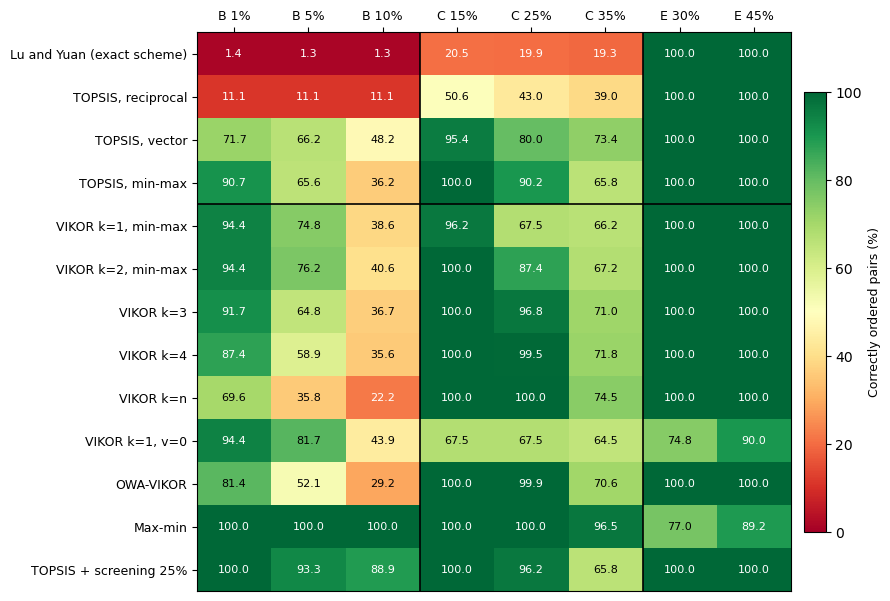

In [85]:
# ============================================================
# Figure: new severity-grid heatmap (fig_grid_heatmap.png / .pdf)
# ============================================================
grid_tab = grid_e2_table if 'grid_e2_table' in globals() else pd.read_csv('e2_grid_table.csv', index_col=0)
assert 'ly_grid' in globals(), "Run the E2 Step 6 (Lu & Yuan) cell first, so ly_grid exists"

rows = [('Lu and Yuan (exact scheme)', None),
        ('TOPSIS, reciprocal',   'TOPSIS [reciprocal]'),
        ('TOPSIS, vector',       'TOPSIS [vector]'),
        ('TOPSIS, min-max',      'TOPSIS [minmax]'),
        ('VIKOR k=1, min-max',   'VIKOR k=1 [minmax]'),
        ('VIKOR k=2, min-max',   'VIKOR k=2 [minmax]'),
        ('VIKOR k=3',            'Top-k VIKOR k=3'),
        ('VIKOR k=4',            'Top-k VIKOR k=4'),
        ('VIKOR k=n',            'Top-k VIKOR k=all'),
        ('VIKOR k=1, v=0',       'VIKOR k=1, v=0.0'),
        ('OWA-VIKOR',            'OWA-VIKOR'),
        ('Max-min',              'Max-min'),
        ('TOPSIS + screening 25%', 'TOPSIS + veto 25%')]
cols = ['B1', 'B5', 'B10', 'C15', 'C25', 'C35', 'E30', 'E45']
col_labels = ['B 1%', 'B 5%', 'B 10%', 'C 15%', 'C 25%', 'C 35%', 'E 30%', 'E 45%']
M = np.array([[ly_grid[c] for c in cols] if key is None else grid_tab.loc[key, cols].values
              for _, key in rows], dtype=float)

fig, ax = plt.subplots(figsize=(9, 6.2))
im = ax.imshow(M, cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f'{M[i, j]:.1f}', ha='center', va='center', fontsize=8,
                color='black' if 25 < M[i, j] < 85 else 'white')
ax.set_xticks(range(len(cols))); ax.set_xticklabels(col_labels, fontsize=9)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows], fontsize=9)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
for x in [2.5, 5.5]:
    ax.axvline(x, color='black', lw=1.2)
ax.axhline(3.5, color='black', lw=1.2)          # normalisation rows above, aggregation rows below
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.set_label('Correctly ordered pairs (%)', fontsize=9)
plt.tight_layout()
plt.savefig('fig_grid_heatmap.png', dpi=300); plt.savefig('fig_grid_heatmap.pdf')
plt.show()

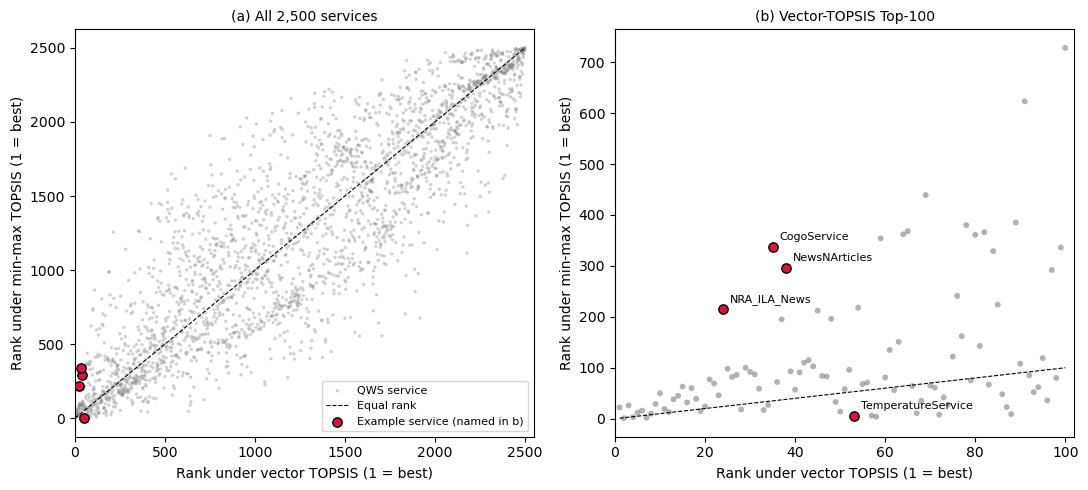

In [86]:
# ============================================================
# Figure: rank shift, vector vs min-max TOPSIS (fig_rank_shift.png / .pdf)
# ============================================================
rv, rm = real['TOPSIS [vector]'], real['TOPSIS [minmax]']
marks = {116: 'NewsNArticles', 2192: 'CogoService', 1416: 'NRA_ILA_News', 2328: 'TemperatureService'}
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, lim, title in [(axes[0], N, '(a) All 2,500 services'),
                       (axes[1], 100, '(b) Vector-TOPSIS Top-100')]:
    m = rv <= lim
    ax.scatter(rv[m], rm[m], s=6 if lim == N else 18, alpha=0.35 if lim == N else 0.6,
               color='grey', edgecolor='none', label='QWS service')
    ax.plot([1, lim], [1, lim], 'k--', lw=0.8, label='Equal rank')
    ex_i = [i for i in marks if rv[i] <= lim]
    ax.scatter(rv[ex_i], rm[ex_i], s=45, color='crimson', edgecolor='black', zorder=3,
               label='Example service (named in b)')
    if lim != N:
        for i in ex_i:
            ax.annotate(marks[i], (rv[i], rm[i]), xytext=(5, 5), textcoords='offset points', fontsize=8)
    ax.set_xlim(0, lim * 1.02)
    ax.set_xlabel('Rank under vector TOPSIS (1 = best)')
    ax.set_ylabel('Rank under min-max TOPSIS (1 = best)')
    ax.set_title(title, fontsize=10)
axes[0].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('fig_rank_shift.png', dpi=300); plt.savefig('fig_rank_shift.pdf')
plt.show()

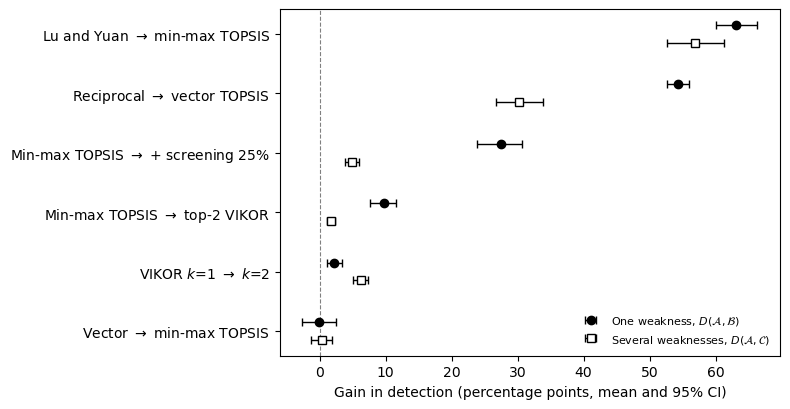

In [87]:
# ============================================================
# Figure: effect sizes with 95% CIs (independent benchmark) -> fig_effects.png / .pdf
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
st = pd.read_csv('e5_stats.csv')
st = st[st['Data'].str.startswith('E3')].copy()
ci = st['95% CI'].str.strip('[]').str.split(',', expand=True).astype(float)
st['lo'], st['hi'] = ci[0], ci[1]

labels = {'C6': 'Lu and Yuan $\\rightarrow$ min-max TOPSIS',
          'C1': 'Reciprocal $\\rightarrow$ vector TOPSIS',
          'C5': 'Min-max TOPSIS $\\rightarrow$ + screening 25%',
          'C3': 'Min-max TOPSIS $\\rightarrow$ top-2 VIKOR',
          'C4': 'VIKOR $k$=1 $\\rightarrow$ $k$=2',
          'C2': 'Vector $\\rightarrow$ min-max TOPSIS'}
order = list(labels)                      # sorted by single-weakness effect, largest first
fig, ax = plt.subplots(figsize=(8, 4.2))
for met, off, mk, name in [('A above B %', -0.15, 'o', 'One weakness, $D(\\mathcal{A},\\mathcal{B})$'),
                           ('A above C %',  0.15, 's', 'Several weaknesses, $D(\\mathcal{A},\\mathcal{C})$')]:
    d = st[st['Metric'] == met].set_index('C').loc[order]
    y = np.arange(len(order)) + off
    ax.errorbar(d['Mean diff'], y, xerr=[d['Mean diff'] - d['lo'], d['hi'] - d['Mean diff']],
                fmt=mk, color='black', mfc='black' if mk == 'o' else 'white',
                ms=6, capsize=3, lw=1, label=name)
ax.axvline(0, color='grey', ls='--', lw=0.8)
ax.set_yticks(range(len(order))); ax.set_yticklabels([labels[c] for c in order])
ax.invert_yaxis()
ax.set_xlabel('Gain in detection (percentage points, mean and 95% CI)')
ax.legend(loc='lower right', fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig('fig_effects.png', dpi=300); plt.savefig('fig_effects.pdf')
plt.show()

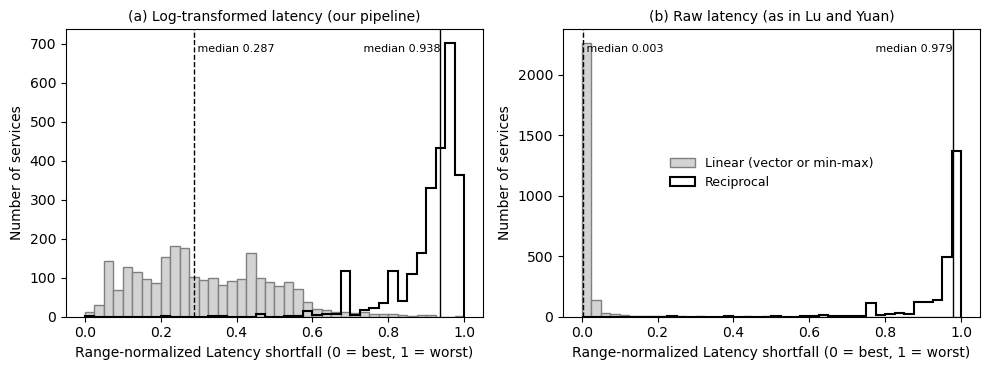

In [88]:
# ============================================================
# Figure: Latency shortfall under reciprocal vs linear normalisation -> fig_latency.png / .pdf
# ============================================================
lat = criteria.index('Latency')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
bins = np.linspace(0, 1, 41)
for ax, (title, x) in zip(axes, [('(a) Log-transformed latency (our pipeline)', Xt[:, lat]),
                                 ('(b) Raw latency (as in Lu and Yuan)', X[:, lat])]):
    rec = 1.0 / x
    sf_rec = (rec.max() - rec) / (rec.max() - rec.min())     # 0 = best, 1 = worst
    sf_lin = (x - x.min()) / (x.max() - x.min())
    ax.hist(sf_lin, bins=bins, color='lightgrey', edgecolor='grey', label='Linear (vector or min-max)')
    ax.hist(sf_rec, bins=bins, histtype='step', color='black', lw=1.5, label='Reciprocal')
    for sf, ls in [(sf_lin, '--'), (sf_rec, '-')]:
        ax.axvline(np.median(sf), color='black', ls=ls, lw=1)
        ax.text(np.median(sf), ax.get_ylim()[1] * 0.92, f' median {np.median(sf):.3f}',
                fontsize=8, ha='left' if np.median(sf) < 0.6 else 'right')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Range-normalized Latency shortfall (0 = best, 1 = worst)')
for a in axes: a.set_ylabel('Number of services')
axes[1].legend(loc='center', fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig('fig_latency.png', dpi=300); plt.savefig('fig_latency.pdf')
plt.show()

In [89]:
## R2 — Equal weights (pre-declared, run once, descriptive only)
##- Weights: 1/9 for every criterion; same log rule, same generator, seeds 0–19 (main benchmark).
##- Rows: TOPSIS reciprocal / vector / min-max, top-2 VIKOR (min-max).
##- Question: is reciprocal still the weakest for single weaknesses without the expert's weights?

In [90]:
# ============================================================
# R2 - Equal weights (1/9) on the main benchmark (pre-declared, run once)
# ============================================================
def eq_rows(seed):
    Xa, types, ix = plant_e2(seed)
    _, Xt_, _ = weights_from_raw(Xa)              # same log rule; the weights below replace w_final
    w_eq = np.full(n, 1.0 / n)
    ranks = {f'TOPSIS [{k}]': rank_low(-topsis(normalise(Xt_, k), w_eq))
             for k in ['reciprocal', 'vector', 'minmax']}
    ranks['VIKOR k=2 [minmax]'] = rank_low(vikor_topk(normalise(Xt_, 'minmax'), w_eq, 2))
    out = []
    for name, r in ranks.items():
        r = r[ix]; A, B, C, M, E = [r[types == t] for t in 'ABCME']
        out.append({'Method': name, 'Seed': seed,
                    'A above B %': 100 * np.mean(A[:, None] < B[None, :]),
                    'A above C %': 100 * np.mean(A[:, None] < C[None, :]),
                    'E above M %': 100 * np.mean(E[:, None] < M[None, :])})
    return out

eq_df = pd.DataFrame([row for s in range(20) for row in eq_rows(s)])
eq_df.to_csv('r2_equal_weights_per_seed.csv', index=False)
eq_tab = (eq_df.groupby('Method', sort=False)[['A above B %', 'A above C %', 'E above M %']]
          .agg(['mean', 'std']).round(1))
eq_tab.to_csv('r2_equal_weights_table.csv')
print("Equal weights (1/9), main benchmark, seeds 0-19:")
print(eq_tab)

Equal weights (1/9), main benchmark, seeds 0-19:
                    A above B %      A above C %       E above M %     
                           mean  std        mean   std        mean  std
Method                                                                 
TOPSIS [reciprocal]        11.4  0.7        44.6  10.1       100.0  0.0
TOPSIS [vector]            72.7  7.3        83.2  10.8       100.0  0.0
TOPSIS [minmax]            99.4  2.5       100.0   0.0       100.0  0.0
VIKOR k=2 [minmax]         99.4  2.5       100.0   0.0       100.0  0.0


In [91]:
# ============================================================
# Step 3 - weight-consistent split of D(A,B) + A-level sensitivity
# Appended to the notebook pipeline; reuses its functions unchanged.
# ============================================================
import numpy as np, pandas as pd

def make_t(level):
    """Same as notebook make(), but also returns the jittered level (1 = best)."""
    lv = np.clip(level + rng.uniform(-0.03, 0.03, n), 0.001, 0.999)
    vals = np.array([np.quantile(X[:, j], 1 - lv[j] if j in cost_idx else lv[j]) for j in range(n)])
    return vals, lv

def plant_t(seed, b, m, c, e, a=0.80):
    """Identical draw order to plant_e2 / plant_e3; also returns the planted levels."""
    global rng
    rng = np.random.default_rng(seed)
    planted, levels, types = [], [], []
    def add(lv, t):
        v, l = make_t(lv); planted.append(v); levels.append(l); types.append(t)
    for _ in range(10): add(np.full(n, a), 'A')
    for j in range(n):
        lv = np.full(n, 0.90); lv[j] = b; add(lv, 'B')
    for _ in range(10):
        lv = np.full(n, 0.90); lv[rng.choice(n, m, replace=False)] = c; add(lv, 'C')
    for _ in range(10): add(np.full(n, 0.50), 'M')
    for _ in range(10):
        lv = np.full(n, 0.95); lv[rng.choice(n)] = e; add(lv, 'E')
    types = np.array(types)
    return np.vstack([X, np.array(planted)]), types, np.arange(N, N + len(types)), np.array(levels)

KEY = ['Lu & Yuan exact', 'TOPSIS [reciprocal]', 'TOPSIS [vector]', 'TOPSIS [minmax]',
       'VIKOR k=1 [reciprocal]', 'VIKOR k=2 [reciprocal]', 'VIKOR k=1 [minmax]',
       'VIKOR k=2 [minmax]', 'Max-min', 'TOPSIS + veto 25%']

def split_rows(Xa, types, ix, L, label, seed, extra=None):
    ranks = method_ranks_e2(Xa)
    ranks['Lu & Yuan exact'] = rank_low(-ly2018(Xa)[0])
    w_, _, _ = weights_from_raw(Xa)                     # the weights every method used
    VA = L[types == 'A'] @ w_                           # weighted sum of percentile levels
    VB = L[types == 'B'] @ w_
    consistent = VA[:, None] > VB[None, :]              # 10 x 9: additive reference also says A > B
    crit = np.tile(np.arange(n), (10, 1))               # weak criterion of each B column
    out = []
    for name in KEY:
        r = ranks[name][ix]
        hit = r[types == 'A'][:, None] < r[types == 'B'][None, :]
        row = {'Data': label, 'Seed': seed, 'Method': name,
               'D(A,B) all': 100 * hit.mean(),
               'D(A,B) weight-consistent': 100 * hit[consistent].mean() if consistent.any() else np.nan,
               'D(A,B) normative-only': 100 * hit[~consistent].mean() if (~consistent).any() else np.nan,
               'Share consistent %': 100 * consistent.mean()}
        if extra: row.update(extra)
        out.append(row)
    pc = pd.DataFrame({'crit': crit.ravel(), 'cons': consistent.ravel()})
    return out, pc.groupby('crit')['cons'].mean()

# ---------- (1) main, held-out, independent ----------
rows, cons_by_crit = [], []
for s in range(20):
    Xa, t, ix, L = plant_t(s, 0.02, 3, 0.20, 0.40)
    r, pc = split_rows(Xa, t, ix, L, 'Main (0-19)', s); rows += r; cons_by_crit.append(pc.rename(('Main', s)))
for s in range(100, 120):
    Xa, t, ix, L = plant_t(s, 0.02, 3, 0.20, 0.40)
    r, _ = split_rows(Xa, t, ix, L, 'Held-out (100-119)', s); rows += r
for b in [0.03, 0.07]:
    for m in [2, 4, 5]:
        for c in [0.18, 0.30]:
            for s in range(200, 220):
                Xa, t, ix, L = plant_t(s, b, m, c, 0.50)
                r, pc = split_rows(Xa, t, ix, L, 'Independent (200-219)', s, {'b': b, 'm': m, 'c': c}); rows += r
                if m == 2 and c == 0.18: cons_by_crit.append(pc.rename((f'Indep b={b}', s)))
split = pd.DataFrame(rows)
split.to_csv('step3_split_per_seed.csv', index=False)

# reproduction check against the published per-seed results
chk = split[split.Data == 'Main (0-19)'].groupby('Method')['D(A,B) all'].mean().round(1)
pub = pd.read_csv('e2_main_per_seed.csv').groupby('Method')['A above B %'].mean().round(1)
print("Reproduction check (main D(A,B), must match Table 3):")
for k in ['TOPSIS [reciprocal]', 'TOPSIS [vector]', 'TOPSIS [minmax]', 'VIKOR k=2 [minmax]']:
    print(f"  {k:22s} new {chk[k]:5.1f}   published {pub[k]:5.1f}")

seed_level = split.groupby(['Data', 'Method', 'Seed'])[['D(A,B) all', 'D(A,B) weight-consistent',
                                                        'D(A,B) normative-only', 'Share consistent %']].mean()
summary = seed_level.groupby(['Data', 'Method']).mean().round(1)
summary.to_csv('step3_split_summary.csv')
pd.set_option('display.width', 200)
for d in ['Main (0-19)', 'Held-out (100-119)', 'Independent (200-219)']:
    print(f"\n=== {d} ===")
    print(summary.loc[d].loc[KEY])

cbc = pd.concat(cons_by_crit, axis=1)
main_cols = [c for c in cbc.columns if c[0] == 'Main']
tab_crit = pd.DataFrame({'Criterion': criteria,
                         'w_j (final)': np.round(w_final, 3),
                         'Consistent share, main (%)': (100 * cbc[main_cols].mean(1)).round(1).values})
for b in [0.03, 0.07]:
    cols = [c for c in cbc.columns if c[0] == f'Indep b={b}']
    tab_crit[f'Consistent share, b={b} (%)'] = (100 * cbc[cols].mean(1)).round(1).values
tab_crit['Threshold 0.10/(0.90-b), main'] = round(0.10 / 0.88, 3)
tab_crit.to_csv('step3_consistency_by_criterion.csv', index=False)
print("\nShare of (A,B) pairs where the weighted-sum reference also ranks A above B, by weak criterion:")
print(tab_crit.to_string(index=False))

# per-criterion TOPSIS detection with consistency flag (main) -> new column for Table 4
# ---------- (2) A-level sensitivity, main benchmark ----------
sens = []
for a in [0.75, 0.80, 0.85]:
    for s in range(20):
        Xa, t, ix, L = plant_t(s, 0.02, 3, 0.20, 0.40, a=a)
        ranks = method_ranks_e2(Xa); ranks['Lu & Yuan exact'] = rank_low(-ly2018(Xa)[0])
        for name in KEY:
            r = ranks[name][ix]; A, B, C = [r[t == k] for k in 'ABC']
            sens.append({'A level': a, 'Seed': s, 'Method': name,
                         'D(A,B)': 100 * np.mean(A[:, None] < B[None, :]),
                         'D(A,C)': 100 * np.mean(A[:, None] < C[None, :])})
sens = pd.DataFrame(sens); sens.to_csv('step3_alevel_per_seed.csv', index=False)
sens_tab = sens.pivot_table(index='Method', columns='A level', values=['D(A,B)', 'D(A,C)']).loc[KEY].round(1)
sens_tab.to_csv('step3_alevel_table.csv')
print("\nA-level sensitivity (main benchmark, seeds 0-19):")
print(sens_tab)

Reproduction check (main D(A,B), must match Table 3):
  TOPSIS [reciprocal]    new  11.1   published  11.1
  TOPSIS [vector]        new  70.1   published  70.1
  TOPSIS [minmax]        new  84.8   published  84.8
  VIKOR k=2 [minmax]     new  91.7   published  91.7

=== Main (0-19) ===
                        D(A,B) all  D(A,B) weight-consistent  D(A,B) normative-only  Share consistent %
Method                                                                                                 
Lu & Yuan exact                1.4                       0.0                    2.0                28.7
TOPSIS [reciprocal]           11.1                       0.7                   15.4                28.7
TOPSIS [vector]               70.1                      98.8                   58.4                28.7
TOPSIS [minmax]               84.8                      99.8                   78.5                28.7
VIKOR k=1 [reciprocal]        61.7                      94.8                   48.6      

In [92]:
# ============================================================
# Step 4 - log-transform ablation: {reciprocal, vector, min-max} x {log rule on, off}
# Weights are identical in every row (blended weights from the log-transformed data, Eq. blend),
# so only the log step and the normalization change.  Reuses the notebook functions unchanged.
# ============================================================
import numpy as np, pandas as pd

def ablation_ranks(Xa):
    w_, Xt_, _ = weights_from_raw(Xa)                      # same weights for all rows
    out = {}
    for logrule, M in [('log', Xt_), ('raw', Xa.astype(float))]:
        for kind in ['reciprocal', 'vector', 'minmax']:
            out[f'TOPSIS [{kind}] {logrule}'] = rank_low(-topsis(normalise(M, kind), w_))
        out[f'VIKOR k=2 [minmax] {logrule}'] = rank_low(vikor_topk(normalise(M, 'minmax'), w_, 2))
    return out

def score(Xa, types, ix, label, seed, extra=None):
    rows = []
    for name, r_all in ablation_ranks(Xa).items():
        r = r_all[ix]; A, B, C, M, E = [r[types == t] for t in 'ABCME']
        row = {'Data': label, 'Seed': seed, 'Method': name,
               'D(A,B)': 100 * np.mean(A[:, None] < B[None, :]),
               'D(A,C)': 100 * np.mean(A[:, None] < C[None, :]),
               'D(E,M)': 100 * np.mean(E[:, None] < M[None, :]),
               'D(E,A)': 100 * np.mean(E[:, None] < A[None, :])}
        if extra: row.update(extra)
        rows.append(row)
    return rows

rows = []
for s in range(20):
    Xa, t, ix = plant_e2(s); rows += score(Xa, t, ix, 'Main (0-19)', s)
for s in range(100, 120):
    Xa, t, ix = plant_e2(s); rows += score(Xa, t, ix, 'Held-out (100-119)', s)
for b in [0.03, 0.07]:
    for m in [2, 4, 5]:
        for c in [0.18, 0.30]:
            for s in range(200, 220):
                Xa, t, ix = plant_e3(s, b, m, c)
                rows += score(Xa, t, ix, 'Independent (200-219)', s, {'b': b, 'm': m, 'c': c})
abl = pd.DataFrame(rows); abl.to_csv('step4_ablation_per_seed.csv', index=False)

seed_lvl = abl.groupby(['Data', 'Method', 'Seed'])[['D(A,B)', 'D(A,C)', 'D(E,M)', 'D(E,A)']].mean()
summ = seed_lvl.groupby(['Data', 'Method']).mean().round(1)
order = [f'{m} {l}' for l in ['log', 'raw'] for m in ['TOPSIS [reciprocal]', 'TOPSIS [vector]', 'TOPSIS [minmax]', 'VIKOR k=2 [minmax]']]
summ.to_csv('step4_ablation_summary.csv')
pd.set_option('display.width', 200)
for d in ['Main (0-19)', 'Held-out (100-119)', 'Independent (200-219)']:
    print(f'\n=== {d} ==='); print(summ.loc[d].loc[order])

# reproduction check: log rows must equal the published Table 3 values
pub = pd.read_csv('e2_main_per_seed.csv').groupby('Method')['A above B %'].mean().round(1)
print('\nReproduction check (main, log rule on):')
for k in ['TOPSIS [reciprocal]', 'TOPSIS [vector]', 'TOPSIS [minmax]', 'VIKOR k=2 [minmax]']:
    print(f'  {k:22s} new {summ.loc[("Main (0-19)", k + " log"), "D(A,B)"]:5.1f}   published {pub[k]:5.1f}')

# decomposition of the reciprocal -> linear gain (paired over seeds, bootstrap 95% CI)
rb = np.random.default_rng(2026)
def ci(d):
    m = d[rb.integers(0, len(d), (10000, len(d)))].mean(1); return np.percentile(m, [2.5, 97.5])
contr = [('TOPSIS [reciprocal] raw', 'TOPSIS [vector] raw', 'Linear vs reciprocal, no log'),
         ('TOPSIS [reciprocal] log', 'TOPSIS [vector] log', 'Linear vs reciprocal, with log (C1)'),
         ('TOPSIS [reciprocal] raw', 'TOPSIS [reciprocal] log', 'Log effect, reciprocal'),
         ('TOPSIS [vector] raw', 'TOPSIS [vector] log', 'Log effect, vector'),
         ('TOPSIS [minmax] raw', 'TOPSIS [minmax] log', 'Log effect, min-max'),
         ('TOPSIS [reciprocal] raw', 'TOPSIS [vector] log', 'Total: reciprocal raw -> vector log')]
crow = []
for d in ['Main (0-19)', 'Independent (200-219)']:
    for met in ['D(A,B)', 'D(A,C)']:
        w = seed_lvl.loc[d][met].unstack('Method')
        for a, b, lab in contr:
            x = (w[b] - w[a]).values; lo, hi = ci(x)
            crow.append({'Data': d, 'Metric': met, 'Contrast': lab, 'Mean diff': round(x.mean(), 1),
                         '95% CI': f'[{lo:.1f}, {hi:.1f}]', 'Seeds better/worse': f'{(x > 0).sum()}/{(x < 0).sum()}'})
cdf = pd.DataFrame(crow); cdf.to_csv('step4_contrasts.csv', index=False)
print('\nContrasts (second minus first, percentage points):'); print(cdf.to_string(index=False))


=== Main (0-19) ===
                         D(A,B)  D(A,C)  D(E,M)  D(E,A)
Method                                                 
TOPSIS [reciprocal] log    11.1    47.4   100.0    93.9
TOPSIS [vector] log        70.1    87.0   100.0    67.6
TOPSIS [minmax] log        84.8   100.0   100.0    98.4
VIKOR k=2 [minmax] log     91.7    99.2   100.0    98.2
TOPSIS [reciprocal] raw     0.0    20.6   100.0   100.0
TOPSIS [vector] raw        41.2    47.5   100.0    77.8
TOPSIS [minmax] raw        47.3    65.8   100.0    90.0
VIKOR k=2 [minmax] raw     52.5    63.8   100.0    90.0

=== Held-out (100-119) ===
                         D(A,B)  D(A,C)  D(E,M)  D(E,A)
Method                                                 
TOPSIS [reciprocal] log    11.1    49.5   100.0    93.4
TOPSIS [vector] log        72.7    89.2   100.0    65.4
TOPSIS [minmax] log        79.7    99.9   100.0    98.0
VIKOR k=2 [minmax] log     88.4    99.9   100.0    96.2
TOPSIS [reciprocal] raw     0.0    22.4   100.0   100.0

In [93]:
# ============================================================
# Step 5 - decision-set size: does the result hold when a user compares 10-50 services?
# Each matrix = (Ns - 2) real QWS services drawn without replacement + 1 balanced service (A)
# + 1 test service (B_j, C or E), planted from the GLOBAL quantiles exactly as in the benchmark.
# Primary: weights (w_final) and log rule fixed from the full data; normalization, ideals,
#          ranges and VIKOR scaling computed on the small matrix only.
# Secondary: CRITIC part of the weights recomputed inside each small matrix.
# Screening thresholds: 25% quantiles of the full real data (a fixed minimum requirement).
# A "detection" = A scores strictly better than the test service (ties count as failures),
# which is exactly rank(A) < rank(test) under the min-rank rule used in the benchmark.
# Reuses notebook objects: X, n, N, criteria, cost_idx, transform_idx, w_final, w_bwm,
# normalise, topsis, vikor_topk, rank_low, method_ranks_e2, ly2018, plant_e2.
# ============================================================
import numpy as np, pandas as pd

cost = np.zeros(n, bool); cost[cost_idx] = True
logm = np.zeros(n, bool); logm[transform_idx] = True
EPS = 1e-12

def tlog(Xs):                                   # Xs: (M, k, n) raw values
    Y = Xs.copy(); Y[..., logm] = np.log1p(np.clip(Y[..., logm], 0, None)); return Y

def norm_b(Y, kind):                            # benefit-oriented normalized values, batched
    if kind == 'minmax':
        mn, mx = Y.min(1, keepdims=True), Y.max(1, keepdims=True)
        R = (Y - mn) / np.where(mx - mn > 0, mx - mn, 1.0)
        R[..., cost] = 1 - R[..., cost]
        return R
    if kind == 'vector':
        R = Y / np.sqrt((Y ** 2).sum(1, keepdims=True)); R[..., cost] *= -1; return R
    if kind == 'reciprocal':
        Z = Y.copy(); Z[..., cost] = 1.0 / Z[..., cost]
        return Z / np.sqrt((Z ** 2).sum(1, keepdims=True))

def topsis_b(R, w):
    V = w[:, None, :] * R if w.ndim == 2 else w * R
    Dp = np.sqrt(((V - V.max(1, keepdims=True)) ** 2).sum(2))
    Dm = np.sqrt(((V - V.min(1, keepdims=True)) ** 2).sum(2))
    return np.where(Dp + Dm > 0, Dm / np.where(Dp + Dm > 0, Dp + Dm, 1), 0.5)   # higher = better

def nrm_b(v):
    mn, mx = v.min(1, keepdims=True), v.max(1, keepdims=True)
    return (v - mn) / (mx - mn + EPS)

def vikor_b(R, w, k, v=0.5):
    W = w[:, None, :] if w.ndim == 2 else w
    rng_ = R.max(1, keepdims=True) - R.min(1, keepdims=True)
    gap = W * (R.max(1, keepdims=True) - R) / np.where(rng_ > 0, rng_, 1.0)
    S = gap.sum(2); g = -np.sort(-gap, axis=2)
    return v * nrm_b(S) + (1 - v) * nrm_b(g[..., :k].mean(2))                 # lower = better

def critic_b(Y):                                 # CRITIC weights inside each small matrix
    mn, mx = Y.min(1, keepdims=True), Y.max(1, keepdims=True)
    Z = (Y - mn) / np.where(mx - mn > 0, mx - mn, 1.0)
    Zb = Z.copy(); Zb[..., cost] = 1 - Zb[..., cost]
    sd = Z.std(1)
    Zc = Zb - Zb.mean(1, keepdims=True); s = np.sqrt((Zc ** 2).sum(1))
    C = np.einsum('mki,mkj->mij', Zc, Zc) / np.where(s[:, :, None] * s[:, None, :] > 0,
                                                     s[:, :, None] * s[:, None, :], 1.0)
    C = np.where((s[:, :, None] > 0) & (s[:, None, :] > 0), C, 0.0)
    Cj = sd * (1 - C).sum(2)
    wc = Cj / np.where(Cj.sum(1, keepdims=True) > 0, Cj.sum(1, keepdims=True), 1.0)
    w = 0.5 * wc + 0.5 * w_bwm
    return w / w.sum(1, keepdims=True)

def ly_b(Xs):                                    # Lu & Yuan exact scheme on raw values, batched
    Z = Xs.astype(float).copy(); Z[..., cost] = 1.0 / Z[..., cost]
    NS = Z / np.sqrt((Z ** 2).sum(1, keepdims=True))
    P = NS / NS.sum(1, keepdims=True)
    e = -(P * np.log(np.where(P > 0, P, 1))).sum(1) / np.log(Xs.shape[1])
    d = 1 - e; ew = d / d.sum(1, keepdims=True)
    WS = ew[:, None, :] * NS
    Dp = np.sqrt(((WS - WS.max(1, keepdims=True)) ** 2).sum(2))
    Dm = np.sqrt(((WS - WS.min(1, keepdims=True)) ** 2).sum(2))
    return Dm / (Dp + Dm)

Xt_full = tlog(X[None])[0]
thr = np.where(cost, np.quantile(Xt_full, 0.75, axis=0), np.quantile(Xt_full, 0.25, axis=0))  # 25% screening

def better_A(scores, higher=True):              # A is row -2, test service is row -1
    a, t = scores[:, -2], scores[:, -1]
    return (a > t) if higher else (a < t)

def all_methods(Xs, w):
    Y = tlog(Xs); out = {}
    for kind in ['reciprocal', 'vector', 'minmax']:
        out[f'TOPSIS [{kind}]'] = better_A(topsis_b(norm_b(Y, kind), w))
    Rmm = norm_b(Y, 'minmax'); Rrec = norm_b(Y, 'reciprocal')
    out['VIKOR k=1 [minmax]'] = better_A(vikor_b(Rmm, w, 1), higher=False)
    out['VIKOR k=2 [minmax]'] = better_A(vikor_b(Rmm, w, 2), higher=False)
    out['VIKOR k=2 [reciprocal]'] = better_A(vikor_b(Rrec, w, 2), higher=False)
    out['Max-min'] = better_A(Rmm.min(2))
    veto = np.where(cost, Y > thr, Y < thr).any(2)
    T = topsis_b(Rmm, w)
    out['TOPSIS + veto 25%'] = (veto[:, -2] < veto[:, -1]) | ((veto[:, -2] == veto[:, -1]) & (T[:, -2] > T[:, -1]))
    out['Lu & Yuan exact'] = better_A(ly_b(Xs))
    return out

# ---------- sanity check: batched code == notebook code on the full data (one matrix of 2,549) ----------
Xa, types, ix = plant_e2(0)
ref = method_ranks_e2(Xa); ref['Lu & Yuan exact'] = rank_low(-ly2018(Xa)[0])
wfix, _, _ = weights_from_raw(Xa)
ok = True
iA, iB = ix[types == 'A'][0], ix[types == 'B'][4]                # one balanced, one Reliability-weak service
order = [i for i in range(len(Xa)) if i not in (iA, iB)] + [iA, iB]
mine = all_methods(Xa[order][None], wfix)
for k, v in mine.items():
    r = ref[k]; expect = r[iA] < r[iB]
    ok &= bool(v[0] == expect)
    print(f"  check {k:24s} batched={bool(v[0])}  notebook={bool(expect)}")
print("Sanity check passed:", ok)

# ---------- experiment ----------
rng_lv = None
def planted_level(level, rng):
    lv = np.clip(level + rng.uniform(-0.03, 0.03, n), 0.001, 0.999)
    return np.array([np.quantile(X[:, j], 1 - lv[j] if cost[j] else lv[j]) for j in range(n)])

def test_level(tt, rng):
    lv = np.full(n, 0.90)
    if tt.startswith('B'): lv[int(tt[1:])] = 0.02
    elif tt == 'C': lv[rng.choice(n, 3, replace=False)] = 0.20
    elif tt == 'E': lv = np.full(n, 0.95); lv[rng.choice(n)] = 0.40
    return lv

TYPES = [f'B{j}' for j in range(n)] + ['C', 'E']
REPS = 500
rows = []
for Ns in [10, 20, 50]:
    for seed in range(20):
        rng = np.random.default_rng(10_000 * Ns + seed)
        for tt in TYPES:
            mats = np.empty((REPS, Ns, n))
            for m in range(REPS):
                real = X[rng.choice(N, Ns - 2, replace=False)]
                a = planted_level(np.full(n, 0.80), rng)
                t = planted_level(test_level(tt, rng), rng)
                mats[m] = np.vstack([real, a, t])
            for wname, w in [('fixed', w_final), ('within-set CRITIC', None)]:
                ww = critic_b(tlog(mats)) if w is None else w
                for meth, hit in all_methods(mats, ww).items():
                    rows.append({'Ns': Ns, 'Seed': seed, 'Test': tt, 'Weights': wname,
                                 'Method': meth, 'Rate': 100 * hit.mean()})
    print('done Ns =', Ns, flush=True)
res = pd.DataFrame(rows)
res['Metric'] = np.where(res.Test.str.startswith('B'), 'D(A,B)', np.where(res.Test == 'C', 'D(A,C)', 'D(E,A)'))
# For test type E the comparison above measures 'A above E'; convert to D(E,A) = 'E above A'.
# Scores are continuous (jittered planted values), so ties between A and E do not occur.
res.loc[res.Metric == 'D(E,A)', 'Rate'] = 100 - res.loc[res.Metric == 'D(E,A)', 'Rate']
res.to_csv('step5_size_per_seed.csv', index=False)

seed_lvl = res.groupby(['Weights', 'Ns', 'Method', 'Metric', 'Seed'])['Rate'].mean()
summ = seed_lvl.groupby(['Weights', 'Ns', 'Method', 'Metric']).mean().unstack('Metric').round(1)
summ.to_csv('step5_size_summary.csv')
KEY = ['Lu & Yuan exact', 'TOPSIS [reciprocal]', 'TOPSIS [vector]', 'TOPSIS [minmax]', 'VIKOR k=2 [reciprocal]',
       'VIKOR k=1 [minmax]', 'VIKOR k=2 [minmax]', 'TOPSIS + veto 25%', 'Max-min']
pd.set_option('display.width', 200)
for wn in ['fixed', 'within-set CRITIC']:
    print(f'\n===== weights: {wn} =====')
    t = summ.loc[wn].unstack('Ns')
    print(t.loc[KEY])

# per-criterion single-weakness detection for TOPSIS (fixed weights)
pc = res[(res.Weights == 'fixed') & res.Test.str.startswith('B') & res.Method.str.startswith('TOPSIS [')]
pc = pc.assign(Criterion=pc.Test.str[1:].astype(int).map(dict(enumerate(criteria))))
pct = pc.groupby(['Ns', 'Criterion', 'Method'])['Rate'].mean().unstack(['Method']).round(1)
pct.to_csv('step5_size_by_criterion.csv'); print('\nPer criterion (fixed weights):'); print(pct)

# paired contrasts over seeds, fixed weights
rb = np.random.default_rng(2026)
def ci(d):
    mm = d[rb.integers(0, len(d), (10000, len(d)))].mean(1); return np.percentile(mm, [2.5, 97.5])
cr = []
for Ns in [10, 20, 50]:
    for met in ['D(A,B)', 'D(A,C)']:
        w_ = seed_lvl.loc[('fixed', Ns)].xs(met, level='Metric').unstack('Method')
        for a, b in [('TOPSIS [reciprocal]', 'TOPSIS [vector]'), ('TOPSIS [reciprocal]', 'TOPSIS [minmax]'),
                     ('TOPSIS [minmax]', 'VIKOR k=2 [minmax]'), ('Lu & Yuan exact', 'TOPSIS [minmax]')]:
            d = (w_[b] - w_[a]).values; lo, hi = ci(d)
            cr.append({'Ns': Ns, 'Metric': met, 'Contrast': f'{b} - {a}', 'Mean diff': round(d.mean(), 1),
                       '95% CI': f'[{lo:.1f}, {hi:.1f}]', 'Seeds +/-': f'{(d > 0).sum()}/{(d < 0).sum()}'})
crd = pd.DataFrame(cr); crd.to_csv('step5_size_contrasts.csv', index=False)
print('\nContrasts (fixed weights):'); print(crd.to_string(index=False))

  check TOPSIS [reciprocal]      batched=False  notebook=False
  check TOPSIS [vector]          batched=True  notebook=True
  check TOPSIS [minmax]          batched=True  notebook=True
  check VIKOR k=1 [minmax]       batched=True  notebook=True
  check VIKOR k=2 [minmax]       batched=True  notebook=True
  check VIKOR k=2 [reciprocal]   batched=True  notebook=True
  check Max-min                  batched=True  notebook=True
  check TOPSIS + veto 25%        batched=True  notebook=True
  check Lu & Yuan exact          batched=False  notebook=False
Sanity check passed: True
done Ns = 10
done Ns = 20
done Ns = 50

===== weights: fixed =====
Metric                 D(A,B)             D(A,C)               D(E,A)             
Ns                         10    20    50     10     20     50     10    20     50
Method                                                                            
Lu & Yuan exact          18.6  13.2   9.3   46.8   39.0   32.1   91.2  93.8   95.7
TOPSIS [reciprocal]   

Ns                      10    20    50    2549
Method                                        
Lu and Yuan             18.6  13.2   9.3   1.4
TOPSIS + screening 25%  98.6  98.7  98.2  99.4
TOPSIS, min-max         71.6  86.4  90.5  84.8
TOPSIS, reciprocal      56.8  45.4  30.5  11.1
TOPSIS, vector          78.9  78.2  77.3  70.1
Top-2 VIKOR, min-max    68.4  88.3  92.7  91.7


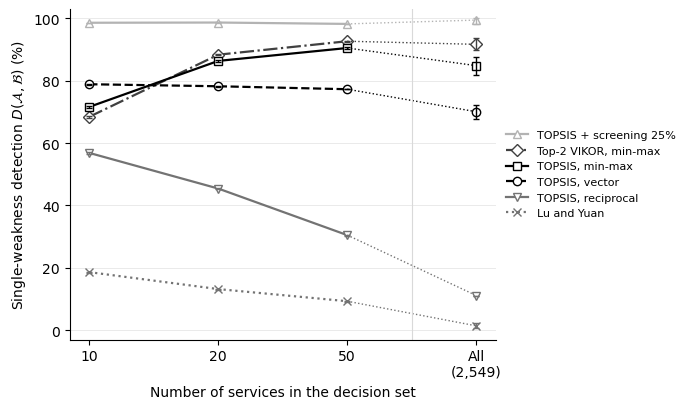

In [94]:
# Run after the Step 5 cell. Reads files the notebook writes in its own folder.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
res = pd.read_csv('step5_size_per_seed.csv')
res = res[(res.Weights == 'fixed') & (res.Metric == 'D(A,B)')]
seed = res.groupby(['Ns', 'Method', 'Seed'])['Rate'].mean().reset_index()
main = pd.read_csv('e2_main_per_seed.csv')[['Seed', 'Method', 'A above B %']].rename(columns={'A above B %': 'Rate'})
ly = pd.read_csv('e2_ly2018_per_seed.csv')
ly = ly[ly.iloc[:, 0] == 'main'].reset_index(drop=True)
ly = pd.DataFrame({'Seed': range(20), 'Method': 'Lu & Yuan exact', 'Rate': ly['A above B %'].values})
full = pd.concat([main, ly]); full['Ns'] = 2549
seed = pd.concat([seed, full[seed.columns]])
rb = np.random.default_rng(2026)
def ci(v):
    m = v[rb.integers(0, len(v), (10000, len(v)))].mean(1); return np.percentile(m, [2.5, 97.5])
series = [('TOPSIS + veto 25%', 'TOPSIS + screening 25%', '^', '-', '0.7'),
          ('VIKOR k=2 [minmax]', 'Top-2 VIKOR, min-max', 'D', '-.', '0.25'),
          ('TOPSIS [minmax]', 'TOPSIS, min-max', 's', '-', '0.0'),
          ('TOPSIS [vector]', 'TOPSIS, vector', 'o', '--', '0.0'),
          ('TOPSIS [reciprocal]', 'TOPSIS, reciprocal', 'v', '-', '0.45'),
          ('Lu & Yuan exact', 'Lu and Yuan', 'x', ':', '0.45')]
xs = [10, 20, 50, 2549]; pos = np.arange(4)
fig, ax = plt.subplots(figsize=(7.0, 4.2))
rows = []
for key, lab, mk, ls, col in series:
    mu, lo, hi = [], [], []
    for Ns in xs:
        v = seed[(seed.Ns == Ns) & (seed.Method == key)]['Rate'].values
        a, b = ci(v); mu.append(v.mean()); lo.append(a); hi.append(b)
        rows.append({'Method': lab, 'Ns': Ns, 'Mean': round(v.mean(), 1), 'CI low': round(a, 1), 'CI high': round(b, 1)})
    mu, lo, hi = map(np.array, (mu, lo, hi))
    ax.plot(pos[:3], mu[:3], ls=ls, color=col, lw=1.6, marker=mk, ms=6, mfc='white' if mk in 'osvD^' else col, label=lab)
    ax.plot(pos[2:], mu[2:], ls=':', color=col, lw=1.0)
    ax.plot(pos[3], mu[3], marker=mk, ms=6, color=col, mfc='white' if mk in 'osvD^' else col, ls='none')
    ax.errorbar(pos, mu, yerr=[mu - lo, hi - mu], fmt='none', ecolor=col, elinewidth=1, capsize=2)
ax.set_xticks(pos); ax.set_xticklabels(['10', '20', '50', 'All\n(2,549)'])
ax.set_xlabel('Number of services in the decision set')
ax.set_ylabel(r'Single-weakness detection $D(\mathcal{A},\mathcal{B})$ (%)')
ax.set_ylim(-3, 103); ax.axvline(2.5, color='0.85', lw=0.8)
ax.grid(axis='y', color='0.9', lw=0.6); ax.set_axisbelow(True)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc='center left', bbox_to_anchor=(1.0, 0.5))
fig.tight_layout(); fig.savefig('fig_size.pdf'); fig.savefig('fig_size.png', dpi=200)
pd.DataFrame(rows).to_csv('step5_figure_data.csv', index=False)
print(pd.DataFrame(rows).pivot(index='Method', columns='Ns', values='Mean'))

In [95]:
# ============================================================
# Step 6 - same-function case study (keyword groups, dictionary frozen in groups.py before ranking)
# (a) planted pair inside each group: group services + 1 balanced (A) + 1 test service (B_j, C or E),
#     planted from the GLOBAL quantiles; weights and log rule fixed from the full data.
# (b) real weaknesses: real services of the group below the global 5th percentile on >= 1 criterion;
#     how many of them each method places in the group's top 3 (no planted services).
# Uses the batched functions of step5_analysis.py (tlog, norm_b, topsis_b, vikor_b, ly_b, all_methods, thr).
# ============================================================
# Run after the Step 5 cell (it reuses tlog, norm_b, topsis_b, vikor_b, ly_b, all_methods, thr, cost).
import numpy as np, pandas as pd
import re
# Keyword dictionary, fixed BEFORE any ranking. Priority = order of the groups (first match wins).
DICT = [
 ('Messaging',      ['sms', 'email', 'mail', 'fax', 'messenger', 'messaging', 'message', 'send', 'pager', 'chat']),
 ('Finance',        ['stock', 'stocks', 'quote', 'quotes', 'currency', 'exchange', 'bank', 'banking', 'tax', 'rates',
                     'xignite', 'finance', 'financial', 'payment', 'credit', 'loan', 'fund', 'funds', 'market']),
 ('Weather & time', ['weather', 'forecast', 'ndfd', 'temperature', 'time', 'holiday', 'holidays', 'calendar', 'clock', 'timezone']),
 ('Location',       ['address', 'geo', 'geocode', 'geocoder', 'zip', 'zipcode', 'postal', 'map', 'maps', 'landmark',
                     'place', 'places', 'route', 'terra', 'census', 'country', 'location', 'distance', 'gis', 'city']),
 ('News & content', ['news', 'syndication', 'blog', 'rss', 'feed', 'article', 'articles', 'headline', 'headlines']),
 ('Validation',     ['verification', 'verify', 'validation', 'validate', 'validator', 'check', 'checker', 'phone']),
 ('Search',         ['search', 'google', 'finder', 'lookup', 'query', 'directory', 'yellow']),
 ('Commerce',       ['amazon', 'awse', 'commerce', 'ecommerce', 'order', 'catalog', 'shop', 'shopping', 'cart', 'product', 'products', 'auction']),
 ('Bioinformatics', ['blast', 'compound', 'sequence', 'protein', 'gene', 'genome', 'emboss', 'fasta', 'dna', 'ebi', 'pdb', 'kegg', 'chem', 'molecule']),
 ('Calculation',    ['math', 'calculator', 'calc', 'convert', 'converter', 'conversion', 'unit', 'units', 'random', 'number']),
]
def tok(s):
    s = re.sub(r'([a-z])([A-Z])', r'\1 \2', str(s)); s = re.sub(r'([A-Z]+)([A-Z][a-z])', r'\1 \2', s)
    return {w.lower() for w in re.split(r'[^A-Za-z]+', s) if w}
def assign(name):
    t = tok(name)
    for g, kws in DICT:
        if t & set(kws): return g
    return None
df_g = df.copy(); df_g['Group'] = df_g.ServiceName.map(assign)   # df = QWS data loaded in Step 1 of the notebook
groups = {g: np.where(df_g.Group.values == g)[0] for g, _ in DICT if (df_g.Group == g).sum() >= 10}
print({g: len(ix) for g, ix in groups.items()})

def planted_level(level, rng):
    lv = np.clip(level + rng.uniform(-0.03, 0.03, n), 0.001, 0.999)
    return np.array([np.quantile(X[:, j], 1 - lv[j] if cost[j] else lv[j]) for j in range(n)])
def test_level(tt, rng):
    lv = np.full(n, 0.90)
    if tt.startswith('B'): lv[int(tt[1:])] = 0.02
    elif tt == 'C': lv[rng.choice(n, 3, replace=False)] = 0.20
    elif tt == 'E': lv = np.full(n, 0.95); lv[rng.choice(n)] = 0.40
    return lv

TYPES = [f'B{j}' for j in range(n)] + ['C', 'E']
REPS = 10
rows = []
for g, gix in groups.items():
    G = X[gix]
    for seed in range(20):
        rng = np.random.default_rng(seed)
        for tt in TYPES:
            mats = np.stack([np.vstack([G, planted_level(np.full(n, 0.80), rng), planted_level(test_level(tt, rng), rng)])
                             for _ in range(REPS)])
            for meth, hit in all_methods(mats, w_final).items():
                rate = 100 * hit.mean()
                if tt == 'E': rate = 100 - rate            # convert 'A above E' to D(E,A); continuous scores, no ties
                rows.append({'Group': g, 'n': len(gix), 'Seed': seed, 'Test': tt, 'Method': meth, 'Rate': rate})
res = pd.DataFrame(rows)
res['Metric'] = np.where(res.Test.str.startswith('B'), 'D(A,B)', np.where(res.Test == 'C', 'D(A,C)', 'D(E,A)'))
res.to_csv('step6_groups_per_seed.csv', index=False)
seed_lvl = res.groupby(['Group', 'n', 'Method', 'Metric', 'Seed'])['Rate'].mean()
summ = seed_lvl.groupby(['Group', 'n', 'Method', 'Metric']).mean().unstack('Metric').round(1)
summ.to_csv('step6_groups_summary.csv')

KEY = ['Lu & Yuan exact', 'TOPSIS [reciprocal]', 'TOPSIS [vector]', 'TOPSIS [minmax]', 'VIKOR k=2 [minmax]', 'TOPSIS + veto 25%', 'Max-min']
pd.set_option('display.width', 220)
tabB = summ['D(A,B)'].unstack('Method')[KEY]
print('\nD(A,B) by group:'); print(tabB)
print('\nD(A,C) by group:'); print(summ['D(A,C)'].unstack('Method')[KEY])
print('\nD(E,A) by group:'); print(summ['D(E,A)'].unstack('Method')[KEY])
# how many groups: linear beats reciprocal (seed-level CI across seeds per group)
rb = np.random.default_rng(2026)
cmp = []
for g in groups:
    w_ = seed_lvl.loc[g].xs('D(A,B)', level='Metric').unstack('Method').droplevel(0) if False else \
         seed_lvl.xs(g, level='Group').xs('D(A,B)', level='Metric').unstack('Method')
    for b in ['TOPSIS [vector]', 'TOPSIS [minmax]']:
        d = (w_[b] - w_['TOPSIS [reciprocal]']).values
        m = d[rb.integers(0, len(d), (10000, len(d)))].mean(1)
        cmp.append({'Group': g, 'Contrast': f'{b} - reciprocal', 'Mean': round(d.mean(), 1),
                    'CI': f'[{np.percentile(m, 2.5):.1f}, {np.percentile(m, 97.5):.1f}]', 'Seeds +/-': f'{(d > 0).sum()}/{(d < 0).sum()}'})
cmp = pd.DataFrame(cmp); cmp.to_csv('step6_groups_contrasts.csv', index=False)
print('\nContrasts per group:'); print(cmp.to_string(index=False))

# ---------- (b) real weaknesses in each group's top 3 ----------
pct = pd.DataFrame(X).rank(pct=True).values.copy(); pct[:, cost] = 1 - pct[:, cost] + 1.0 / N   # 1 = best
weak_flag = (pct < 0.05).any(1)
def scores(Xs):
    Y = tlog(Xs[None]); w = w_final; out = {}
    for kind in ['reciprocal', 'vector', 'minmax']:
        out[f'TOPSIS [{kind}]'] = -topsis_b(norm_b(Y, kind), w)[0]
    Rmm = norm_b(Y, 'minmax')
    out['VIKOR k=2 [minmax]'] = vikor_b(Rmm, w, 2)[0]
    out['Max-min'] = -Rmm.min(2)[0]
    veto = np.where(cost, Y > thr, Y < thr).any(2)[0]
    out['TOPSIS + veto 25%'] = -topsis_b(Rmm, w)[0] + 10 * veto
    out['Lu & Yuan exact'] = -ly_b(Xs[None])[0]
    return out                                                      # lower = better
real = []
for g, gix in groups.items():
    sc = scores(X[gix])
    for meth, s in sc.items():
        top = np.argsort(s, kind='stable')[:3]
        real.append({'Group': g, 'n': len(gix), 'Weak services in group': int(weak_flag[gix].sum()),
                     'Method': meth, 'Weak in top 3': int(weak_flag[gix][top].sum())})
real = pd.DataFrame(real); real.to_csv('step6_real_top3.csv', index=False)
rt = real.pivot_table(index=['Group', 'n', 'Weak services in group'], columns='Method', values='Weak in top 3')[KEY]
print('\nReal services below the 5th percentile on >= 1 criterion, placed in the group top 3:'); print(rt)
print('\nTotal over groups:'); print(rt.sum())

{'Messaging': 65, 'Finance': 80, 'Weather & time': 44, 'Location': 117, 'News & content': 40, 'Validation': 38, 'Search': 125, 'Commerce': 49, 'Bioinformatics': 31, 'Calculation': 39}

D(A,B) by group:
Method              Lu & Yuan exact  TOPSIS [reciprocal]  TOPSIS [vector]  TOPSIS [minmax]  VIKOR k=2 [minmax]  TOPSIS + veto 25%  Max-min
Group          n                                                                                                                          
Bioinformatics 31              12.7                 28.4             72.6             90.2                90.3              100.0    100.0
Calculation    39              11.1                 51.6             73.7             11.6                42.1               97.3    100.0
Commerce       49              10.1                 22.9             79.3             48.3                71.1               97.3    100.0
Finance        80               2.1                 32.8             70.7             59.3             

In [96]:
import pandas as pd, re
# Keyword dictionary, fixed BEFORE any ranking. Priority = order of the groups (first match wins).
DICT = [
 ('Messaging',      ['sms', 'email', 'mail', 'fax', 'messenger', 'messaging', 'message', 'send', 'pager', 'chat']),
 ('Finance',        ['stock', 'stocks', 'quote', 'quotes', 'currency', 'exchange', 'bank', 'banking', 'tax', 'rates',
                     'xignite', 'finance', 'financial', 'payment', 'credit', 'loan', 'fund', 'funds', 'market']),
 ('Weather & time', ['weather', 'forecast', 'ndfd', 'temperature', 'time', 'holiday', 'holidays', 'calendar', 'clock', 'timezone']),
 ('Location',       ['address', 'geo', 'geocode', 'geocoder', 'zip', 'zipcode', 'postal', 'map', 'maps', 'landmark',
                     'place', 'places', 'route', 'terra', 'census', 'country', 'location', 'distance', 'gis', 'city']),
 ('News & content', ['news', 'syndication', 'blog', 'rss', 'feed', 'article', 'articles', 'headline', 'headlines']),
 ('Validation',     ['verification', 'verify', 'validation', 'validate', 'validator', 'check', 'checker', 'phone']),
 ('Search',         ['search', 'google', 'finder', 'lookup', 'query', 'directory', 'yellow']),
 ('Commerce',       ['amazon', 'awse', 'commerce', 'ecommerce', 'order', 'catalog', 'shop', 'shopping', 'cart', 'product', 'products', 'auction']),
 ('Bioinformatics', ['blast', 'compound', 'sequence', 'protein', 'gene', 'genome', 'emboss', 'fasta', 'dna', 'ebi', 'pdb', 'kegg', 'chem', 'molecule']),
 ('Calculation',    ['math', 'calculator', 'calc', 'convert', 'converter', 'conversion', 'unit', 'units', 'random', 'number']),
]
def tok(s):
    s = re.sub(r'([a-z])([A-Z])', r'\1 \2', str(s)); s = re.sub(r'([A-Z]+)([A-Z][a-z])', r'\1 \2', s)
    return {w.lower() for w in re.split(r'[^A-Za-z]+', s) if w}
def assign(name):
    t = tok(name)
    for g, kws in DICT:
        if t & set(kws): return g
    return None
if __name__ == '__main__':
    d = pd.read_csv('qws.xls'); d['Group'] = d.ServiceName.map(assign)
    print(d.Group.value_counts(dropna=False))
    for g in d.Group.dropna().unique():
        print(g, '|', ', '.join(d[d.Group == g].ServiceName.sample(min(12, (d.Group == g).sum()), random_state=1)))

Group
None              1872
Search             125
Location           117
Finance             80
Messaging           65
Commerce            49
Weather & time      44
News & content      40
Calculation         39
Validation          38
Bioinformatics      31
Name: count, dtype: int64
Search | TraceFinder3BPService, QueryDeathIndex, GoogleSearchService, GoogleSearchService, JurisdictionLookupService, GoogleSearchService, GoogleSearchService, AmazonSearchService, GoogleSearchService, Image_x0020_Search, GoogleSearchService, SpatialQuery
Validation | XmlHttpCheck, DOTSPhoneAppend, ValidateService, SpamCheckerService, PhoneInteligence2, Validator, RestrictedCheckTickets, PhoneNumberEnhancement, MSIT_MedStudentResidentValidation, CheckItOutClassService, ValidationService, DOTSContactValidation
News & content | NewsServices, news_xml_service, NewsReaderService, RSSService, Articles, NRA_x0020_ILA_x0020_News_x0020_Syndication, BlogBrowserService, BlogReaderService, NewsSearchService, ASPNNews